# Final nested-CV evidence and article-ready scientific results

**Scientific goal.** Synthesize the frozen primary-study evidence without retraining. **Input from Notebooks 03–05.** Identical outer-OOF predictions, fold timing, FA-ATF ablations, specimen-aware group-cross-fitted residual intervals, and alternative specimen-split stability. **Allowed data.** Saved artifacts derived only from the primary 51CrV4 experiment; no model, feature, threshold, or architecture selection occurs here. **Methods.** Target-wise metrics, paired inference, uncertainty assessment, robustness analysis, explainability, and sensitivity analysis. **Final output.** Evidence-bounded tables, figures, conclusions, and limitations for the investigated factorial domain.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain.


## Evidence boundary

The joint FA-ATF comparison uses 27 specimen groups and 81 genuine outer-OOF predictions for every model–target pair. Repartitioning these 81 rows would not create independent validation. No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Internal robustness does not replace independent validation, which remains a prospective requirement.


## 1. Environment and frozen artifact inputs

In [1]:
from pathlib import Path
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
SEED = 20260820
REQUIRED_FONT = "Times New Roman"
FONT_SIZE_MIN = 16
FONT_SIZE_MAX = 18
FIGURE_DPI = 350
RUN_ID = "FA_ATF_DaKS69_Exploratory_20260820"

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "dataset" / "raw"
UNIFIED_DIR = ROOT / "dataset" / "unified"
RUN_ROOT = ROOT / "artifacts" / RUN_ID
TABLE_ROOT = RUN_ROOT / "Tables"
FIGURE_PNG_DIR = RUN_ROOT / "Figures" / "PNG"
FIGURE_PDF_DIR = RUN_ROOT / "Figures" / "PDF"
FIGURE_SOURCE_DIR = RUN_ROOT / "Tables" / "Figure_Source_Data"
MODEL_DIR = RUN_ROOT / "Models"
PREDICTION_DIR = RUN_ROOT / "Tables" / "Predictions"
METRIC_DIR = RUN_ROOT / "Tables" / "Metrics"
STATISTICS_DIR = RUN_ROOT / "Tables" / "Statistics"
AUDIT_DIR = RUN_ROOT / "Tables" / "Audit"

for directory in (
    RAW_DIR, UNIFIED_DIR, RUN_ROOT, TABLE_ROOT, FIGURE_PNG_DIR, FIGURE_PDF_DIR,
    FIGURE_SOURCE_DIR, MODEL_DIR, PREDICTION_DIR,
    METRIC_DIR, STATISTICS_DIR, AUDIT_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)


In [2]:
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
if REQUIRED_FONT not in available_fonts:
    raise RuntimeError("Times New Roman is unavailable; publication figures cannot be generated.")

mpl.rcParams.update({
    "font.family": REQUIRED_FONT,
    "font.serif": [REQUIRED_FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": REQUIRED_FONT,
    "mathtext.it": REQUIRED_FONT + ":italic",
    "mathtext.bf": REQUIRED_FONT + ":bold",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "figure.dpi": FIGURE_DPI,
    "savefig.dpi": FIGURE_DPI,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "axes.unicode_minus": True,
    "grid.color": "#E7EAED",
    "grid.alpha": 0.80,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

PALETTE = {
    "blue": "#2F6B8F", "orange": "#C77C2B", "green": "#4F7F3A",
    "purple": "#6D5A8D", "red": "#B45A55", "gray": "#6E7378",
    "light_gray": "#E7EAED", "teal": "#4A8C8A", "gold": "#C9A227",
    "black": "#222222", "white": "#FFFFFF",
}

def format_scientific_number(value, decimals=2, show_plus=False):
    """Format signed values with U+2212 and suppress rounded negative zero."""
    rounded_value = round(float(value), decimals)
    if rounded_value == 0.0:
        return f"{0.0:.{decimals}f}"
    format_specifier = f"+.{decimals}f" if show_plus else f".{decimals}f"
    return format(rounded_value, format_specifier).replace("-", "−")

def display_complete_table(frame, title=None):
    if title:
        print(title)
    with pd.option_context(
        "display.max_rows", len(frame), "display.max_columns", len(frame.columns),
        "display.max_colwidth", None, "display.width", None,
    ):
        display(frame)

def validate_figure_typography(fig):
    fig.canvas.draw()
    violations = []
    for text_object in fig.findobj(match=mpl.text.Text):
        if not text_object.get_text().strip():
            continue
        size = float(text_object.get_fontsize())
        resolved_name = text_object.get_fontproperties().get_name()
        if resolved_name != REQUIRED_FONT:
            violations.append(f"font={resolved_name!r}: {text_object.get_text()!r}")
        if not (FONT_SIZE_MIN <= size <= FONT_SIZE_MAX):
            violations.append(f"fontsize={size}: {text_object.get_text()!r}")
    if violations:
        raise AssertionError("Typography QA failed:\n" + "\n".join(violations))

def save_scientific_figure(fig, stem, source_frame):
    source_path = FIGURE_SOURCE_DIR / f"{stem}.csv"
    png_path = FIGURE_PNG_DIR / f"{stem}.png"
    source_frame.to_csv(source_path, index=False)
    validate_figure_typography(fig)
    fig.savefig(png_path, dpi=FIGURE_DPI, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    return png_path, None, source_path


In [3]:
# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))

from PIL import Image as PILImage
from scipy.stats import rankdata, wilcoxon
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = UNIFIED_DIR / "modeling_dataset.csv"
data = pd.read_csv(DATA_PATH)
baseline = pd.read_csv(PREDICTION_DIR / "baseline_oof_predictions.csv")
modern = pd.read_csv(PREDICTION_DIR / "modern_oof_predictions.csv")
proposed = pd.read_csv(PREDICTION_DIR / "fa_atf_oof_predictions.csv")
ablations = pd.read_csv(PREDICTION_DIR / "fa_atf_ablation_oof_predictions.csv")
uncertainty = pd.read_csv(PREDICTION_DIR / "fa_atf_uncertainty_oof.csv")
weights = pd.read_csv(METRIC_DIR / "fa_atf_fold_weights.csv")
alternative_split_summary = pd.read_csv(METRIC_DIR / "alternative_group_split_summary.csv")
expert_outer = pd.read_csv(PREDICTION_DIR / "fa_atf_expert_outer_oof.csv")

all_predictions = pd.concat([baseline, modern, proposed], ignore_index=True, sort=False)
TARGETS = ["surface_roughness_Ra_um", "post_process_hardness_HV30"]
TARGET_LABELS = {
    TARGETS[0]: "Surface roughness Ra (µm)",
    TARGETS[1]: "Post-process hardness (HV30)",
}
TARGET_SCALES = data[TARGETS].std(ddof=1).to_dict()
N_BOOTSTRAP = 2000

pair_counts = all_predictions.groupby(["model", "target"]).sample_id.nunique()
if pair_counts.min() != 81 or pair_counts.max() != 81:
    raise RuntimeError("Every frozen model-target pair must contain 81 OOF observations.")
if all_predictions[["y_true", "y_pred"]].isna().any().any():
    raise RuntimeError("Frozen OOF predictions contain missing values.")
all_predictions.to_csv(PREDICTION_DIR / "all_models_oof_predictions.csv", index=False)

evidence_design = pd.DataFrame([
    {"Evidence property": "Experimental design", "Observed design": "Balanced hierarchical split-plot factorial design"},
    {"Evidence property": "Prediction unit", "Observed design": "81 section-level outer-OOF predictions per model-target"},
    {"Evidence property": "Resampling / inferential unit", "Observed design": "27 physical specimens"},
    {"Evidence property": "Outer / inner resampling", "Observed design": "9 specimen-group folds / 4 specimen-group folds"},
    {"Evidence property": "Targets", "Observed design": "Ra (µm) and post-process hardness (HV30), reported separately"},
    {"Evidence property": "Overall ordering", "Observed design": "Mean target-wise NRMSE; macro R² secondary"},
    {"Evidence property": "Uncertainty", "Observed design": "95% specimen-cluster bootstrap intervals; nominal 90% group-cross-fitted residual intervals"},
    {"Evidence property": "Split-assignment robustness", "Observed design": "Five pre-specified alternative specimen-group assignments; not used for tuning"},
    {"Evidence property": "Independent validation", "Observed design": "Not performed; no methodologically compatible dataset with paired Ra/HV30 outcomes was identified"},
])
display_grouped_table(evidence_design, "Final evidence design")
display_grouped_table(alternative_split_summary.round(5), "Alternative group-split stability loaded from Notebook 05")


**Final evidence design — Complete table**

Evidence property,Observed design
Experimental design,Balanced hierarchical split-plot factorial design
Prediction unit,81 section-level outer-OOF predictions per model-target
Resampling / inferential unit,27 physical specimens
Outer / inner resampling,9 specimen-group folds / 4 specimen-group folds
Targets,"Ra (µm) and post-process hardness (HV30), reported separately"
Overall ordering,Mean target-wise NRMSE; macro R² secondary
Uncertainty,95% specimen-cluster bootstrap intervals; nominal 90% group-cross-fitted residual intervals
Split-assignment robustness,Five pre-specified alternative specimen-group assignments; not used for tuning
Independent validation,Not performed; no methodologically compatible dataset with paired Ra/HV30 outcomes was identified


**Alternative group-split stability loaded from Notebook 05 — Complete table (part 1/2)**

model,split_seeds,mean_NRMSE_across_assignments,SD_NRMSE_across_assignments,minimum_NRMSE,maximum_NRMSE
FA-ATF,5,0.427110,0.008970,0.417620,0.439890
HierarchicalMixedEffects,5,0.474930,0.007660,0.464260,0.482940
RandomForest,5,0.467070,0.007700,0.456030,0.477530


**Alternative group-split stability loaded from Notebook 05 — Complete table (part 2/2)**

model,median_rank
FA-ATF,1.000000
HierarchicalMixedEffects,3.000000
RandomForest,2.000000


## 2. Compute target-wise metrics and specimen-group bootstrap intervals

In [4]:
def metric_values(y_true, y_pred, scale):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        "MAE": mean_absolute_error(y_true, y_pred), "RMSE": rmse,
        "R2": r2_score(y_true, y_pred), "NRMSE": rmse / scale,
    }

model_names = sorted(all_predictions.model.unique())
model_index = {model: index for index, model in enumerate(model_names)}
rng = np.random.default_rng(SEED)
point_rows = []
bootstrap_by_target = {}

for target in TARGETS:
    part = all_predictions[all_predictions.target.eq(target)]
    prediction_wide = part.pivot(index="sample_id", columns="model", values="y_pred").reindex(columns=model_names)
    truth = part.groupby("sample_id").y_true.first().reindex(prediction_wide.index)
    sample_groups = data.set_index("sample_id").loc[prediction_wide.index, "specimen_id"]
    unique_groups = sample_groups.unique()

    for model in model_names:
        values = metric_values(truth.to_numpy(), prediction_wide[model].to_numpy(), TARGET_SCALES[target])
        point_rows.append({"model": model, "target": target, **values})

    bootstrap = {metric: np.empty((N_BOOTSTRAP, len(model_names))) for metric in ("MAE", "RMSE", "R2", "NRMSE")}
    group_positions = {group: np.flatnonzero(sample_groups.to_numpy() == group) for group in unique_groups}
    for bootstrap_index in range(N_BOOTSTRAP):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        positions = np.concatenate([group_positions[group] for group in sampled_groups])
        y_boot = truth.to_numpy()[positions]
        p_boot = prediction_wide.to_numpy()[positions]
        bootstrap["MAE"][bootstrap_index] = np.mean(np.abs(y_boot[:, None] - p_boot), axis=0)
        rmse_boot = np.sqrt(np.mean((y_boot[:, None] - p_boot) ** 2, axis=0))
        bootstrap["RMSE"][bootstrap_index] = rmse_boot
        bootstrap["NRMSE"][bootstrap_index] = rmse_boot / TARGET_SCALES[target]
        denominator = np.sum((y_boot - y_boot.mean()) ** 2)
        bootstrap["R2"][bootstrap_index] = 1.0 - np.sum((y_boot[:, None] - p_boot) ** 2, axis=0) / max(denominator, 1e-12)
    bootstrap_by_target[target] = bootstrap

target_metrics = pd.DataFrame(point_rows)
for metric in ("MAE", "RMSE", "R2", "NRMSE"):
    lows, highs = [], []
    for _, row in target_metrics.iterrows():
        values = bootstrap_by_target[row.target][metric][:, model_index[row.model]]
        lows.append(np.quantile(values, 0.025))
        highs.append(np.quantile(values, 0.975))
    target_metrics[f"{metric}_CI_low"] = lows
    target_metrics[f"{metric}_CI_high"] = highs

target_metrics.to_csv(METRIC_DIR / "final_target_metrics_with_group_bootstrap_ci.csv", index=False)
display_grouped_table(target_metrics[target_metrics.target.eq(TARGETS[0])].sort_values("NRMSE").round(4), "Ra metrics with group-bootstrap intervals")
display_grouped_table(target_metrics[target_metrics.target.eq(TARGETS[1])].sort_values("NRMSE").round(4), "HV30 metrics with group-bootstrap intervals")

**Ra metrics with group-bootstrap intervals — models 1-12 in displayed order — Predictive performance (part 1/3)**

model,target,MAE,RMSE,R2,NRMSE,MAE_CI_low
FA-ATF,surface_roughness_Ra_um,0.219100,0.356400,0.823100,0.418000,0.128400
Residual MLP,surface_roughness_Ra_um,0.250200,0.396900,0.780600,0.465500,0.151000
MultiTask MLP,surface_roughness_Ra_um,0.278100,0.408200,0.767900,0.478800,0.180700
RandomForest,surface_roughness_Ra_um,0.220500,0.416900,0.757900,0.488900,0.107000
LinearRegression,surface_roughness_Ra_um,0.255400,0.418800,0.755800,0.491100,0.158100
Ridge,surface_roughness_Ra_um,0.263100,0.422700,0.751200,0.495700,0.164900
ElasticNet,surface_roughness_Ra_um,0.261100,0.423600,0.750100,0.496800,0.161500
PolynomialRidge,surface_roughness_Ra_um,0.287000,0.427200,0.745800,0.501100,0.183800
ExtraTrees,surface_roughness_Ra_um,0.239000,0.437700,0.733200,0.513400,0.119700
CatBoost,surface_roughness_Ra_um,0.243300,0.441000,0.729100,0.517300,0.129400


**Ra metrics with group-bootstrap intervals — models 1-12 in displayed order — Predictive performance (part 2/3)**

model,target,MAE_CI_high,RMSE_CI_low,RMSE_CI_high,R2_CI_low,R2_CI_high
FA-ATF,surface_roughness_Ra_um,0.331200,0.192800,0.510300,0.709200,0.926500
Residual MLP,surface_roughness_Ra_um,0.375000,0.203400,0.561300,0.606800,0.905500
MultiTask MLP,surface_roughness_Ra_um,0.397000,0.235300,0.567300,0.630500,0.877200
RandomForest,surface_roughness_Ra_um,0.362800,0.167900,0.614900,0.585500,0.945900
LinearRegression,surface_roughness_Ra_um,0.390300,0.211500,0.610900,0.526300,0.916300
Ridge,surface_roughness_Ra_um,0.399900,0.211200,0.620100,0.519700,0.915700
ElasticNet,surface_roughness_Ra_um,0.399000,0.209800,0.621800,0.517400,0.916700
PolynomialRidge,surface_roughness_Ra_um,0.414400,0.247800,0.597100,0.599400,0.873300
ExtraTrees,surface_roughness_Ra_um,0.386700,0.205400,0.637200,0.560300,0.910700
CatBoost,surface_roughness_Ra_um,0.400400,0.178200,0.677000,0.510500,0.936600


**Ra metrics with group-bootstrap intervals — models 1-12 in displayed order — Predictive performance (part 3/3)**

model,target,NRMSE_CI_low,NRMSE_CI_high
FA-ATF,surface_roughness_Ra_um,0.226100,0.598500
Residual MLP,surface_roughness_Ra_um,0.238600,0.658400
MultiTask MLP,surface_roughness_Ra_um,0.276000,0.665300
RandomForest,surface_roughness_Ra_um,0.196900,0.721200
LinearRegression,surface_roughness_Ra_um,0.248000,0.716600
Ridge,surface_roughness_Ra_um,0.247700,0.727400
ElasticNet,surface_roughness_Ra_um,0.246100,0.729300
PolynomialRidge,surface_roughness_Ra_um,0.290700,0.700300
ExtraTrees,surface_roughness_Ra_um,0.240900,0.747300
CatBoost,surface_roughness_Ra_um,0.209000,0.794100


... (14 outputs left out)

**HV30 metrics with group-bootstrap intervals — models 13-18 in displayed order — Predictive performance (part 2/3)**

model,target,MAE_CI_high,RMSE_CI_low,RMSE_CI_high,R2_CI_low,R2_CI_high
GaussianProcess,post_process_hardness_HV30,18.341200,15.435800,21.971400,0.724700,0.881900
ElasticNet,post_process_hardness_HV30,20.585900,17.147500,24.329800,0.648700,0.858400
SVR-RBF,post_process_hardness_HV30,20.418100,17.985300,23.814200,0.693400,0.838300
Ridge,post_process_hardness_HV30,20.758800,17.365200,24.664500,0.636300,0.858700
LinearRegression,post_process_hardness_HV30,20.999000,17.471600,25.114700,0.614200,0.856200
DummyRegressor,post_process_hardness_HV30,47.306800,39.124100,51.541600,-0.223600,0.002000


**HV30 metrics with group-bootstrap intervals — models 13-18 in displayed order — Predictive performance (part 3/3)**

model,target,NRMSE_CI_low,NRMSE_CI_high
GaussianProcess,post_process_hardness_HV30,0.338300,0.481600
ElasticNet,post_process_hardness_HV30,0.375800,0.533300
SVR-RBF,post_process_hardness_HV30,0.394200,0.522000
Ridge,post_process_hardness_HV30,0.380600,0.540600
LinearRegression,post_process_hardness_HV30,0.382900,0.550500
DummyRegressor,post_process_hardness_HV30,0.857500,1.129700


Target-wise physical-unit metrics are kept separate because a micrometre error in Ra is not commensurate with an HV30 error. The 95% intervals resample whole specimens, preserving the experimental dependence structure. Wide intervals are expected with only 27 independent groups and must constrain comparative claims.


## 3. Build the dimensionless overall ranking

In [5]:
overall_bootstrap = np.mean(np.stack([
    bootstrap_by_target[target]["NRMSE"] for target in TARGETS
], axis=2), axis=2)

model_family = all_predictions.groupby("model").model_family.first().to_dict()
ranking = target_metrics.groupby("model", as_index=False).agg(
    mean_NRMSE=("NRMSE", "mean"), macro_R2=("R2", "mean")
)
ranking["mean_NRMSE_CI_low"] = [
    np.quantile(overall_bootstrap[:, model_index[model]], 0.025) for model in ranking.model
]
ranking["mean_NRMSE_CI_high"] = [
    np.quantile(overall_bootstrap[:, model_index[model]], 0.975) for model in ranking.model
]
ranking["model_family"] = ranking.model.map(model_family)
ranking = ranking.sort_values(["mean_NRMSE", "model"]).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
ranking.to_csv(METRIC_DIR / "final_dimensionless_model_ranking.csv", index=False)
display_grouped_table(ranking.round(4), "Dimensionless all-model ranking")

**Dimensionless all-model ranking — model_family=Proposed — Complete table**

model,model_family,rank,mean_NRMSE,macro_R2,mean_NRMSE_CI_low,mean_NRMSE_CI_high
FA-ATF,Proposed,1,0.377300,0.854200,0.275000,0.474000


**Dimensionless all-model ranking — model_family=Compact deep learning — Complete table**

model,model_family,rank,mean_NRMSE,macro_R2,mean_NRMSE_CI_low,mean_NRMSE_CI_high
MultiTask MLP,Compact deep learning,2,0.414500,0.821800,0.309900,0.513300
Residual MLP,Compact deep learning,5,0.428700,0.812500,0.311000,0.528100
Compact FT-Transformer,Compact deep learning,11,0.475200,0.763800,0.307900,0.625700


**Dimensionless all-model ranking — model_family=Baseline — Complete table**

model,model_family,rank,mean_NRMSE,macro_R2,mean_NRMSE_CI_low,mean_NRMSE_CI_high
RandomForest,Baseline,3,0.416500,0.819000,0.270600,0.537300
ExtraTrees,Baseline,8,0.452500,0.789000,0.305800,0.576300
HistGradientBoosting,Baseline,9,0.454400,0.779400,0.296900,0.595400
PolynomialRidge,Baseline,10,0.454700,0.788500,0.340600,0.560500
ElasticNet,Baseline,12,0.477300,0.769000,0.341900,0.598800
Ridge,Baseline,13,0.479000,0.767400,0.345700,0.598500
LinearRegression,Baseline,14,0.480200,0.766400,0.348500,0.598000
HierarchicalMixedEffects,Baseline,15,0.482900,0.750800,0.319700,0.626600
SVR-RBF,Baseline,17,0.516200,0.726800,0.348400,0.654300
DummyRegressor,Baseline,18,1.017600,-0.048900,0.857000,1.175000


**Dimensionless all-model ranking — model_family=Modern classical — Complete table**

model,model_family,rank,mean_NRMSE,macro_R2,mean_NRMSE_CI_low,mean_NRMSE_CI_high
CatBoost,Modern classical,4,0.427400,0.806900,0.267100,0.571800
LightGBM,Modern classical,6,0.432900,0.801100,0.280200,0.561600
XGBoost,Modern classical,7,0.435800,0.799500,0.279200,0.573300
GaussianProcess,Modern classical,16,0.491600,0.748700,0.318000,0.631500


Mean target-wise NRMSE supplies the only joint ordering because it is dimensionless; macro R² is secondary. A first-place point estimate does not establish superiority unless paired uncertainty and multiplicity-adjusted tests support the same conclusion.


## 4. Visualize the identical-OOF ranking with group uncertainty

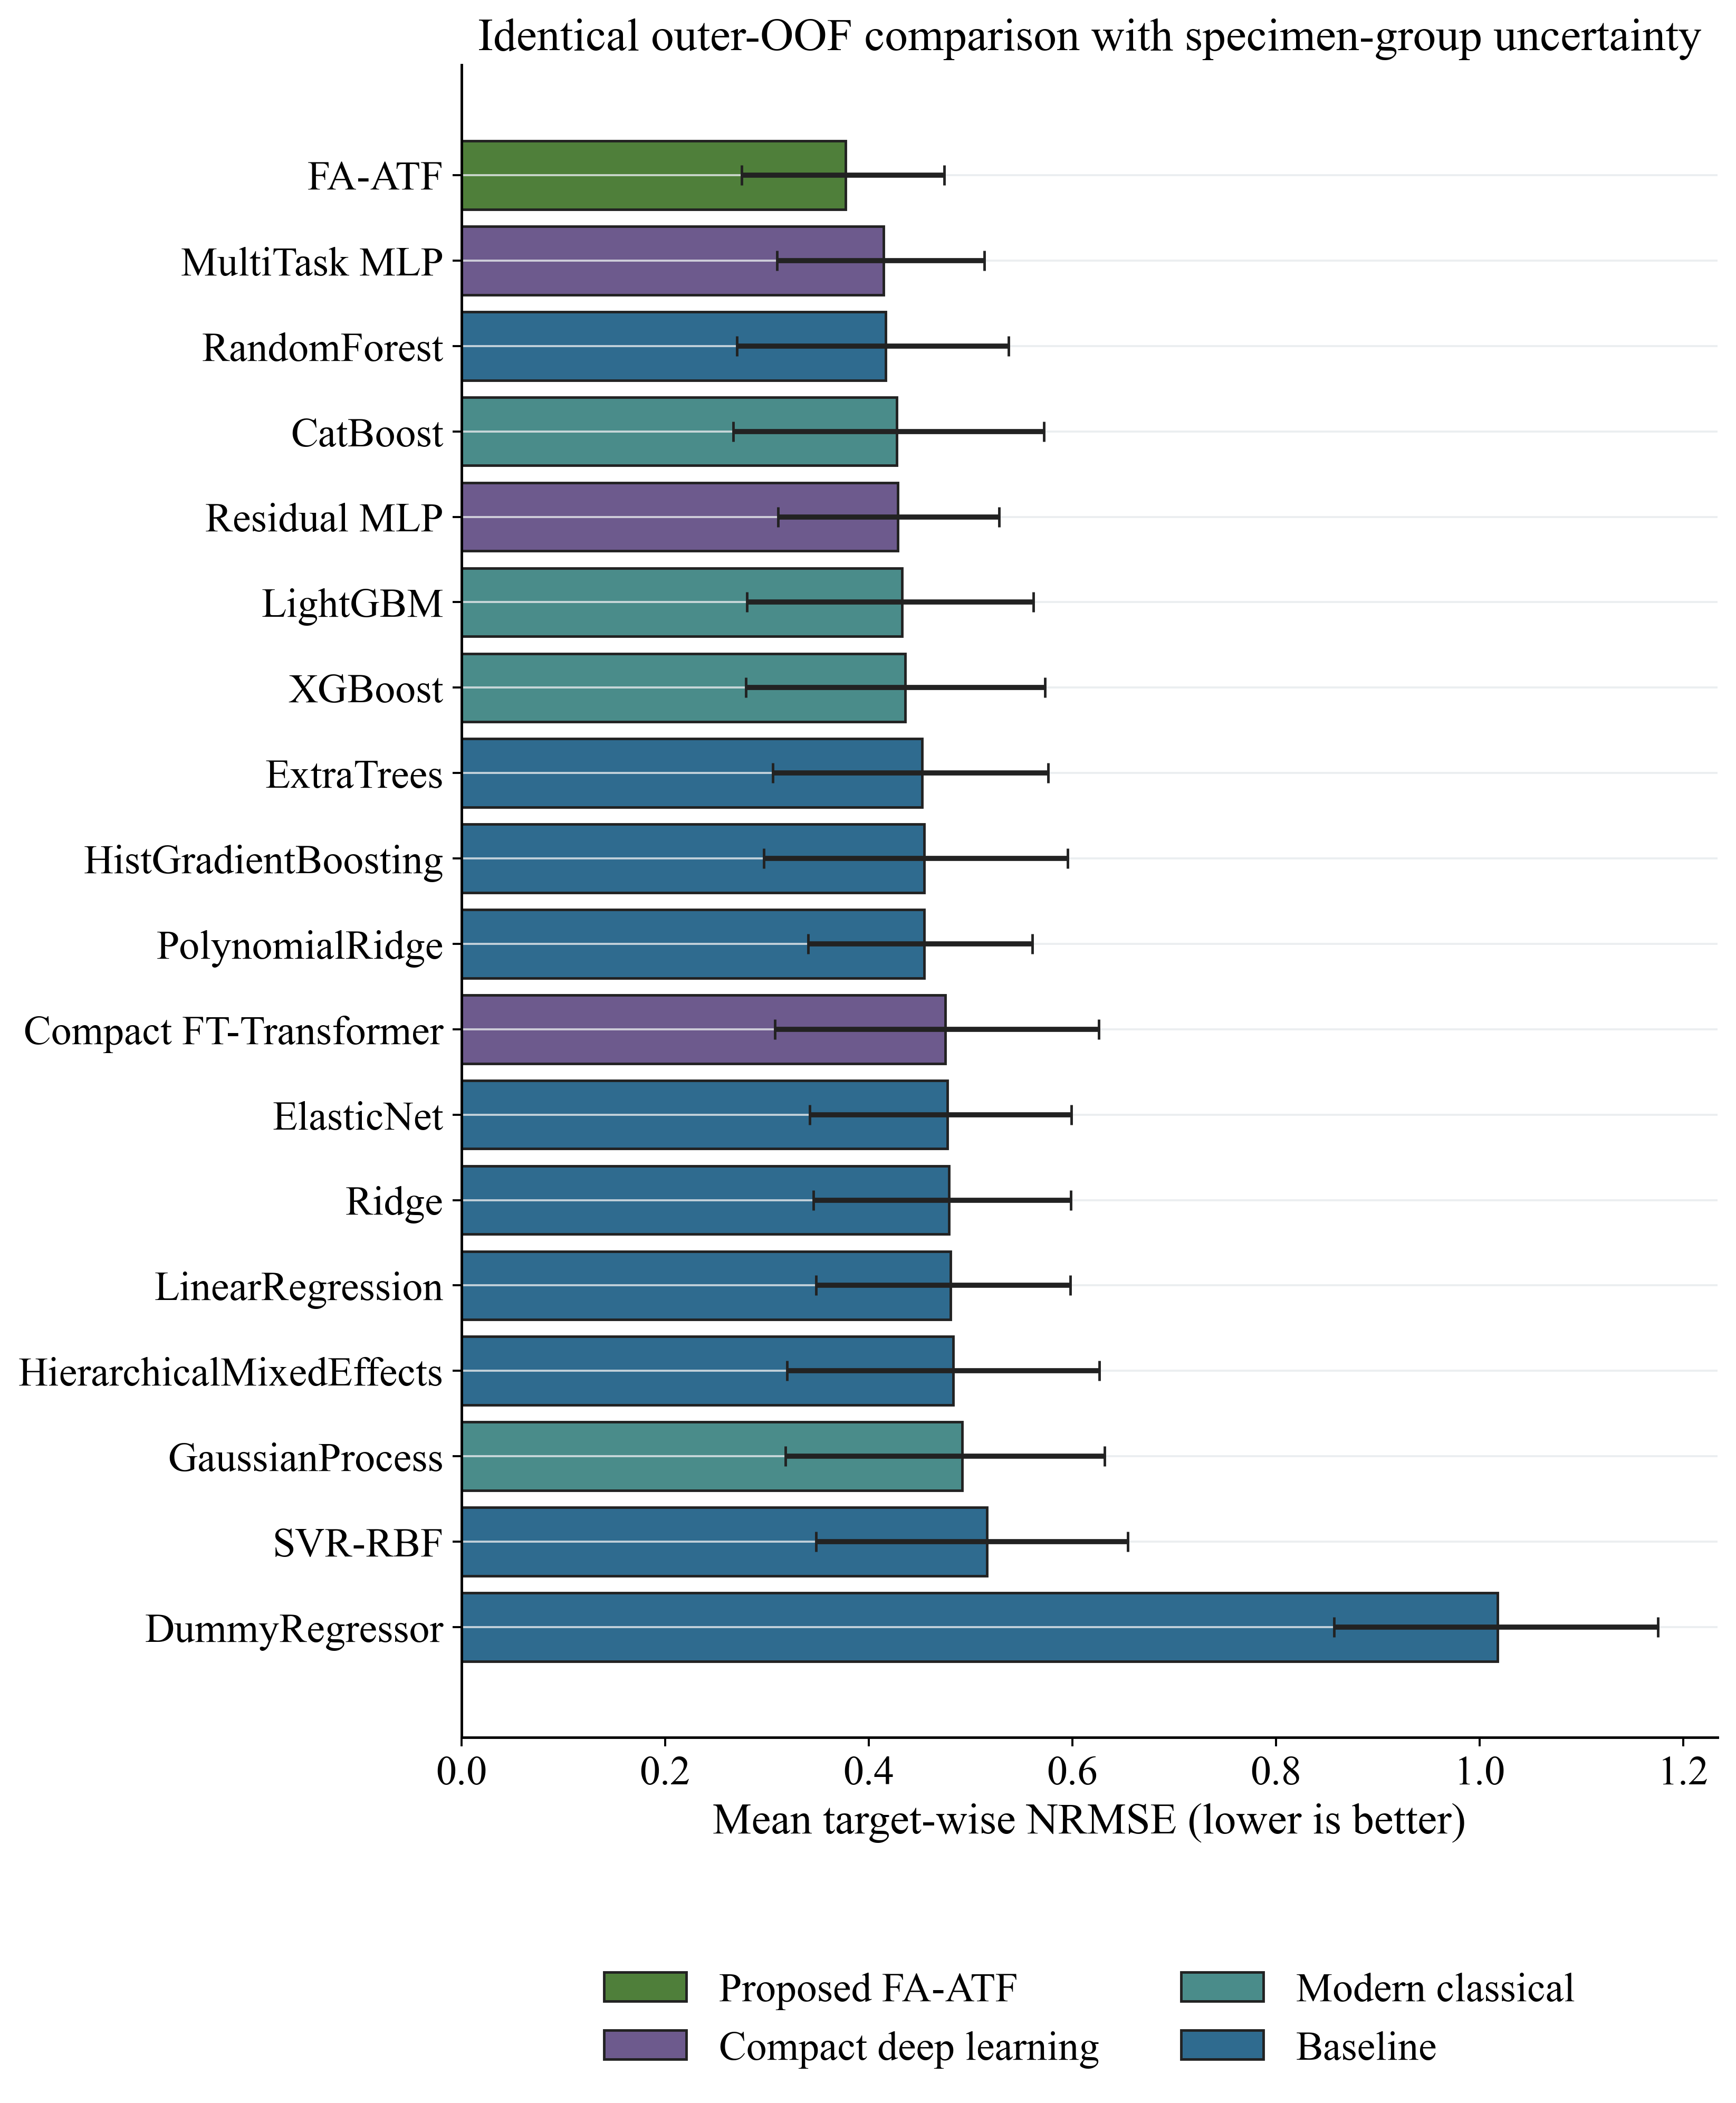

In [6]:
from matplotlib.patches import Patch

plot_data = ranking.sort_values("mean_NRMSE", ascending=True).reset_index(drop=True)
colors = [
    PALETTE["green"] if model == "FA-ATF" else
    PALETTE["purple"] if family == "Compact deep learning" else
    PALETTE["teal"] if family == "Modern classical" else PALETTE["blue"]
    for model, family in zip(plot_data.model, plot_data.model_family)
]
fig_height = max(9.0, 0.52 * len(plot_data) + 2.4)
fig, axis = plt.subplots(figsize=(10.8, fig_height))
axis.barh(plot_data.model, plot_data.mean_NRMSE, color=colors, edgecolor=PALETTE["black"])
errors = np.vstack([
    plot_data.mean_NRMSE - plot_data.mean_NRMSE_CI_low,
    plot_data.mean_NRMSE_CI_high - plot_data.mean_NRMSE,
])
axis.errorbar(plot_data.mean_NRMSE, np.arange(len(plot_data)), xerr=errors,
              fmt="none", color=PALETTE["black"], capsize=4)
axis.set_title("Identical outer-OOF comparison with specimen-group uncertainty")
axis.set_xlabel("Mean target-wise NRMSE (lower is better)")
axis.set_ylabel("")
axis.invert_yaxis()
axis.grid(axis="x")
legend_handles = [
    Patch(facecolor=PALETTE["green"], edgecolor=PALETTE["black"], label="Proposed FA-ATF"),
    Patch(facecolor=PALETTE["purple"], edgecolor=PALETTE["black"], label="Compact deep learning"),
    Patch(facecolor=PALETTE["teal"], edgecolor=PALETTE["black"], label="Modern classical"),
    Patch(facecolor=PALETTE["blue"], edgecolor=PALETTE["black"], label="Baseline"),
]
axis.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.22),
            ncol=2, frameon=False)
fig.subplots_adjust(left=0.35, right=0.98, top=0.93, bottom=0.16)
save_scientific_figure(fig, "final_all_models_ranking", plot_data)
display(fig)
plt.close(fig)

## 5. Perform paired comparisons of FA-ATF

In [7]:
best_baseline = ranking[ranking.model_family.eq("Baseline")].iloc[0].model
best_modern = ranking[ranking.model_family.eq("Modern classical")].iloc[0].model
best_dl = ranking[ranking.model_family.eq("Compact deep learning")].iloc[0].model
comparators = list(dict.fromkeys([best_baseline, best_modern, best_dl]))
family_comparators = [model for model in ranking.model if model != "FA-ATF"]

normalized = all_predictions.copy()
normalized["normalized_absolute_error"] = normalized.apply(
    lambda row: abs(row.y_true - row.y_pred) / TARGET_SCALES[row.target], axis=1
)
specimen_error = normalized.groupby(["specimen_id", "model"], as_index=False).normalized_absolute_error.mean()
error_wide = specimen_error.pivot(index="specimen_id", columns="model", values="normalized_absolute_error")

paired_rows = []
for comparator in family_comparators:
    differences = error_wide["FA-ATF"] - error_wide[comparator]
    if np.allclose(differences, 0.0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(differences, alternative="two-sided", zero_method="wilcox")
    nonzero = differences[differences.ne(0)].to_numpy()
    signed_ranks = rankdata(np.abs(nonzero))
    positive_rank_sum = signed_ranks[nonzero > 0].sum()
    negative_rank_sum = signed_ranks[nonzero < 0].sum()
    rank_biserial = (positive_rank_sum - negative_rank_sum) / max(signed_ranks.sum(), 1.0)
    delta_bootstrap = overall_bootstrap[:, model_index["FA-ATF"]] - overall_bootstrap[:, model_index[comparator]]
    paired_rows.append({
        "comparison": f"FA-ATF minus {comparator}", "comparator": comparator,
        "delta_mean_NRMSE": ranking.set_index("model").loc["FA-ATF", "mean_NRMSE"] - ranking.set_index("model").loc[comparator, "mean_NRMSE"],
        "bootstrap_CI_low": np.quantile(delta_bootstrap, 0.025),
        "bootstrap_CI_high": np.quantile(delta_bootstrap, 0.975),
        "bootstrap_probability_FA_ATF_lower_error": np.mean(delta_bootstrap < 0),
        "wilcoxon_statistic": statistic, "wilcoxon_p_raw": p_value,
        "matched_rank_biserial": rank_biserial, "paired_specimens": len(differences),
        "focal_family_leader": comparator in comparators,
    })
paired = pd.DataFrame(paired_rows).sort_values("wilcoxon_p_raw").reset_index(drop=True)
holm_raw = paired.wilcoxon_p_raw.to_numpy() * np.arange(len(paired), 0, -1)
paired["wilcoxon_p_Holm"] = np.minimum(1.0, np.maximum.accumulate(holm_raw))
paired.to_csv(STATISTICS_DIR / "paired_fa_atf_comparisons.csv", index=False)
display_grouped_table(paired.round(4), "FA-ATF paired comparisons against the full model family")

**FA-ATF paired comparisons against the full model family — records 1-12 in displayed order — Predictive performance**

comparison,comparator,delta_mean_NRMSE,bootstrap_probability_FA_ATF_lower_error,matched_rank_biserial
FA-ATF minus DummyRegressor,DummyRegressor,-0.640300,1.000000,-0.963000
FA-ATF minus SVR-RBF,SVR-RBF,-0.138900,1.000000,-0.751300
FA-ATF minus HierarchicalMixedEffects,HierarchicalMixedEffects,-0.105600,0.994000,-0.693100
FA-ATF minus LinearRegression,LinearRegression,-0.102900,1.000000,-0.656100
FA-ATF minus Ridge,Ridge,-0.101700,1.000000,-0.645500
FA-ATF minus PolynomialRidge,PolynomialRidge,-0.077400,1.000000,-0.645500
FA-ATF minus ElasticNet,ElasticNet,-0.100000,1.000000,-0.629600
FA-ATF minus HistGradientBoosting,HistGradientBoosting,-0.077100,0.959500,-0.492100
FA-ATF minus Residual MLP,Residual MLP,-0.051400,0.990000,-0.444400
FA-ATF minus Compact FT-Transformer,Compact FT-Transformer,-0.097900,0.990500,-0.412700


**FA-ATF paired comparisons against the full model family — records 1-12 in displayed order — Uncertainty and statistical evidence**

comparison,comparator,bootstrap_CI_low,bootstrap_CI_high,wilcoxon_statistic,wilcoxon_p_raw,wilcoxon_p_Holm
FA-ATF minus DummyRegressor,DummyRegressor,-0.751800,-0.518600,7.000000,0.000000,0.000000
FA-ATF minus SVR-RBF,SVR-RBF,-0.259500,-0.050900,47.000000,0.000300,0.004800
FA-ATF minus HierarchicalMixedEffects,HierarchicalMixedEffects,-0.169100,-0.018500,58.000000,0.001000,0.015300
FA-ATF minus LinearRegression,LinearRegression,-0.157500,-0.042800,65.000000,0.002000,0.028600
FA-ATF minus Ridge,Ridge,-0.155900,-0.038800,67.000000,0.002500,0.032100
FA-ATF minus PolynomialRidge,PolynomialRidge,-0.113800,-0.040900,67.000000,0.002500,0.032100
FA-ATF minus ElasticNet,ElasticNet,-0.153600,-0.039000,70.000000,0.003200,0.035700
FA-ATF minus HistGradientBoosting,HistGradientBoosting,-0.135500,0.006200,96.000000,0.024500,0.245400
FA-ATF minus Residual MLP,Residual MLP,-0.093300,-0.007900,105.000000,0.043600,0.392000
FA-ATF minus Compact FT-Transformer,Compact FT-Transformer,-0.159900,-0.012800,111.000000,0.061900,0.495200


**FA-ATF paired comparisons against the full model family — records 1-12 in displayed order — Sample, fold, and provenance**

comparison,comparator,paired_specimens
FA-ATF minus DummyRegressor,DummyRegressor,27
FA-ATF minus SVR-RBF,SVR-RBF,27
FA-ATF minus HierarchicalMixedEffects,HierarchicalMixedEffects,27
FA-ATF minus LinearRegression,LinearRegression,27
FA-ATF minus Ridge,Ridge,27
FA-ATF minus PolynomialRidge,PolynomialRidge,27
FA-ATF minus ElasticNet,ElasticNet,27
FA-ATF minus HistGradientBoosting,HistGradientBoosting,27
FA-ATF minus Residual MLP,Residual MLP,27
FA-ATF minus Compact FT-Transformer,Compact FT-Transformer,27


... (6 outputs left out)

**FA-ATF paired comparisons against the full model family — records 13-17 in displayed order — Sample, fold, and provenance**

comparison,comparator,paired_specimens
FA-ATF minus ExtraTrees,ExtraTrees,27
FA-ATF minus RandomForest,RandomForest,27
FA-ATF minus LightGBM,LightGBM,27
FA-ATF minus XGBoost,XGBoost,27
FA-ATF minus CatBoost,CatBoost,27


**FA-ATF paired comparisons against the full model family — records 13-17 in displayed order — Additional reported attributes**

comparison,comparator,focal_family_leader
FA-ATF minus ExtraTrees,ExtraTrees,False
FA-ATF minus RandomForest,RandomForest,True
FA-ATF minus LightGBM,LightGBM,False
FA-ATF minus XGBoost,XGBoost,False
FA-ATF minus CatBoost,CatBoost,True


Paired comparisons operate on matched specimen-level normalized errors and cover every non-FA-ATF model, with Holm correction across the full relevant family. The sign convention is FA-ATF minus comparator, so negative values favor FA-ATF. Baseline, modern-classical, and DL family leaders are retained only as descriptive focal comparators in figures; because their labels are selected from the same OOF ranking, focal tests are not presented as independent confirmatory evidence. Overlapping outer-training sets further require conservative interpretation.


## 6. Plot paired bootstrap differences

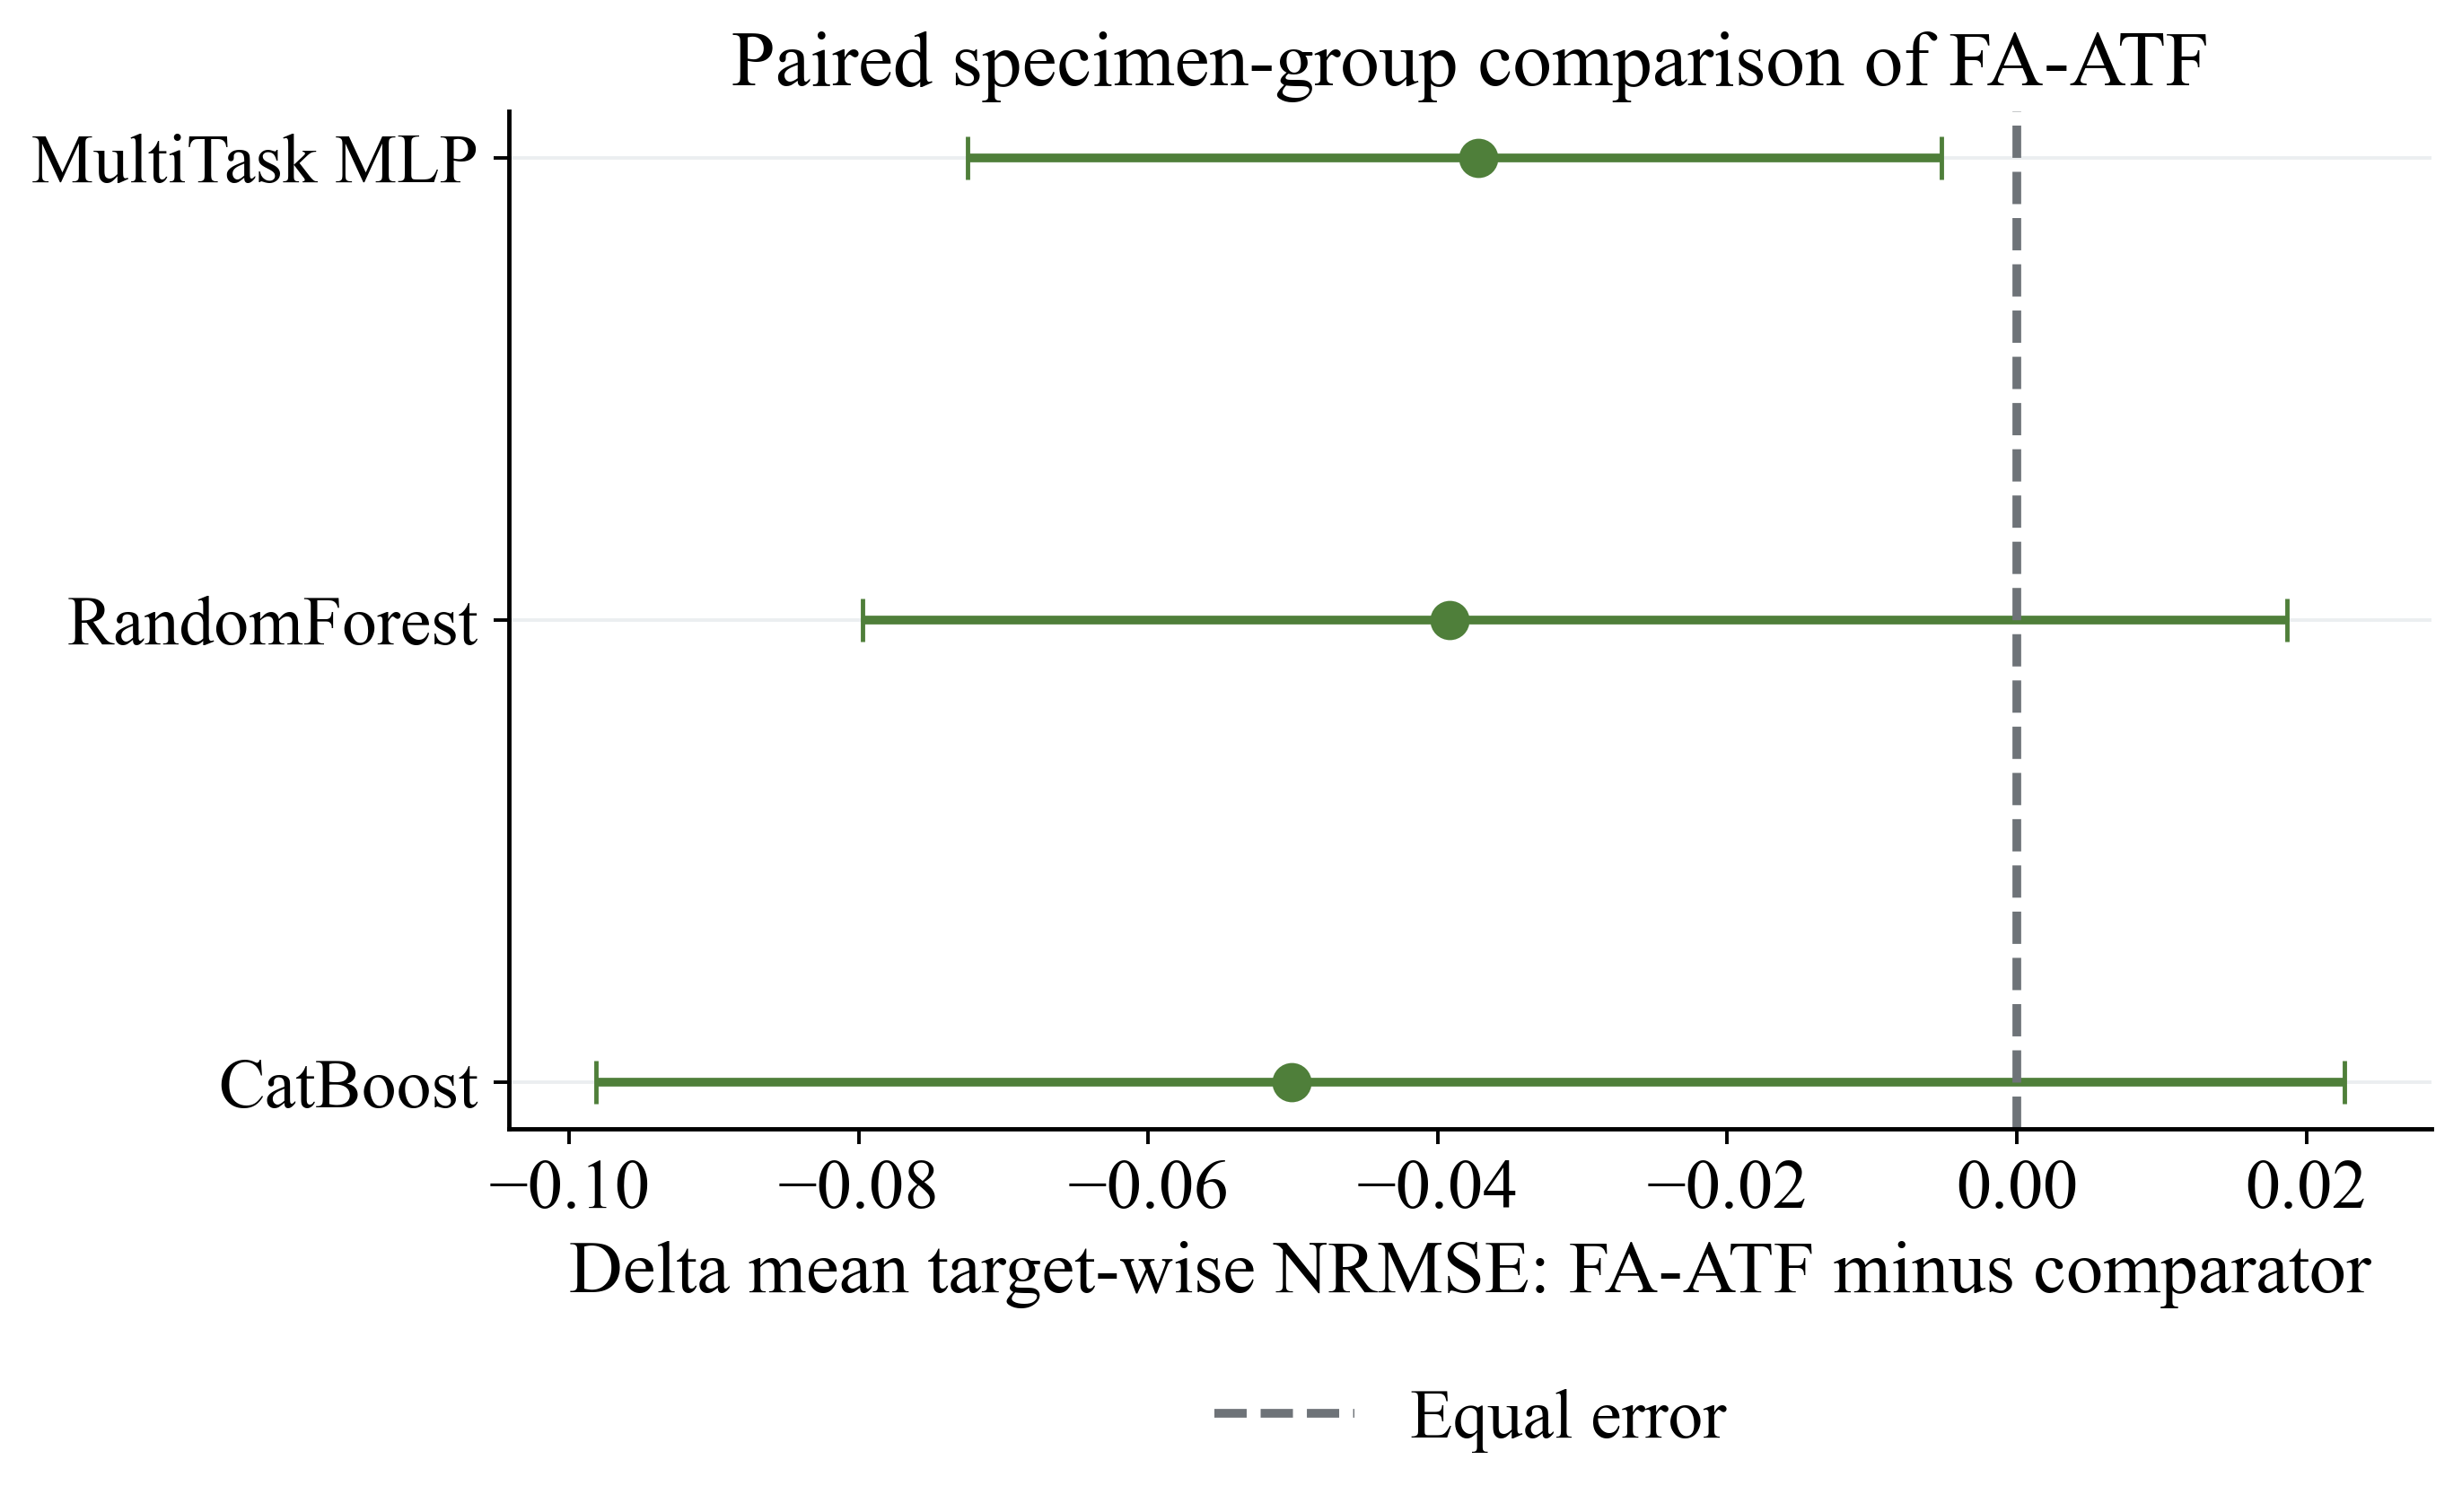

In [8]:
paired_plot = paired[paired.focal_family_leader].sort_values("delta_mean_NRMSE").reset_index(drop=True)
fig, axis = plt.subplots(figsize=(9.0, 5.4))
for index, row in paired_plot.iterrows():
    lower = row.delta_mean_NRMSE - row.bootstrap_CI_low
    upper = row.bootstrap_CI_high - row.delta_mean_NRMSE
    axis.errorbar(row.delta_mean_NRMSE, index, xerr=[[lower], [upper]], fmt="o",
                  color=PALETTE["green"], capsize=5, markersize=8)
axis.axvline(0.0, color=PALETTE["gray"], linestyle="--", label="Equal error")
axis.set_yticks(range(len(paired_plot)), labels=paired_plot.comparator)
axis.set_title("Paired specimen-group comparison of FA-ATF")
axis.set_xlabel("Delta mean target-wise NRMSE: FA-ATF minus comparator")
axis.set_ylabel("")
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), frameon=False)
axis.grid(axis="x")
fig.subplots_adjust(bottom=0.28, left=0.30, right=0.98, top=0.88)
save_scientific_figure(fig, "paired_fa_atf_differences", paired_plot)
display(fig)
plt.close(fig)

## 7. Quantify cluster-bootstrap rank stability

Point ranks can be unstable in a 27-specimen study. The same specimen-cluster bootstrap replicates
used for metric intervals are therefore converted into complete model ranks. The resulting
probability of rank one and rank interval describe ordering stability without treating bootstrap
draws as new experiments.


In [9]:
bootstrap_ranks = np.argsort(np.argsort(overall_bootstrap, axis=1), axis=1) + 1
rank_rows = []
for model in model_names:
    values = bootstrap_ranks[:, model_index[model]]
    probability_rank_one = np.mean(values == 1)
    rank_rows.append({
        "model": model,
        "model_family": model_family[model],
        "point_rank": int(ranking.set_index("model").loc[model, "rank"]),
        "probability_rank_1": probability_rank_one,
        "Monte_Carlo_SE_probability": np.sqrt(
            probability_rank_one * (1.0 - probability_rank_one) / N_BOOTSTRAP
        ),
        "median_bootstrap_rank": float(np.median(values)),
        "rank_95pct_low": float(np.quantile(values, 0.025)),
        "rank_95pct_high": float(np.quantile(values, 0.975)),
        "cluster_bootstrap_resamples": N_BOOTSTRAP,
    })
rank_stability = pd.DataFrame(rank_rows).sort_values(
    ["probability_rank_1", "median_bootstrap_rank"], ascending=[False, True]
)
rank_stability.to_csv(STATISTICS_DIR / "cluster_bootstrap_rank_stability.csv", index=False)
display_grouped_table(rank_stability.round(4), "Specimen-cluster bootstrap rank stability")


**Specimen-cluster bootstrap rank stability — model_family=Proposed — Predictive performance**

model,model_family,point_rank,probability_rank_1,median_bootstrap_rank,rank_95pct_low,rank_95pct_high
FA-ATF,Proposed,1,0.830500,1.000000,1.000000,5.000000


**Specimen-cluster bootstrap rank stability — model_family=Proposed — Uncertainty and statistical evidence**

model,model_family,Monte_Carlo_SE_probability,cluster_bootstrap_resamples
FA-ATF,Proposed,0.008400,2000


**Specimen-cluster bootstrap rank stability — model_family=Modern classical — Predictive performance**

model,model_family,point_rank,probability_rank_1,median_bootstrap_rank,rank_95pct_low,rank_95pct_high
CatBoost,Modern classical,4,0.070000,5.000000,1.000000,11.000000
XGBoost,Modern classical,7,0.011000,7.000000,2.000000,13.000000
LightGBM,Modern classical,6,0.001500,6.000000,3.000000,10.000000
GaussianProcess,Modern classical,16,0.000000,15.000000,3.000000,16.000000


... (6 outputs left out)

**Specimen-cluster bootstrap rank stability — model_family=Compact deep learning — Predictive performance**

model,model_family,point_rank,probability_rank_1,median_bootstrap_rank,rank_95pct_low,rank_95pct_high
MultiTask MLP,Compact deep learning,2,0.005000,3.000000,2.000000,11.000000
Residual MLP,Compact deep learning,5,0.004500,6.000000,2.000000,13.000000
Compact FT-Transformer,Compact deep learning,11,0.001500,12.000000,4.000000,17.000000


**Specimen-cluster bootstrap rank stability — model_family=Compact deep learning — Uncertainty and statistical evidence**

model,model_family,Monte_Carlo_SE_probability,cluster_bootstrap_resamples
MultiTask MLP,Compact deep learning,0.001600,2000
Residual MLP,Compact deep learning,0.001500,2000
Compact FT-Transformer,Compact deep learning,0.000900,2000


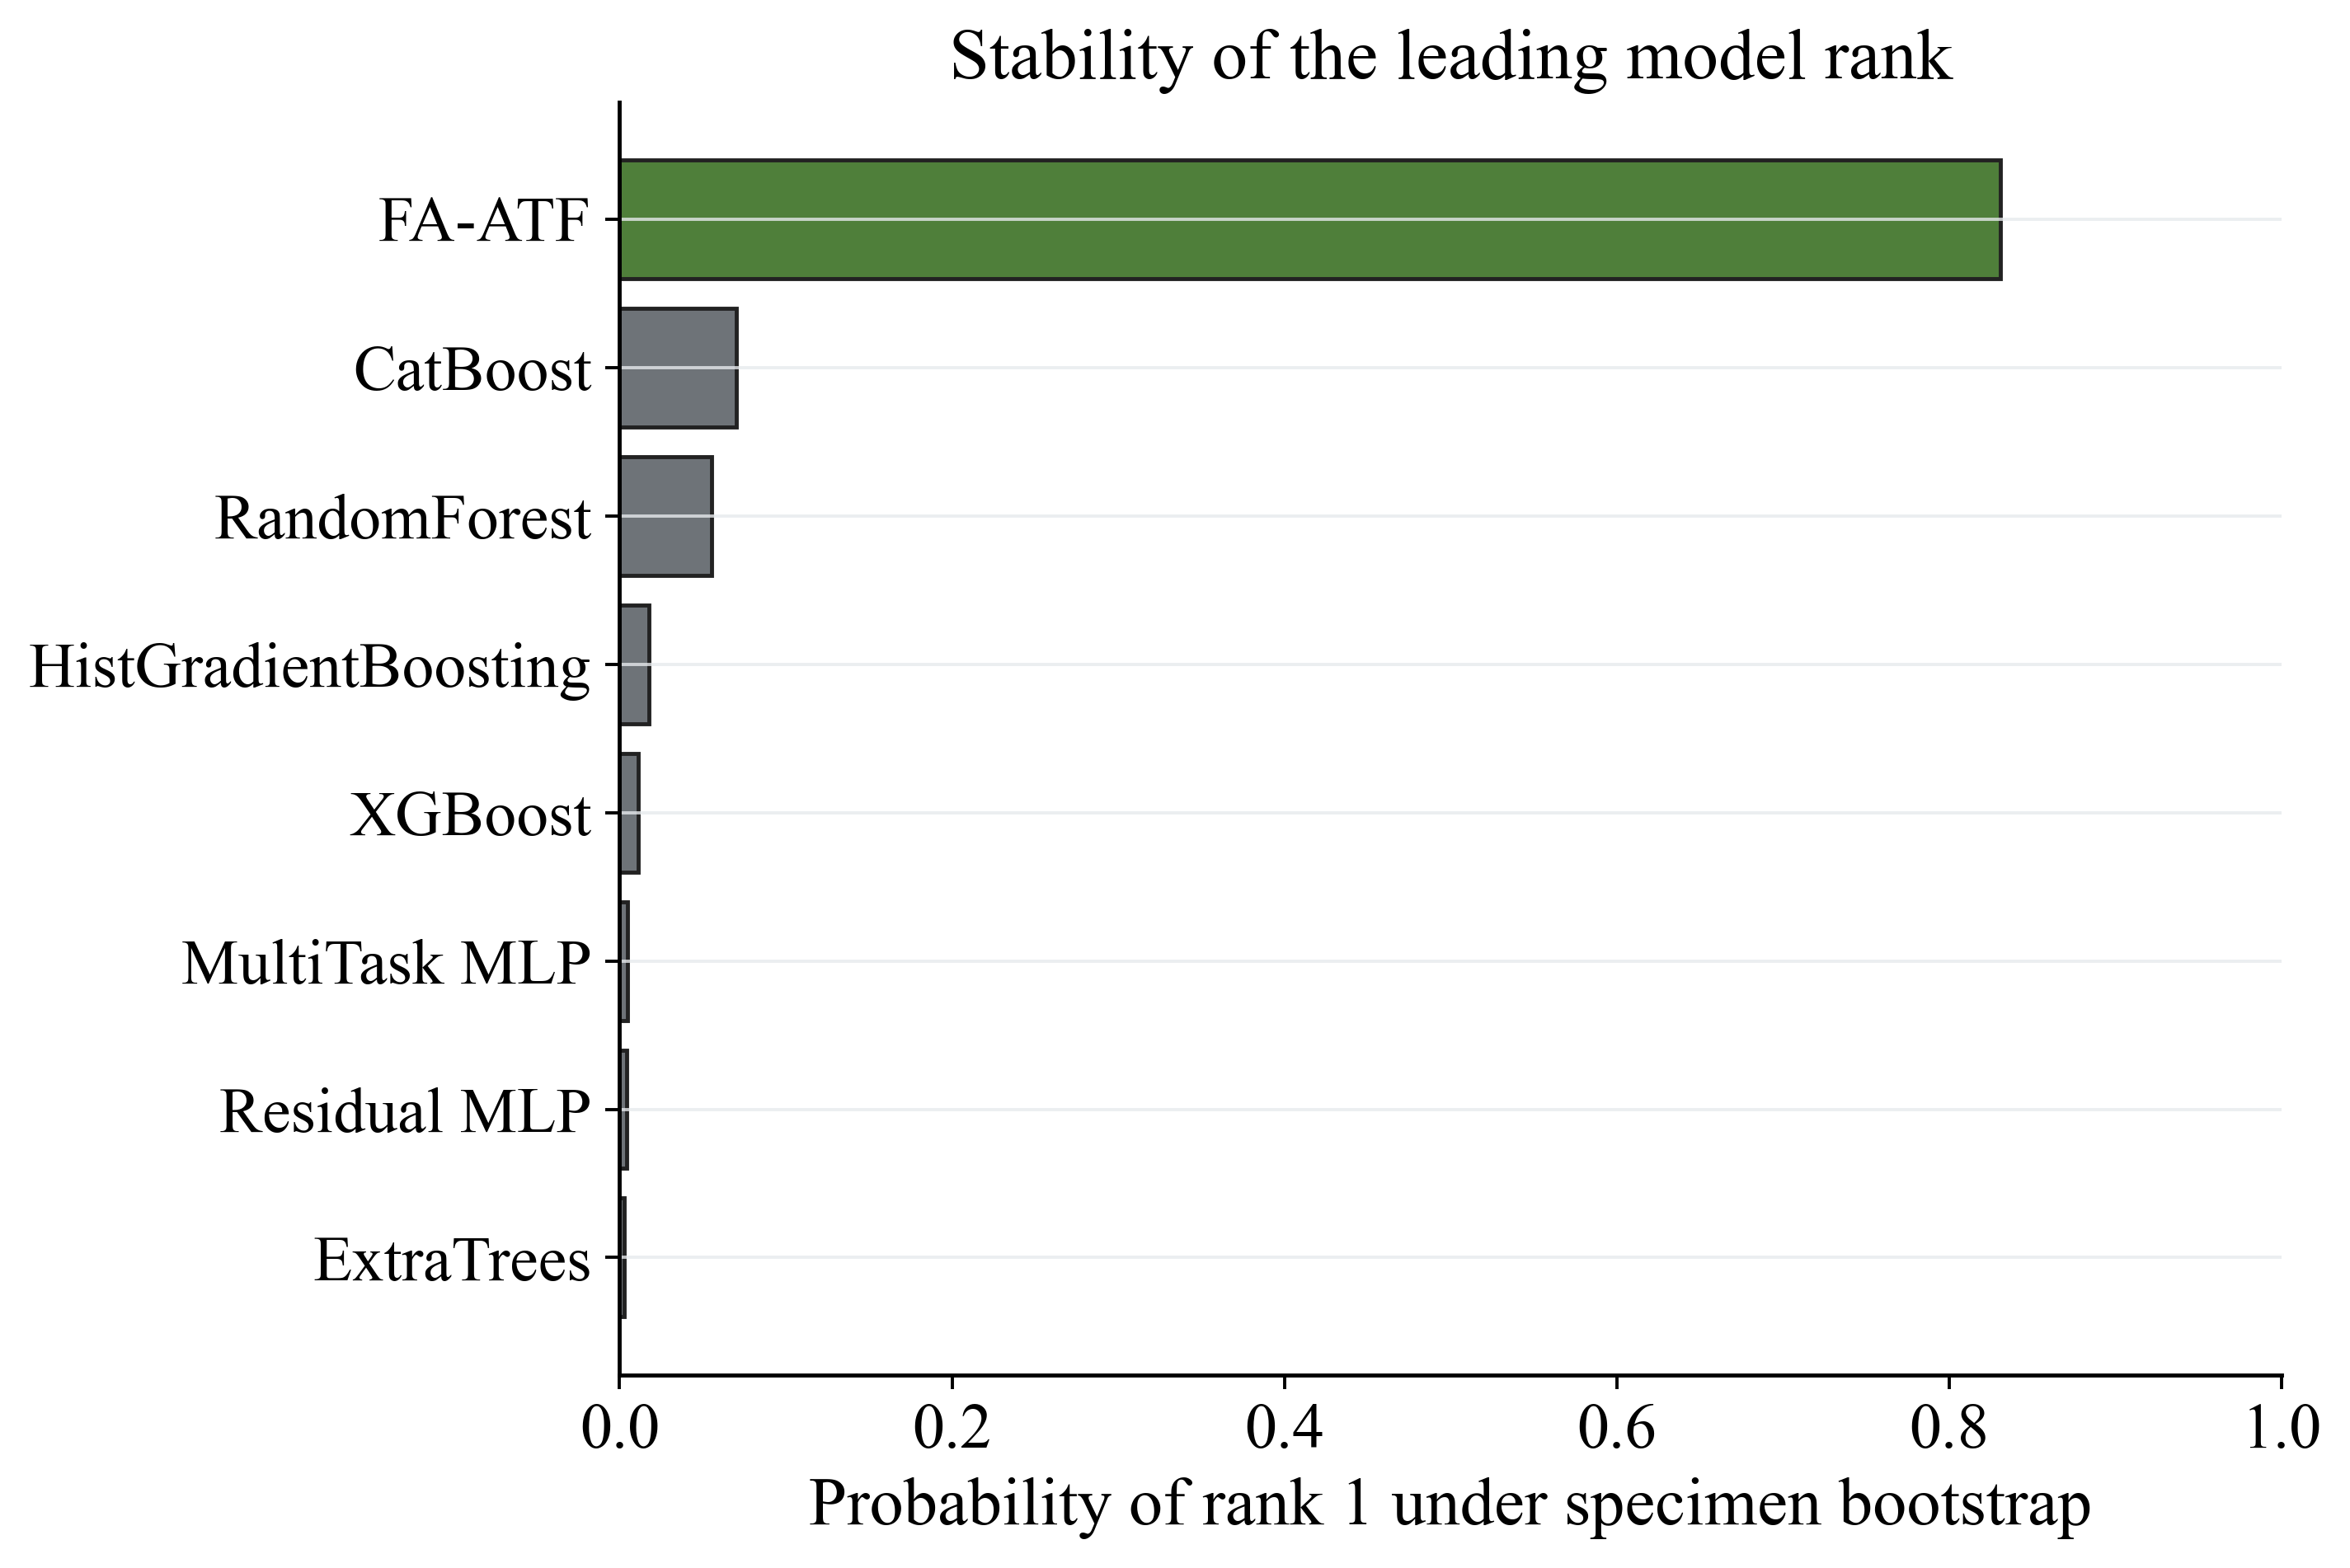

In [10]:
rank_plot = rank_stability.head(8).sort_values("probability_rank_1")
fig, axis = plt.subplots(figsize=(9.0, 6.3))
colors = [PALETTE["green"] if model == "FA-ATF" else PALETTE["gray"] for model in rank_plot.model]
axis.barh(rank_plot.model, rank_plot.probability_rank_1, color=colors, edgecolor=PALETTE["black"])
axis.set_xlim(0, 1.0)
axis.set_xlabel("Probability of rank 1 under specimen bootstrap")
axis.set_ylabel("")
axis.set_title("Stability of the leading model rank")
axis.grid(axis="x")
fig.subplots_adjust(left=0.34, right=0.98, bottom=0.18, top=0.88)
save_scientific_figure(fig, "cluster_bootstrap_rank_stability", rank_plot)
display(fig)
plt.close(fig)


## 8. Add a specimen-level randomization test and influence analysis

A one-sided paired sign-flip test evaluates normalized squared loss at the independent specimen
level, followed by Holm correction across the three pre-specified comparator families. A
leave-one-specimen-out influence analysis then recomputes the exact primary endpoint after removing
each specimen in turn. Neither analysis changes model predictions.


In [11]:
RANDOMIZATION_DRAWS = 99999
randomization_rng = np.random.default_rng(SEED + 701)
squared_source = all_predictions[all_predictions.model.isin(["FA-ATF", *comparators])].copy()
squared_source["normalized_squared_error"] = squared_source.apply(
    lambda row: ((row.y_true - row.y_pred) / TARGET_SCALES[row.target]) ** 2,
    axis=1,
)
specimen_squared = squared_source.groupby(
    ["specimen_id", "model"], as_index=False
).normalized_squared_error.mean()
squared_wide = specimen_squared.pivot(
    index="specimen_id", columns="model", values="normalized_squared_error"
)

sign_flip_rows = []
for comparator in comparators:
    differences = (squared_wide["FA-ATF"] - squared_wide[comparator]).to_numpy()
    observed = float(differences.mean())
    signs = randomization_rng.choice(
        np.array([-1.0, 1.0]), size=(RANDOMIZATION_DRAWS, len(differences))
    )
    null_means = np.mean(signs * differences, axis=1)
    sign_flip_rows.append({
        "comparator": comparator,
        "mean_delta_normalized_squared_error": observed,
        "standardized_paired_effect_dz": observed / differences.std(ddof=1),
        "specimens_favoring_FA_ATF": int(np.sum(differences < 0)),
        "paired_specimens": len(differences),
        "one_sided_sign_flip_p_raw": (
            1.0 + np.sum(null_means <= observed)
        ) / (RANDOMIZATION_DRAWS + 1.0),
        "randomization_draws": RANDOMIZATION_DRAWS,
    })

sign_flip = pd.DataFrame(sign_flip_rows).sort_values(
    "one_sided_sign_flip_p_raw"
).reset_index(drop=True)
holm_values = sign_flip.one_sided_sign_flip_p_raw.to_numpy() * np.arange(len(sign_flip), 0, -1)
sign_flip["one_sided_sign_flip_p_Holm"] = np.minimum(
    1.0, np.maximum.accumulate(holm_values)
)
sign_flip.to_csv(STATISTICS_DIR / "paired_sign_flip_randomization.csv", index=False)
display_grouped_table(sign_flip.round(5), "Paired specimen-level sign-flip tests")


**Paired specimen-level sign-flip tests — Predictive performance**

comparator,mean_delta_normalized_squared_error
MultiTask MLP,-0.031950
RandomForest,-0.034720
CatBoost,-0.046760


**Paired specimen-level sign-flip tests — Uncertainty and statistical evidence**

comparator,standardized_paired_effect_dz,one_sided_sign_flip_p_raw,one_sided_sign_flip_p_Holm
MultiTask MLP,-0.416310,0.019250,0.057750
RandomForest,-0.253560,0.108440,0.216880
CatBoost,-0.219950,0.193510,0.216880


**Paired specimen-level sign-flip tests — Sample, fold, and provenance**

comparator,specimens_favoring_FA_ATF,paired_specimens,randomization_draws
MultiTask MLP,18,27,99999
RandomForest,11,27,99999
CatBoost,11,27,99999


In [12]:
focal_prediction_source = all_predictions[
    all_predictions.model.isin(["FA-ATF", *comparators])
].copy()
specimen_ids = np.sort(focal_prediction_source.specimen_id.unique())
loo_rows = []
for omitted_specimen in specimen_ids:
    retained = focal_prediction_source[
        focal_prediction_source.specimen_id.ne(omitted_specimen)
    ]
    model_scores = {}
    for model, model_part in retained.groupby("model"):
        target_scores = []
        for target, target_part in model_part.groupby("target"):
            target_scores.append(
                np.sqrt(mean_squared_error(target_part.y_true, target_part.y_pred))
                / TARGET_SCALES[target]
            )
        model_scores[model] = float(np.mean(target_scores))
    for comparator in comparators:
        loo_rows.append({
            "omitted_specimen": omitted_specimen,
            "comparator": comparator,
            "FA_ATF_mean_NRMSE": model_scores["FA-ATF"],
            "comparator_mean_NRMSE": model_scores[comparator],
            "delta_mean_NRMSE": model_scores["FA-ATF"] - model_scores[comparator],
        })

leave_one_specimen = pd.DataFrame(loo_rows)
loo_summary = leave_one_specimen.groupby("comparator", as_index=False).agg(
    omitted_specimens=("omitted_specimen", "nunique"),
    minimum_delta=("delta_mean_NRMSE", "min"),
    median_delta=("delta_mean_NRMSE", "median"),
    maximum_delta=("delta_mean_NRMSE", "max"),
    omissions_favoring_FA_ATF=("delta_mean_NRMSE", lambda values: int(np.sum(values < 0))),
)
leave_one_specimen.to_csv(STATISTICS_DIR / "fa_atf_leave_one_specimen_influence.csv", index=False)
loo_summary.to_csv(STATISTICS_DIR / "fa_atf_leave_one_specimen_summary.csv", index=False)
display_grouped_table(loo_summary.round(5), "Leave-one-specimen influence summary")


**Leave-one-specimen influence summary — Complete table**

comparator,omitted_specimens,minimum_delta,median_delta,maximum_delta,omissions_favoring_FA_ATF
CatBoost,27,-0.057610,-0.051380,-0.014770,27
MultiTask MLP,27,-0.044690,-0.037500,-0.030160,27
RandomForest,27,-0.046830,-0.040470,-0.024230,27


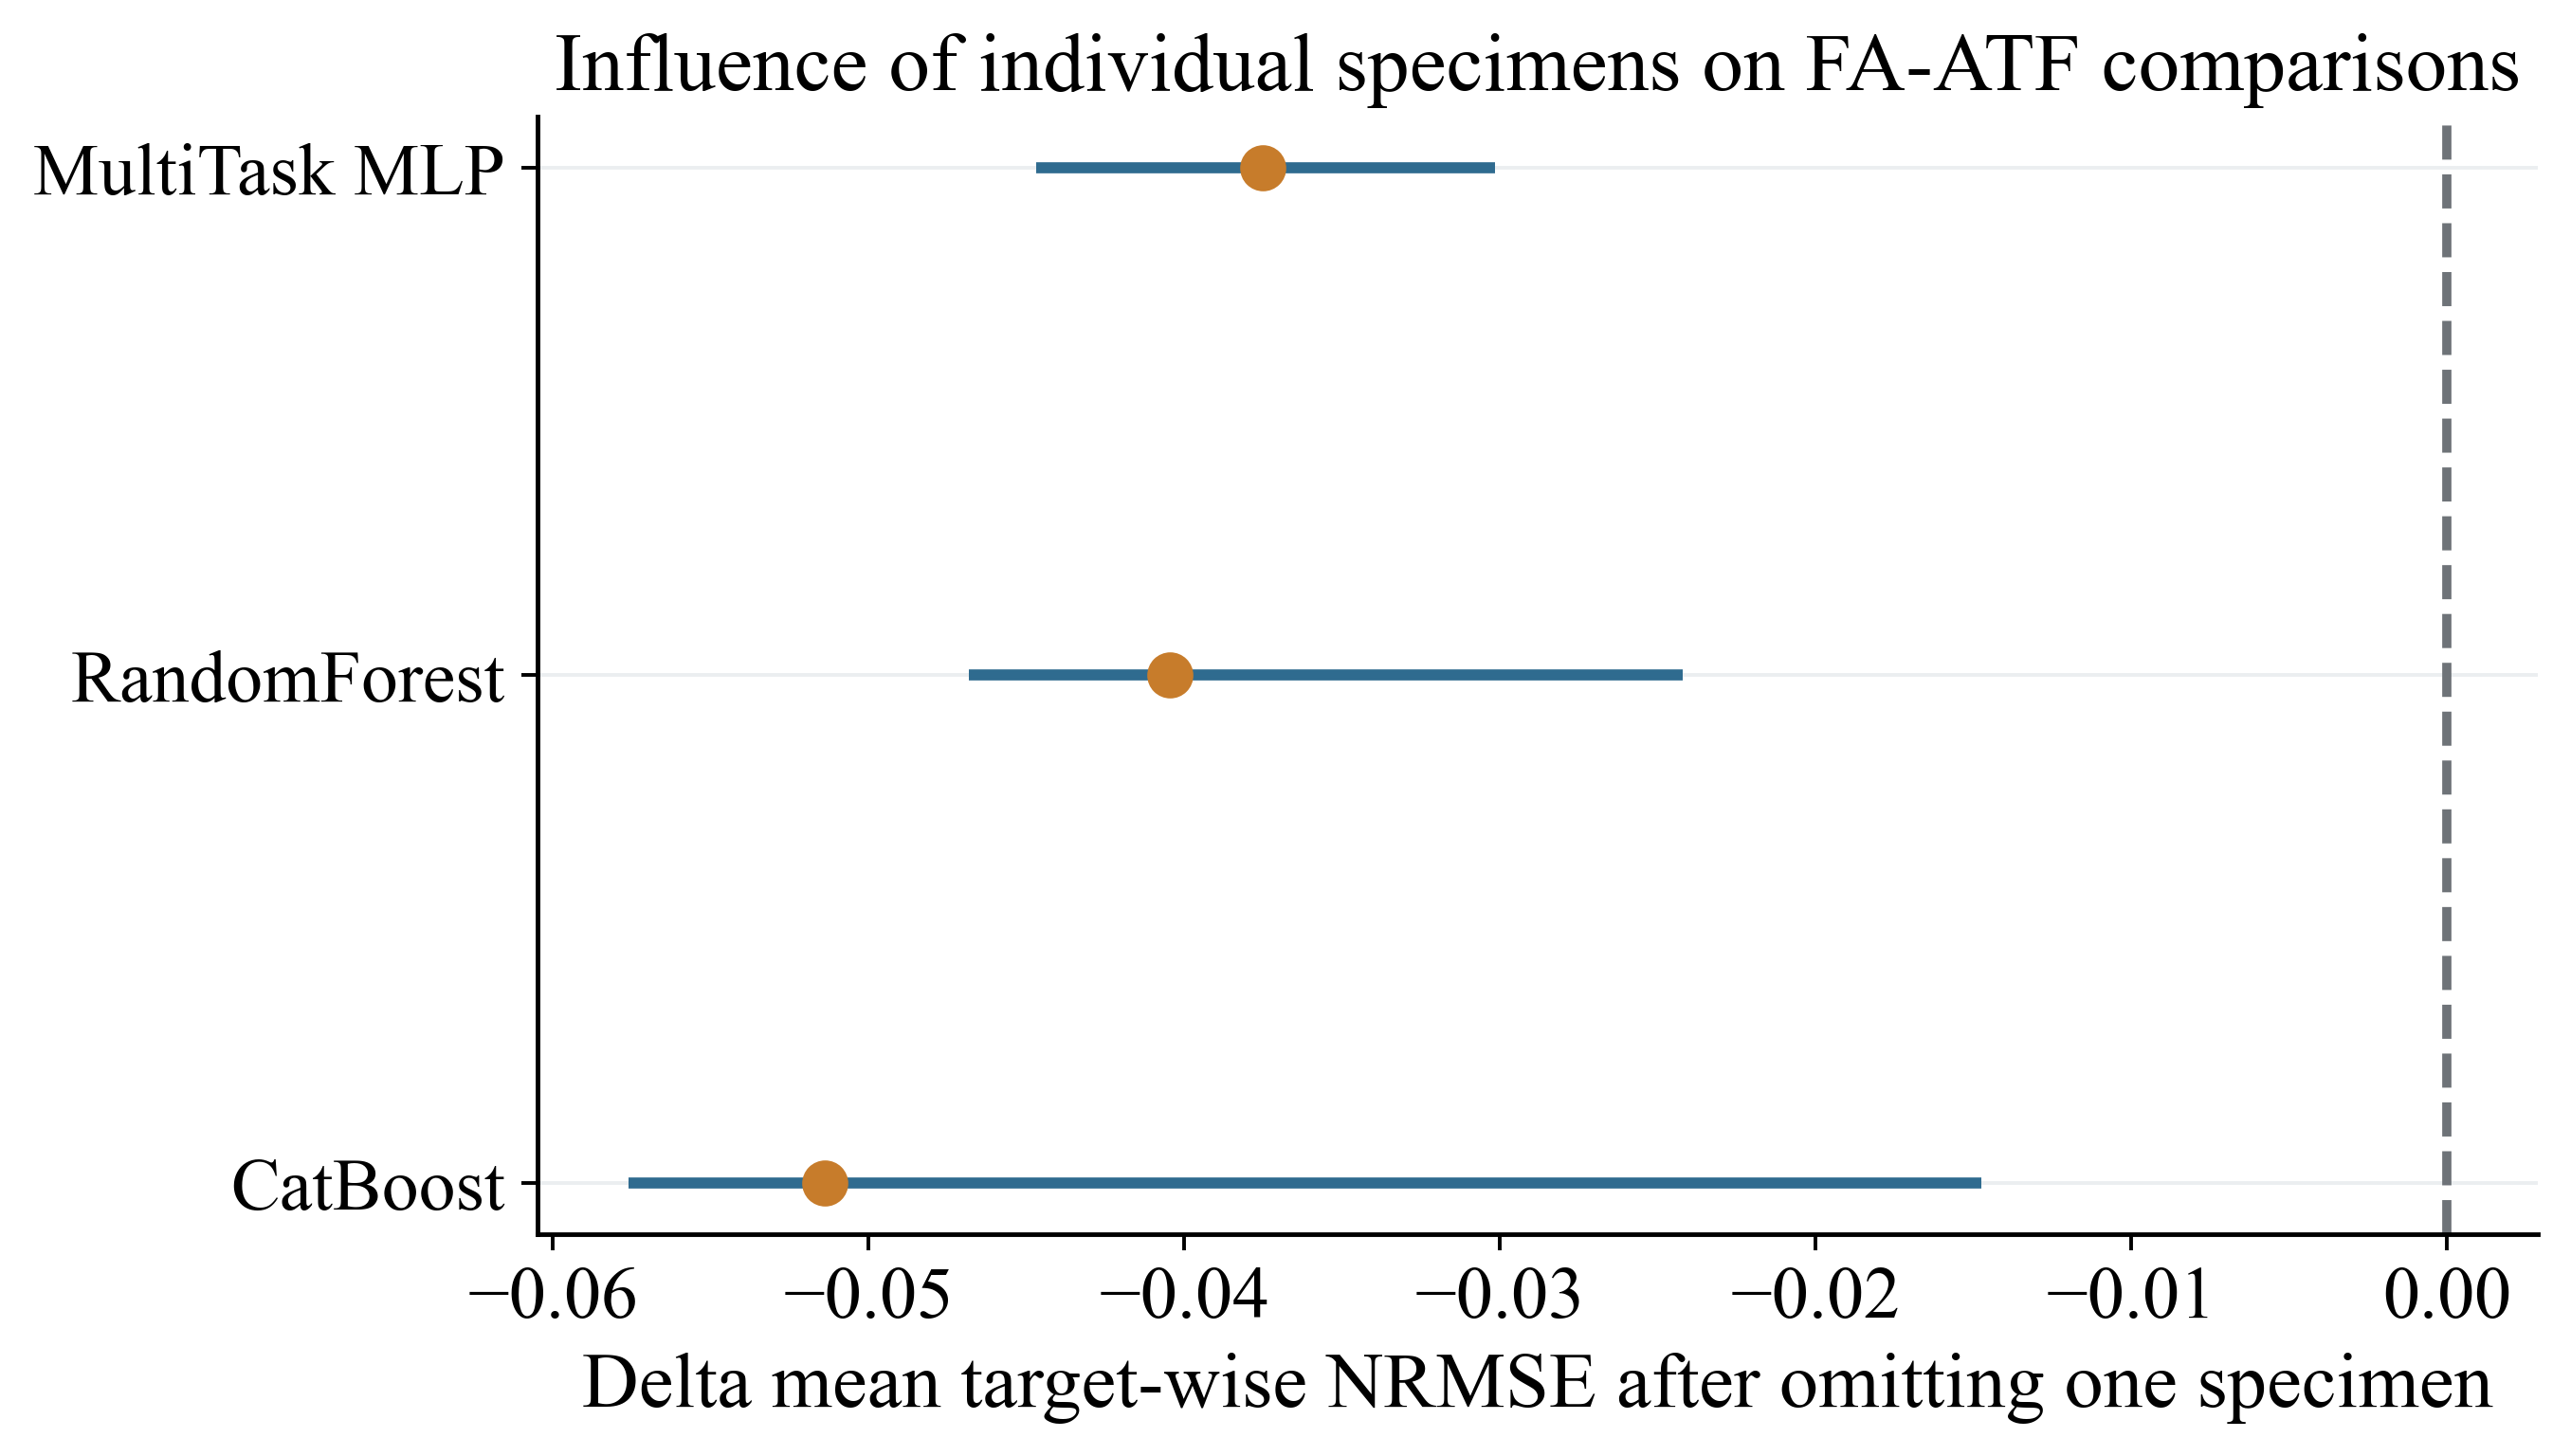

In [13]:
influence_plot = loo_summary.sort_values("median_delta").reset_index(drop=True)
fig, axis = plt.subplots(figsize=(9.0, 5.1))
for row_index, row in influence_plot.iterrows():
    axis.hlines(row_index, row.minimum_delta, row.maximum_delta, color=PALETTE["blue"], linewidth=2.4)
    axis.plot(row.median_delta, row_index, marker="o", color=PALETTE["orange"], markersize=9)
axis.axvline(0.0, color=PALETTE["gray"], linestyle="--")
axis.set_yticks(range(len(influence_plot)), labels=influence_plot.comparator)
axis.set_xlabel("Delta mean target-wise NRMSE after omitting one specimen")
axis.set_ylabel("")
axis.set_title("Influence of individual specimens on FA-ATF comparisons")
axis.grid(axis="x")
fig.subplots_adjust(left=0.31, right=0.98, bottom=0.20, top=0.86)
save_scientific_figure(fig, "fa_atf_leave_one_specimen_influence", leave_one_specimen)
display(fig)
plt.close(fig)


In [14]:
fa_rank_probability = rank_stability.set_index("model").loc["FA-ATF", "probability_rank_1"]
minimum_favorable_omissions = int(loo_summary.omissions_favoring_FA_ATF.min())
smallest_adjusted_randomization_p = sign_flip.one_sided_sign_flip_p_Holm.min()
display(Markdown(
    f"**Interpretation.** FA-ATF is rank 1 in {fa_rank_probability:.1%} of the "
    f"{N_BOOTSTRAP} specimen-bootstrap replicates. Its primary endpoint remains lower than every "
    f"pre-specified comparator after each of the {minimum_favorable_omissions} possible single-specimen "
    f"omissions. Nevertheless, the smallest Holm-adjusted sign-flip p-value is "
    f"{smallest_adjusted_randomization_p:.4f}; these analyses support internal stability but do not "
    "convert the study into independent confirmatory evidence."
))


**Interpretation.** FA-ATF is rank 1 in 83.0% of the 2000 specimen-bootstrap replicates. Its primary endpoint remains lower than every pre-specified comparator after each of the 27 possible single-specimen omissions. Nevertheless, the smallest Holm-adjusted sign-flip p-value is 0.0577; these analyses support internal stability but do not convert the study into independent confirmatory evidence.

## 9. Summarize one-component-at-a-time ablations

In [15]:
ablation_rows = []
for (variant, target), part in ablations.groupby(["variant", "target"]):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    ablation_rows.append({
        "variant": variant, "target": target,
        "MAE": mean_absolute_error(part.y_true, part.y_pred), "RMSE": rmse,
        "R2": r2_score(part.y_true, part.y_pred), "NRMSE": rmse / TARGET_SCALES[target],
    })
ablation_target_metrics = pd.DataFrame(ablation_rows)
ablation_summary = ablation_target_metrics.groupby("variant", as_index=False).agg(
    mean_NRMSE=("NRMSE", "mean"), macro_R2=("R2", "mean")
).sort_values("mean_NRMSE")
full_value = ablation_summary.set_index("variant").loc["Full FA-ATF", "mean_NRMSE"]
ablation_summary["delta_vs_full"] = ablation_summary.mean_NRMSE - full_value
ablation_summary.to_csv(
    METRIC_DIR / "fa_atf_ablation_article_summary.csv", index=False
)
display_grouped_table(ablation_summary.round(4), "FA-ATF ablation summary")

**FA-ATF ablation summary — Complete table**

variant,mean_NRMSE,macro_R2,delta_vs_full
Full FA-ATF,0.377300,0.854200,0.000000
Shared weights across targets,0.377300,0.854200,0.000000
Uniform fusion,0.377300,0.854100,0.000100
Strongest single branch only,0.377600,0.854000,0.000300
Without residual correction,0.378300,0.853400,0.001000
Without physics-guided/meta features,0.378500,0.853200,0.001200
Without factorial line-profile branch,0.470900,0.756500,0.093600


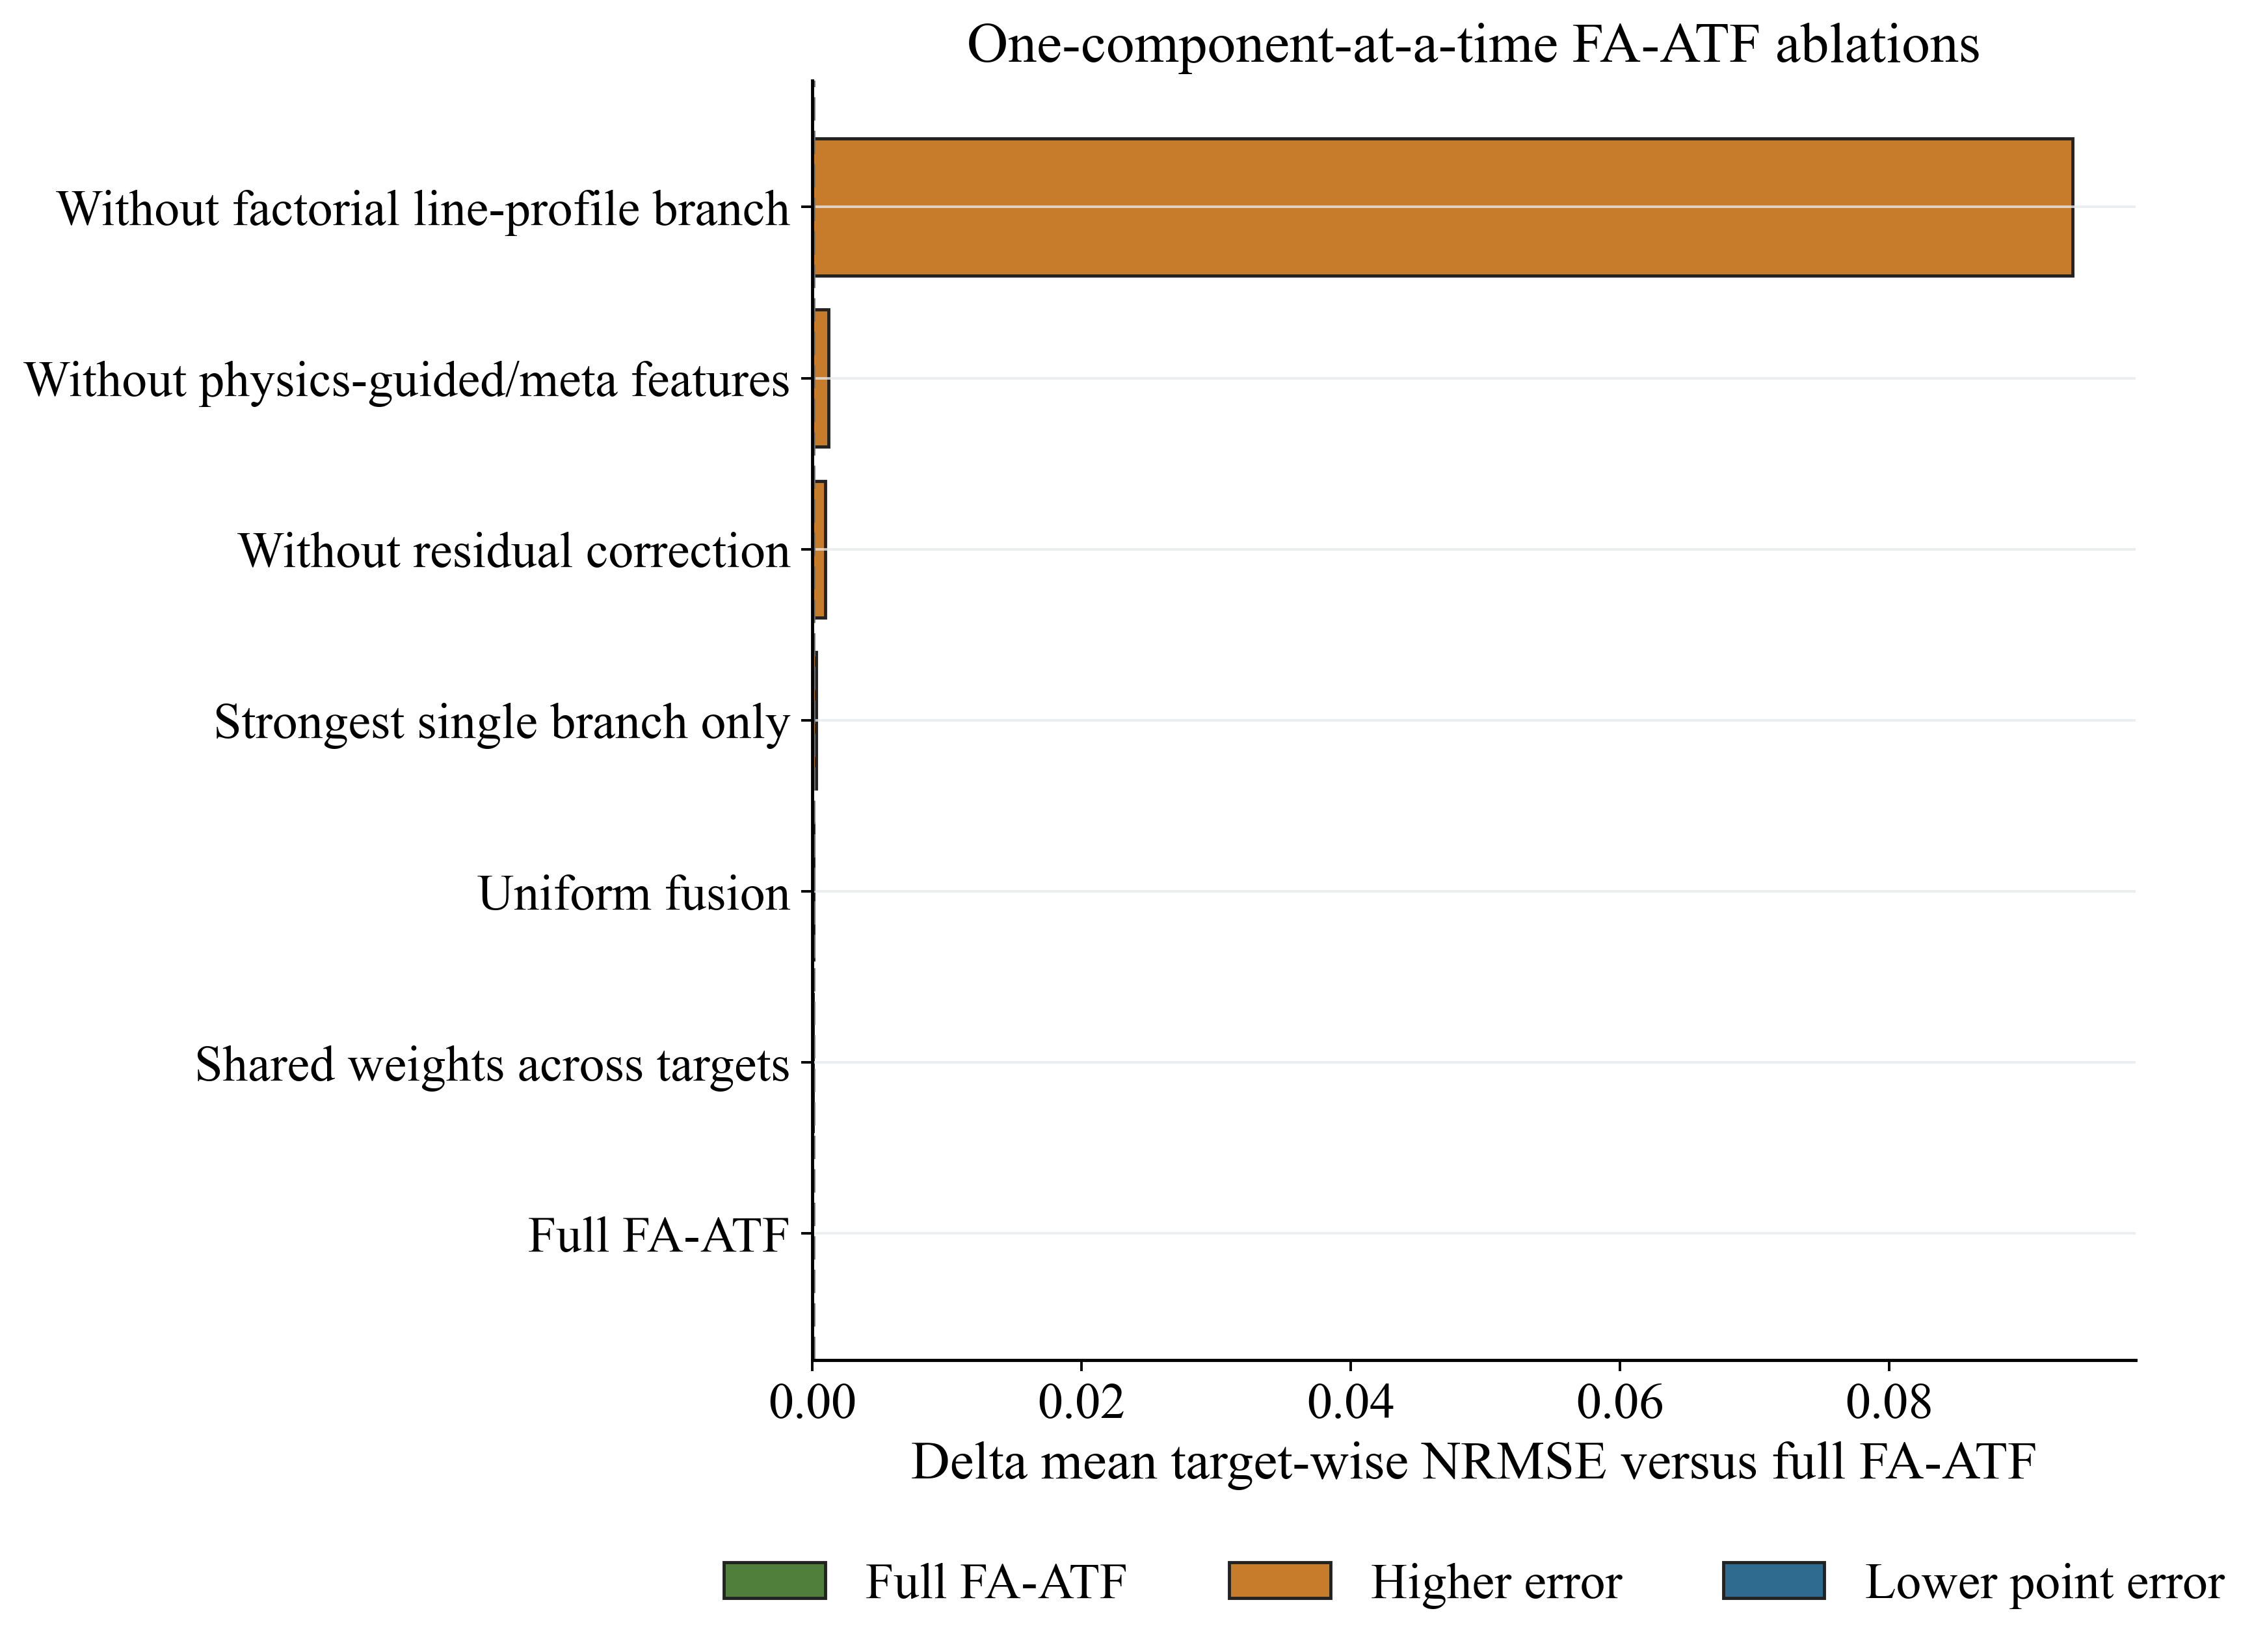

In [16]:
from matplotlib.patches import Patch

ablation_plot = ablation_summary.sort_values("delta_vs_full").reset_index(drop=True)
colors = [
    PALETTE["green"] if variant == "Full FA-ATF" else
    PALETTE["orange"] if value > 0 else PALETTE["blue"]
    for variant, value in zip(ablation_plot.variant, ablation_plot.delta_vs_full)
]
fig_height = max(7.6, 0.52 * len(ablation_plot) + 2.4)
fig, axis = plt.subplots(figsize=(10.2, fig_height))
axis.barh(ablation_plot.variant, ablation_plot.delta_vs_full,
          color=colors, edgecolor=PALETTE["black"])
axis.axvline(0.0, color=PALETTE["gray"], linestyle="--")
axis.set_title("One-component-at-a-time FA-ATF ablations")
axis.set_xlabel("Delta mean target-wise NRMSE versus full FA-ATF")
axis.set_ylabel("")
axis.grid(axis="x")
legend_handles = [
    Patch(facecolor=PALETTE["green"], edgecolor=PALETTE["black"], label="Full FA-ATF"),
    Patch(facecolor=PALETTE["orange"], edgecolor=PALETTE["black"], label="Higher error"),
    Patch(facecolor=PALETTE["blue"], edgecolor=PALETTE["black"], label="Lower point error"),
]
axis.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.23),
            ncol=3, frameon=False)
fig.subplots_adjust(left=0.41, right=0.98, top=0.91, bottom=0.17)
save_scientific_figure(fig, "fa_atf_ablation_differences", ablation_plot)
display(fig)
plt.close(fig)

## 10. Evaluate group-cross-fitted residual-interval coverage, width, and score

In [17]:
uncertainty_rows = []
rng_uncertainty = np.random.default_rng(SEED + 91)
for target, part in uncertainty.groupby("target"):
    part = part.copy()
    groups = part.specimen_id.unique()
    interval_score = (
        (part.upper_90 - part.lower_90)
        + 20.0 * np.maximum(part.lower_90 - part.y_true, 0.0)
        + 20.0 * np.maximum(part.y_true - part.upper_90, 0.0)
    )
    coverage_boot, profile_coverage_boot, width_boot, score_boot = [], [], [], []
    for _ in range(N_BOOTSTRAP):
        sampled = rng_uncertainty.choice(groups, len(groups), replace=True)
        boot = pd.concat([part[part.specimen_id.eq(group)] for group in sampled], ignore_index=True)
        coverage_boot.append(np.mean((boot.y_true >= boot.lower_90) & (boot.y_true <= boot.upper_90)))
        profile_coverage_boot.append(np.mean([
            ((part.loc[part.specimen_id.eq(group), 'y_true'] >= part.loc[part.specimen_id.eq(group), 'lower_90'])
             & (part.loc[part.specimen_id.eq(group), 'y_true'] <= part.loc[part.specimen_id.eq(group), 'upper_90'])).all()
            for group in sampled
        ]))
        width_boot.append(np.mean(boot.upper_90 - boot.lower_90))
        score_boot.append(np.mean(
            (boot.upper_90 - boot.lower_90)
            + 20.0 * np.maximum(boot.lower_90 - boot.y_true, 0.0)
            + 20.0 * np.maximum(boot.y_true - boot.upper_90, 0.0)
        ))
    uncertainty_rows.append({
        "target": target, "nominal_coverage": 0.90,
        "empirical_coverage": np.mean((part.y_true >= part.lower_90) & (part.y_true <= part.upper_90)),
        "coverage_CI_low": np.quantile(coverage_boot, 0.025), "coverage_CI_high": np.quantile(coverage_boot, 0.975),
        "specimen_profile_coverage": part.assign(covered=(part.y_true >= part.lower_90) & (part.y_true <= part.upper_90)).groupby('specimen_id').covered.all().mean(),
        "profile_coverage_CI_low": np.quantile(profile_coverage_boot, 0.025), "profile_coverage_CI_high": np.quantile(profile_coverage_boot, 0.975),
        "mean_interval_width": np.mean(part.upper_90 - part.lower_90),
        "median_interval_width": np.median(part.upper_90 - part.lower_90),
        "width_CI_low": np.quantile(width_boot, 0.025), "width_CI_high": np.quantile(width_boot, 0.975),
        "normalized_mean_width": np.mean(part.upper_90 - part.lower_90) / TARGET_SCALES[target],
        "normalized_median_width": np.median(part.upper_90 - part.lower_90) / TARGET_SCALES[target],
        "mean_interval_score_90": np.mean(interval_score),
        "interval_score_CI_low": np.quantile(score_boot, 0.025),
        "interval_score_CI_high": np.quantile(score_boot, 0.975),
        "normalized_mean_interval_score_90": np.mean(interval_score) / TARGET_SCALES[target],
    })
uncertainty_summary = pd.DataFrame(uncertainty_rows)
uncertainty_summary.to_csv(METRIC_DIR / "fa_atf_uncertainty_summary_with_ci.csv", index=False)
display_grouped_table(uncertainty_summary.round(4), "FA-ATF uncertainty performance with bootstrap intervals")

**FA-ATF uncertainty performance with bootstrap intervals — Predictive performance**

target,mean_interval_score_90,interval_score_CI_low,interval_score_CI_high,normalized_mean_interval_score_90
post_process_hardness_HV30,73.215900,70.634100,76.129100,1.604700
surface_roughness_Ra_um,3.169400,2.792200,3.701200,3.717300


**FA-ATF uncertainty performance with bootstrap intervals — Uncertainty and statistical evidence (part 1/3)**

target,nominal_coverage,empirical_coverage,coverage_CI_low,coverage_CI_high,specimen_profile_coverage
post_process_hardness_HV30,0.900000,0.987700,0.963000,1.000000,0.963000
surface_roughness_Ra_um,0.900000,0.963000,0.888900,1.000000,0.963000


**FA-ATF uncertainty performance with bootstrap intervals — Uncertainty and statistical evidence (part 2/3)**

target,profile_coverage_CI_low,profile_coverage_CI_high,mean_interval_width,median_interval_width,width_CI_low
post_process_hardness_HV30,0.888900,1.000000,73.168900,72.906900,70.539200
surface_roughness_Ra_um,0.888900,1.000000,2.901100,3.043000,2.677900


**FA-ATF uncertainty performance with bootstrap intervals — Uncertainty and statistical evidence (part 3/3)**

target,width_CI_high
post_process_hardness_HV30,76.081900
surface_roughness_Ra_um,3.106900


**FA-ATF uncertainty performance with bootstrap intervals — Sample, fold, and provenance**

target,normalized_mean_width,normalized_median_width
post_process_hardness_HV30,1.603700,1.598000
surface_roughness_Ra_um,3.402600,3.569000


Section-wise and whole-specimen-profile coverage are interpreted together with normalized width and the central 90% interval score; high coverage alone is not useful if intervals are excessively wide. Calibration uses training-side group-cross-fitted specimen-maximum residual scores within each outer fold. These are nominal specimen-aware residual intervals, not independent split-conformal intervals with an exact finite-sample guarantee. Conditional coverage by domain distance is an internal robustness diagnostic, not external validation.


## 11. Plot actual versus predicted values for focal models

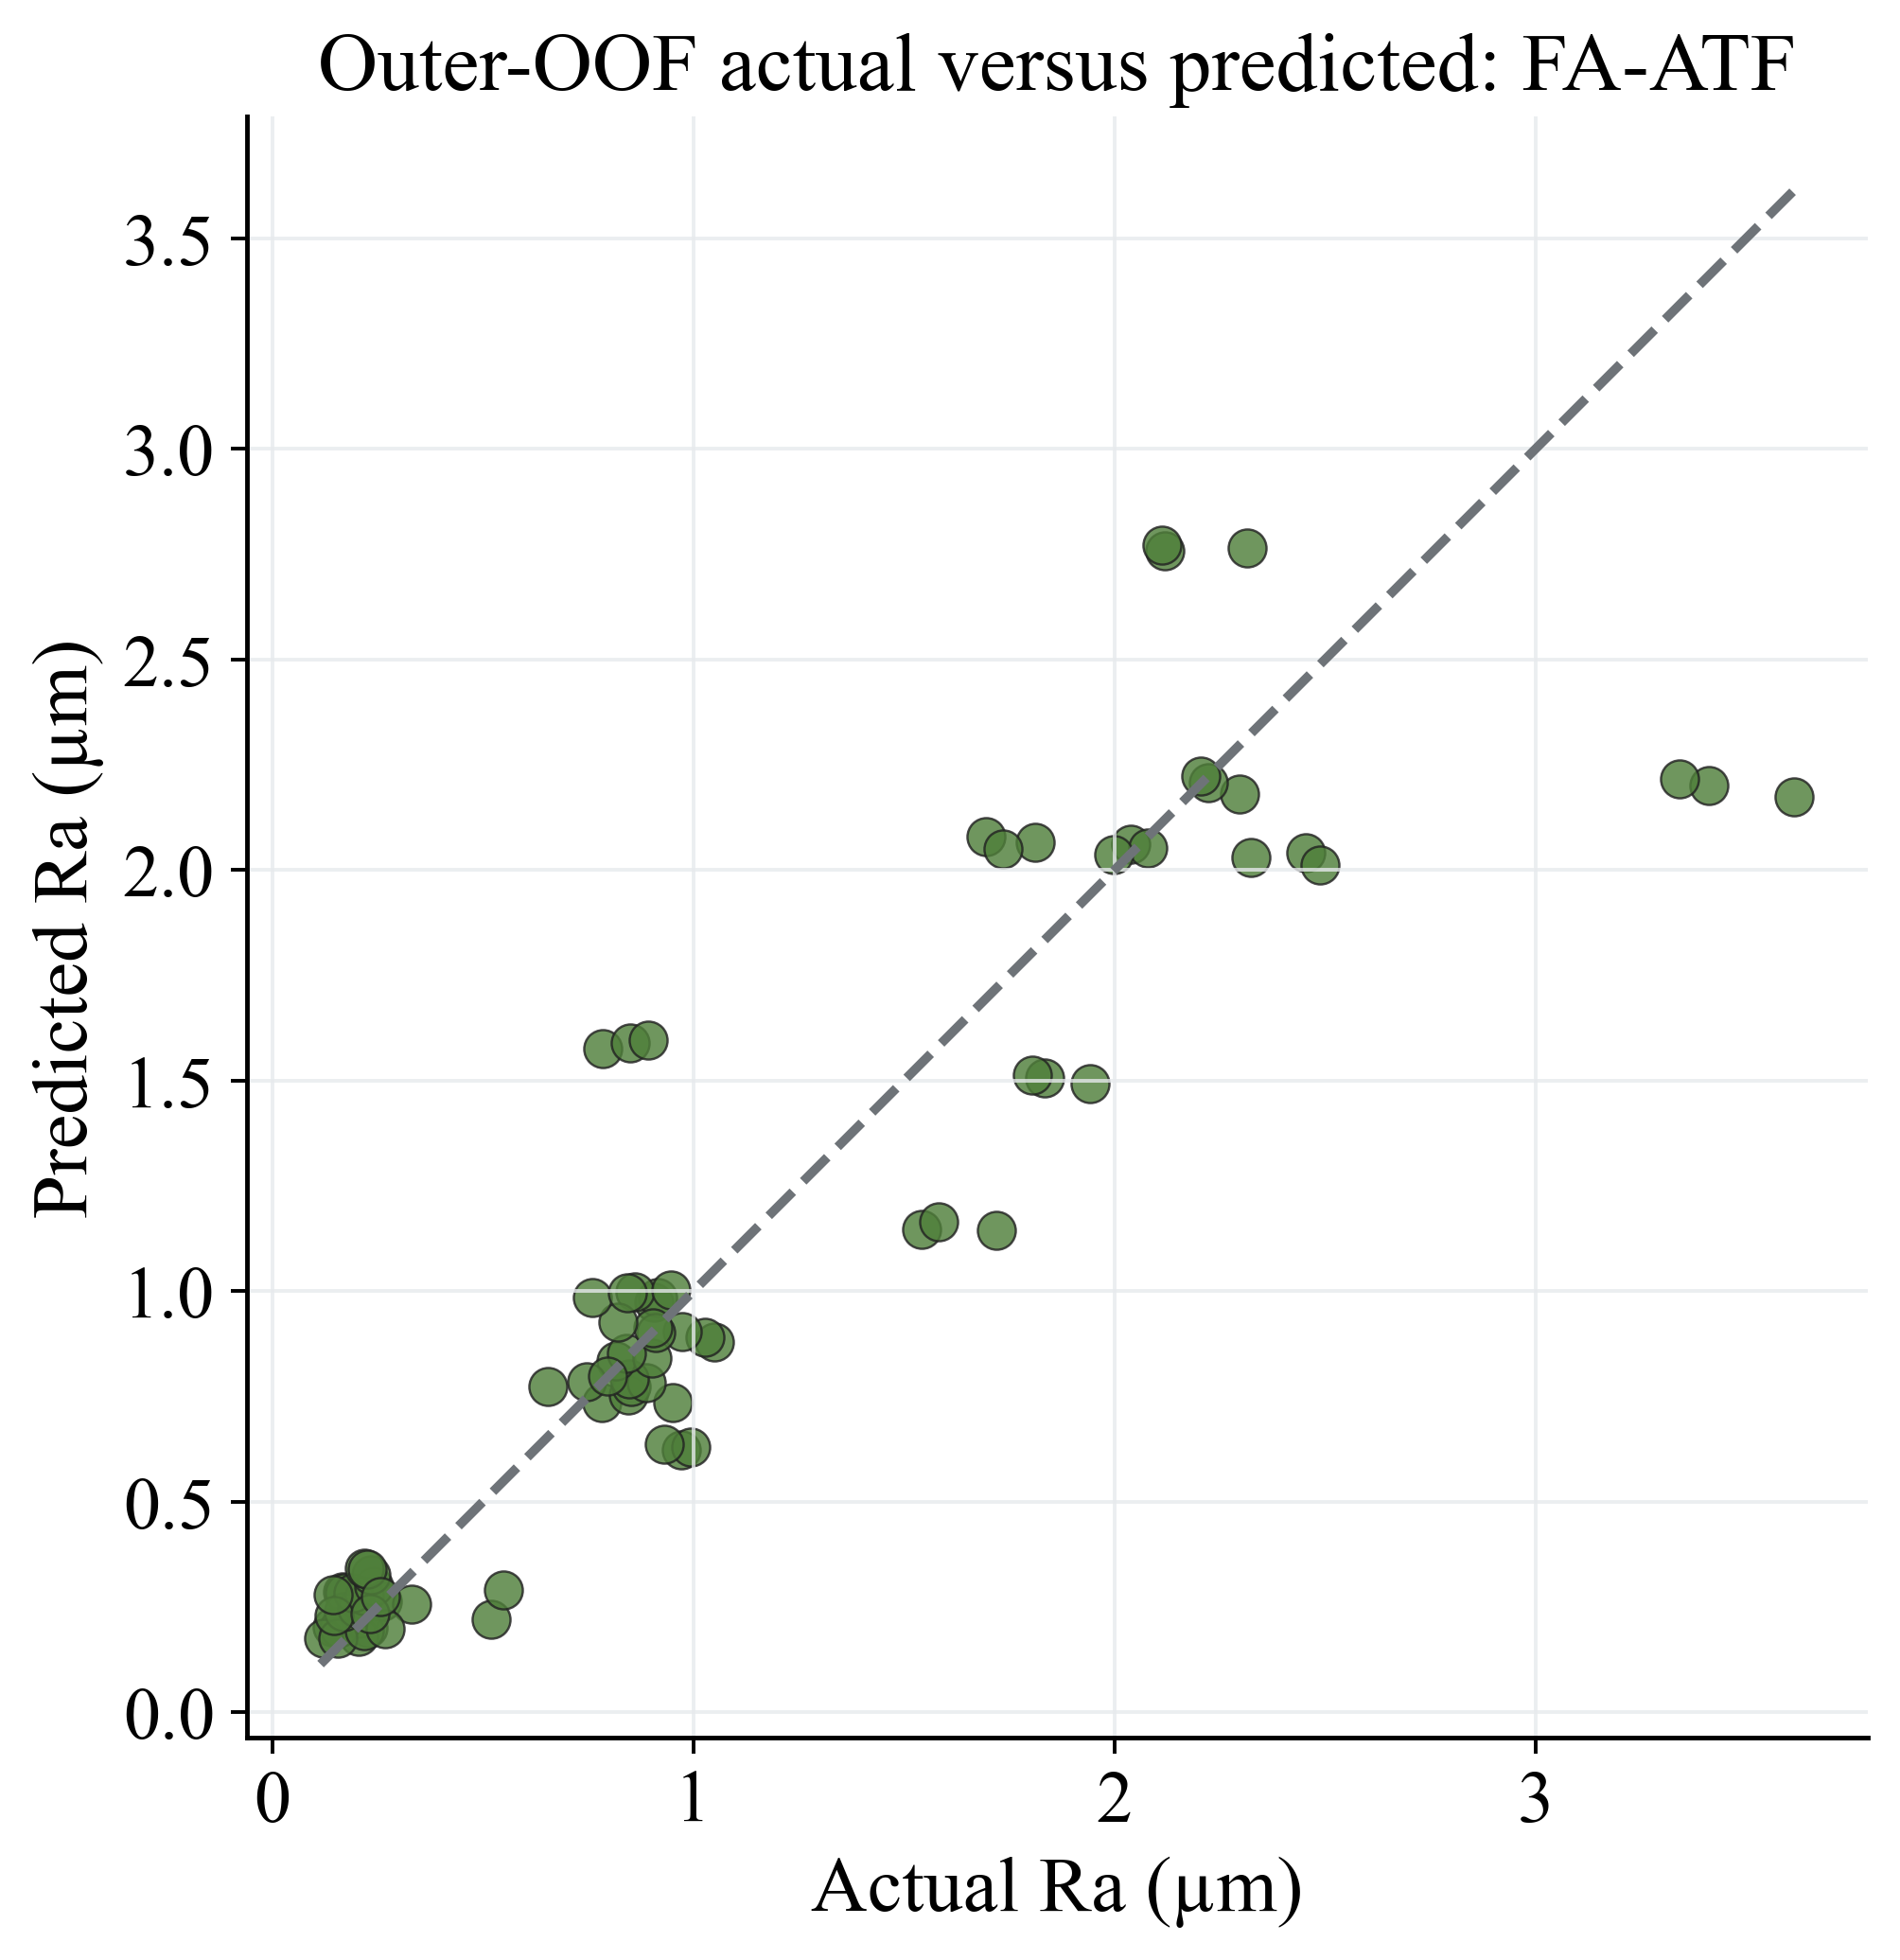

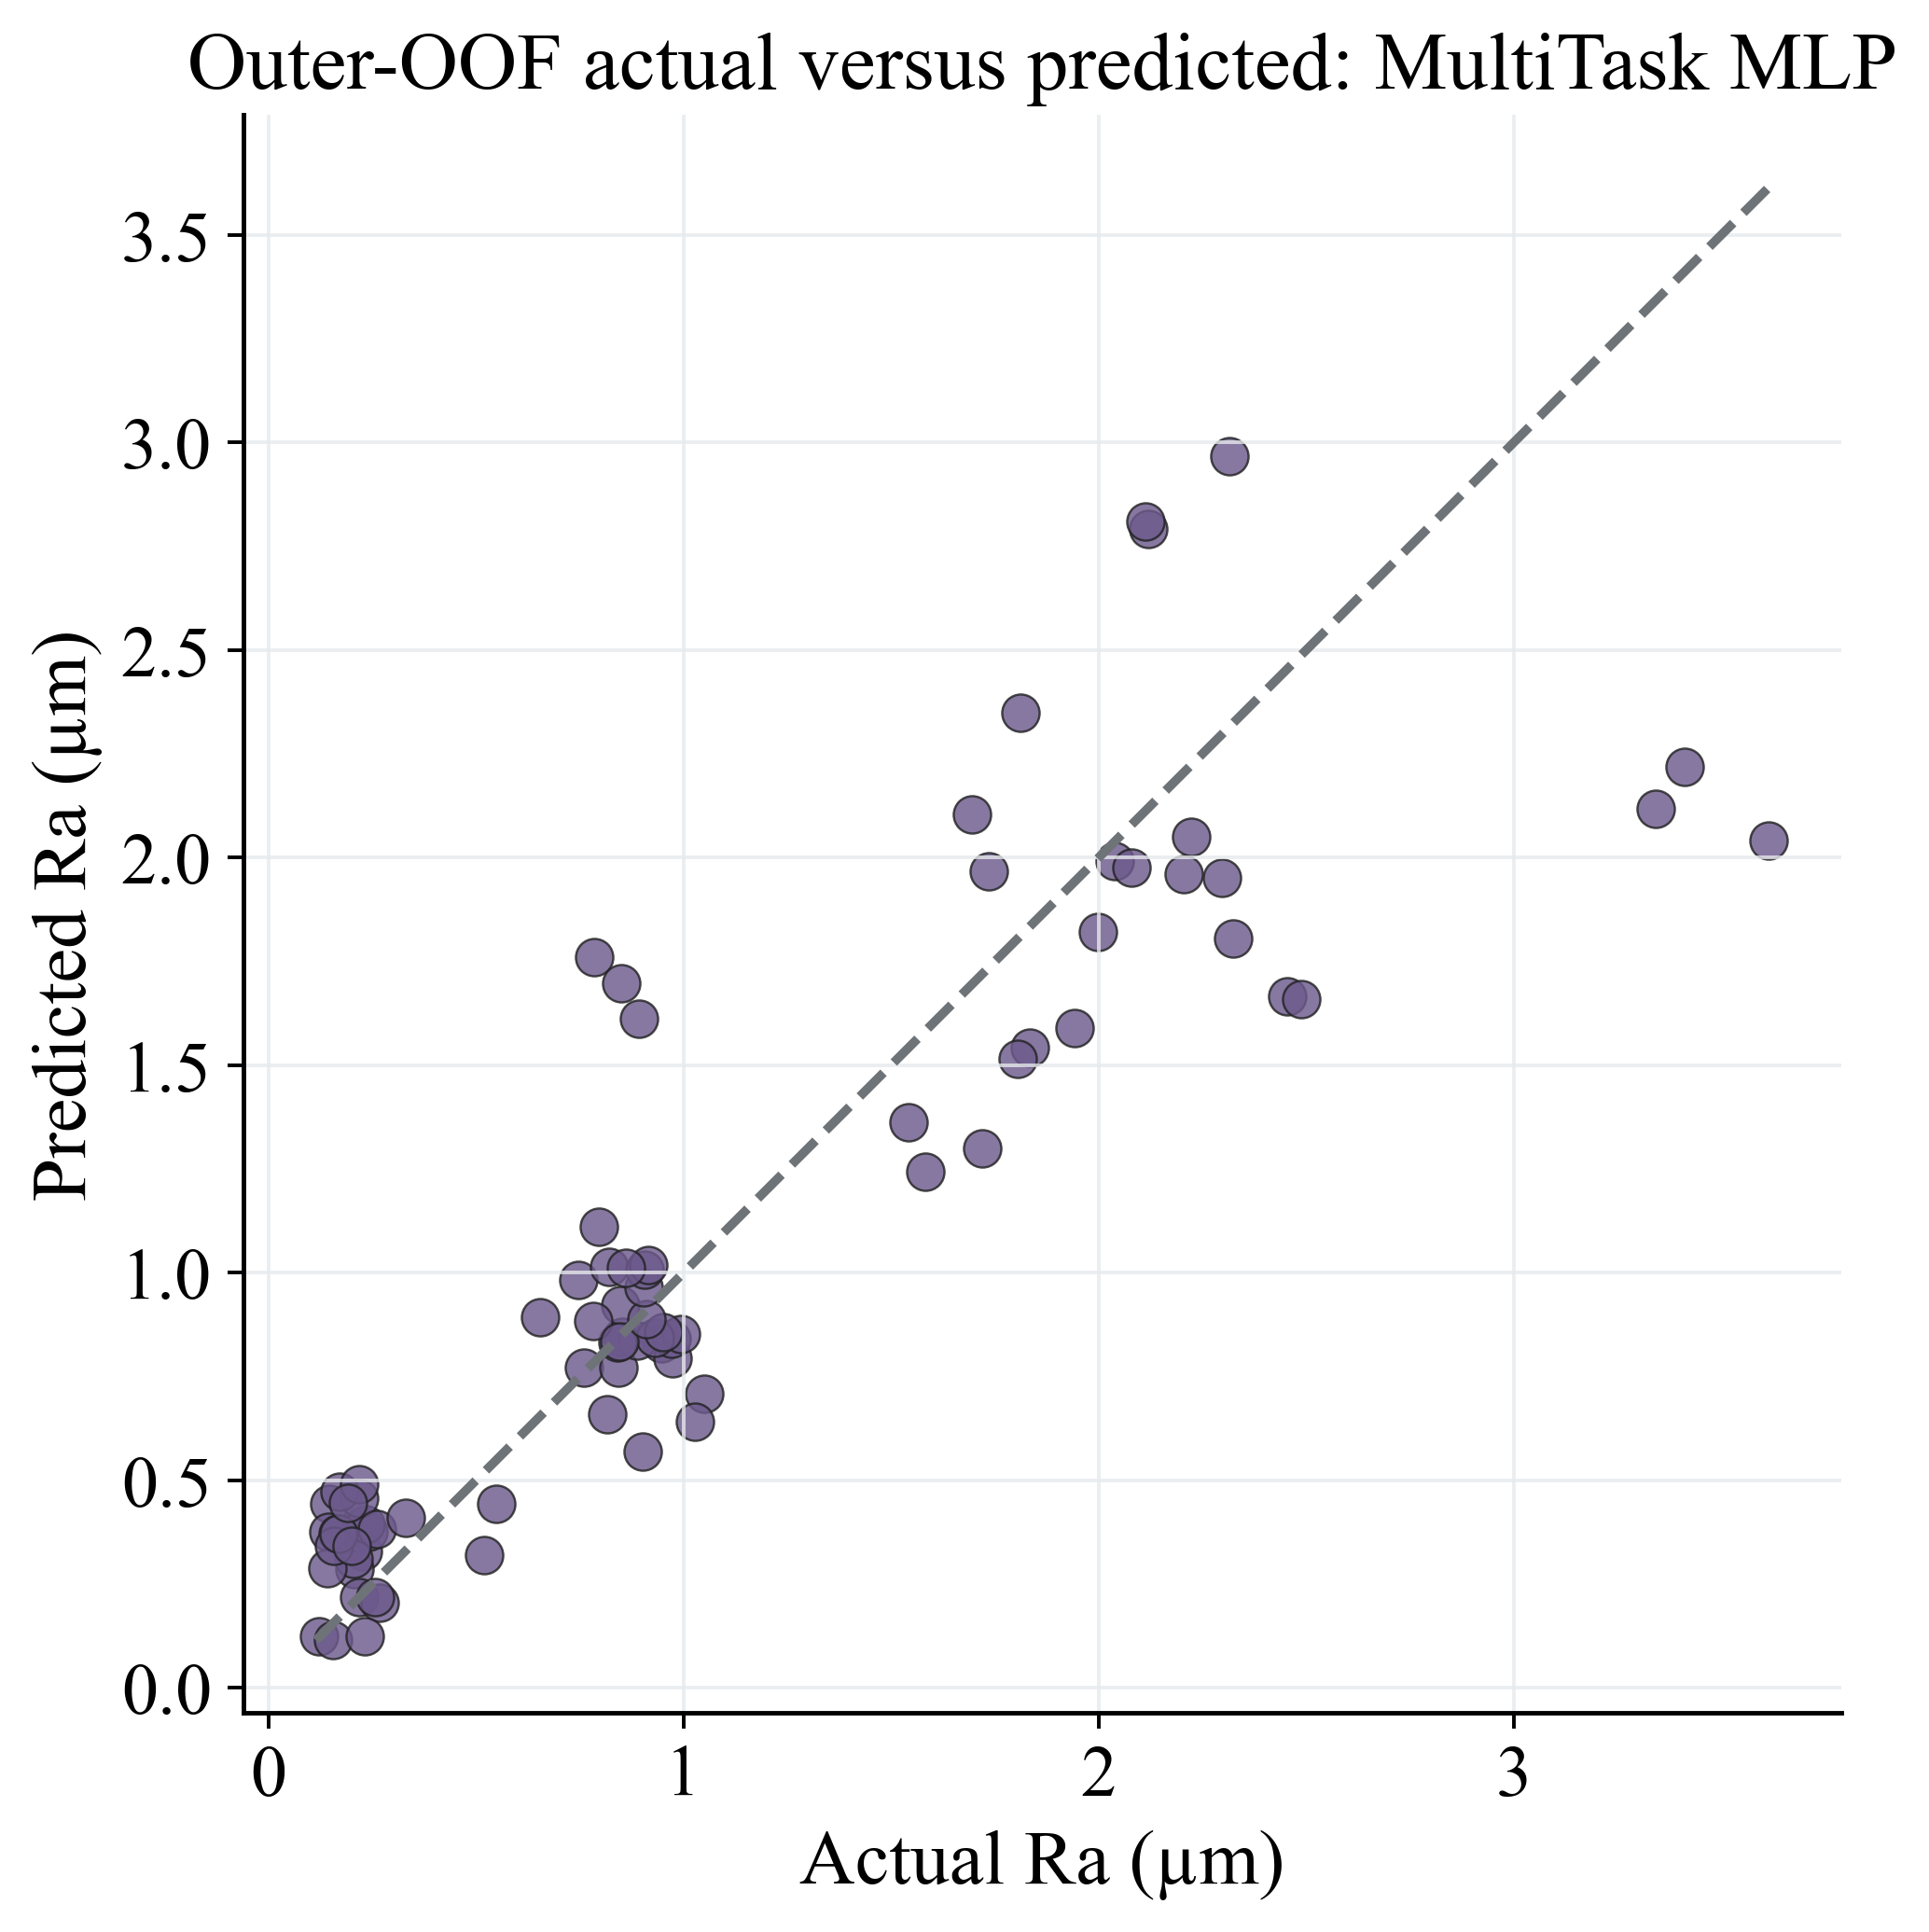

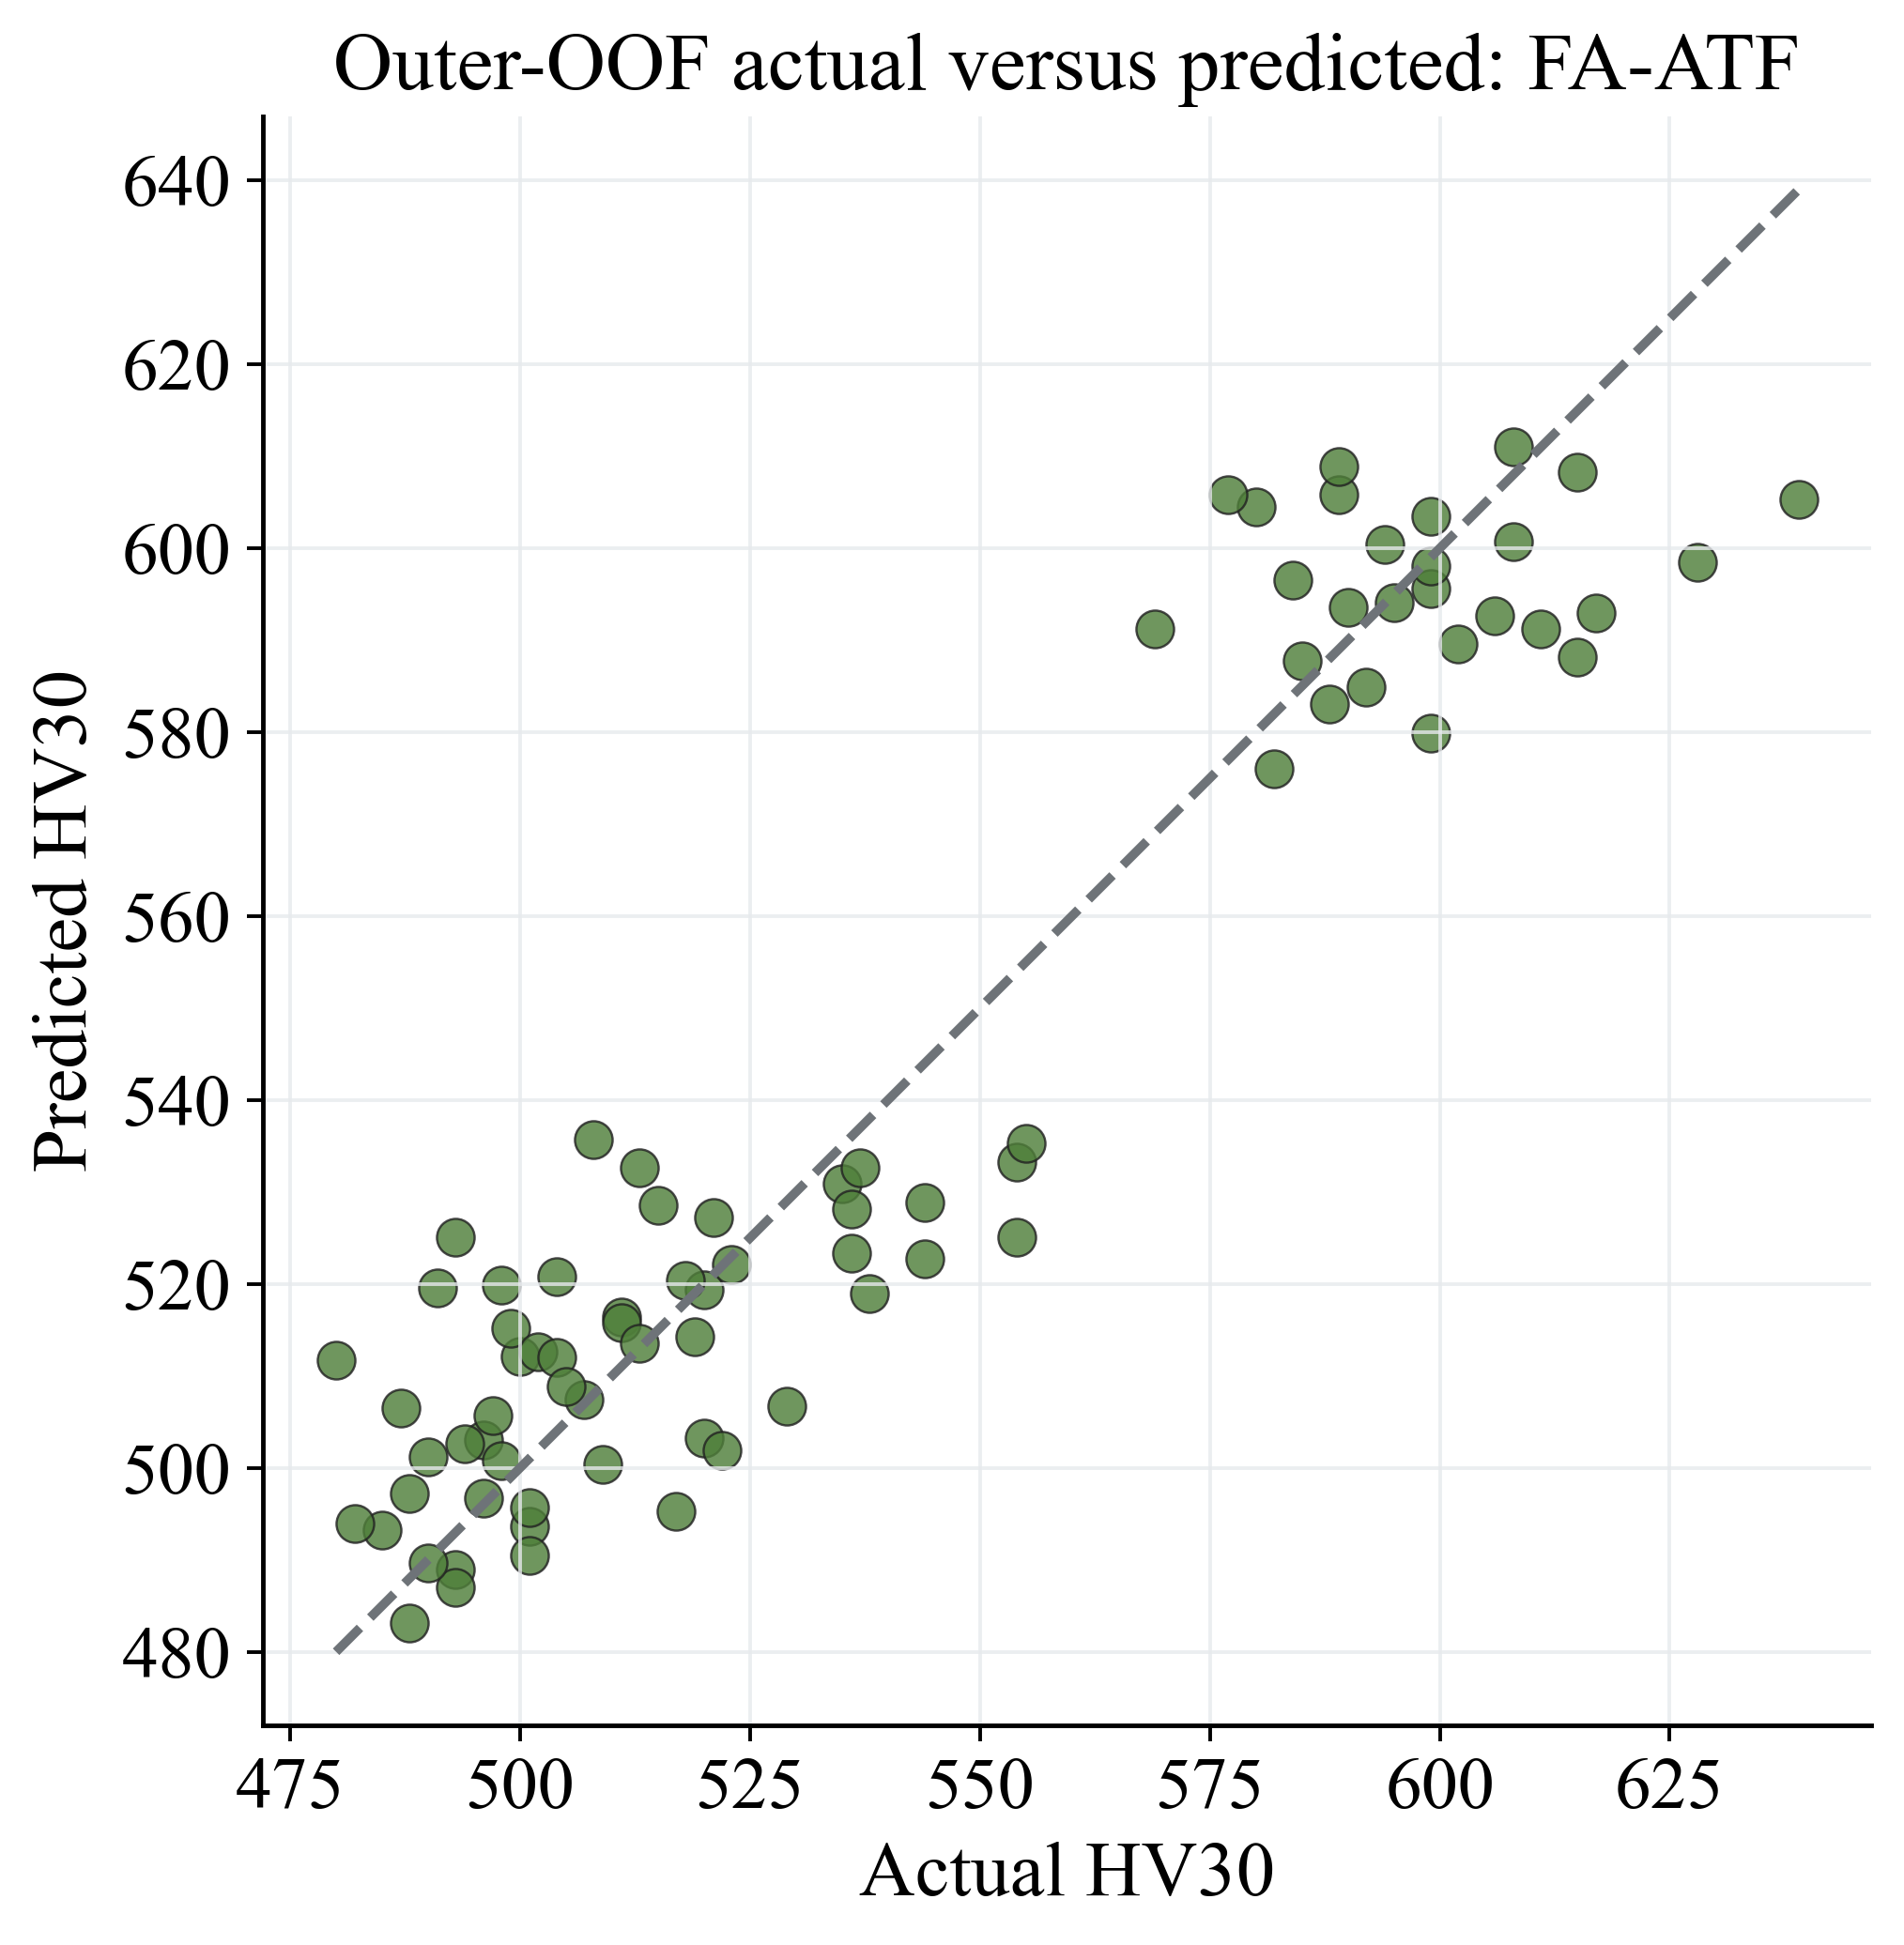

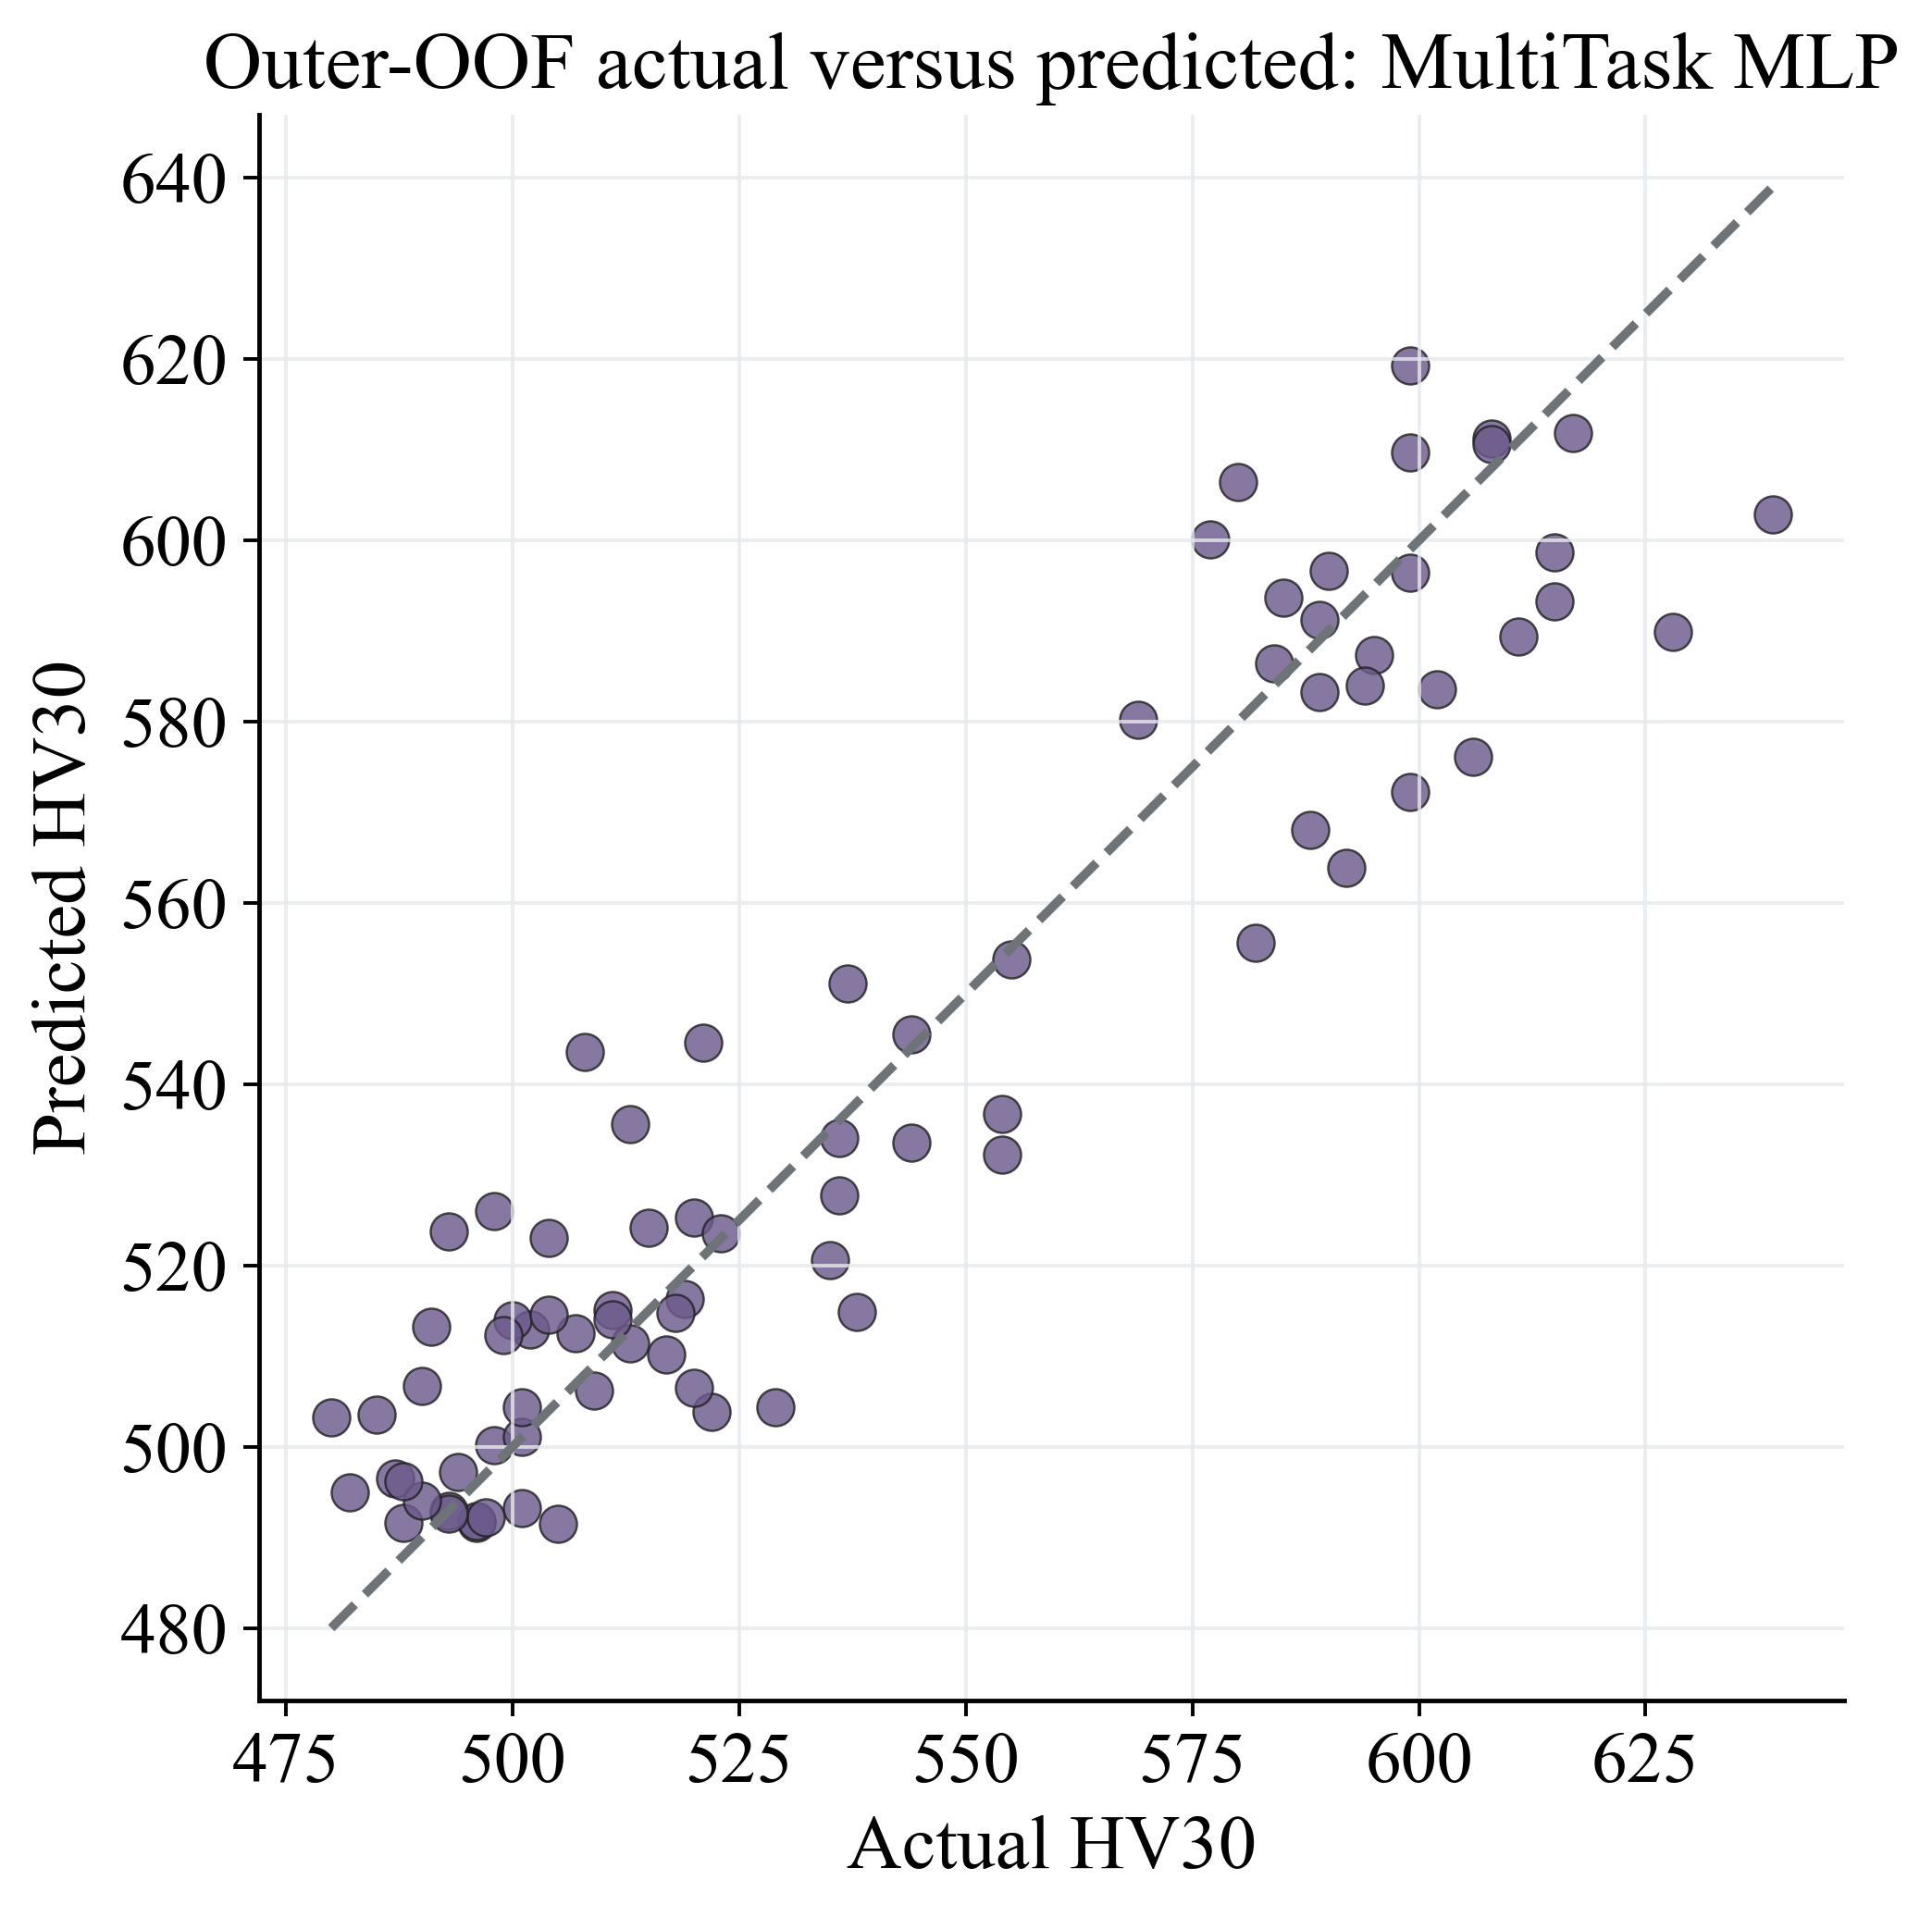

In [18]:
focal_models = list(dict.fromkeys([ranking.iloc[0].model, "FA-ATF", best_dl]))
model_slugs = {model: model.lower().replace(" ", "_").replace("-", "_") for model in focal_models}
for target in TARGETS:
    target_slug = "ra" if target == TARGETS[0] else "hv30"
    figure_source = all_predictions[
        all_predictions.target.eq(target) & all_predictions.model.isin(focal_models)
    ][["sample_id", "specimen_id", "model", "y_true", "y_pred"]].copy()
    minimum = min(figure_source.y_true.min(), figure_source.y_pred.min())
    maximum = max(figure_source.y_true.max(), figure_source.y_pred.max())
    for model in focal_models:
        part = figure_source[figure_source.model.eq(model)]
        color = PALETTE["green"] if model == "FA-ATF" else PALETTE["purple"] if model == best_dl else PALETTE["blue"]
        fig, axis = plt.subplots(figsize=(7.0, 6.2))
        axis.scatter(part.y_true, part.y_pred, s=68, color=color,
                     edgecolor=PALETTE["black"], linewidth=0.5, alpha=0.82)
        axis.plot([minimum, maximum], [minimum, maximum], color=PALETTE["gray"], linestyle="--")
        axis.set_title(f"Outer-OOF actual versus predicted: {model}")
        axis.set_xlabel("Actual Ra (µm)" if target == TARGETS[0] else "Actual HV30")
        axis.set_ylabel("Predicted Ra (µm)" if target == TARGETS[0] else "Predicted HV30")
        axis.set_aspect("equal", adjustable="box")
        fig.tight_layout()
        stem = f"actual_predicted_{target_slug}_{model_slugs[model]}"
        save_scientific_figure(fig, stem, part)
        display(fig)
        plt.close(fig)

## 12. Inspect residual distributions and target-wise fusion weights

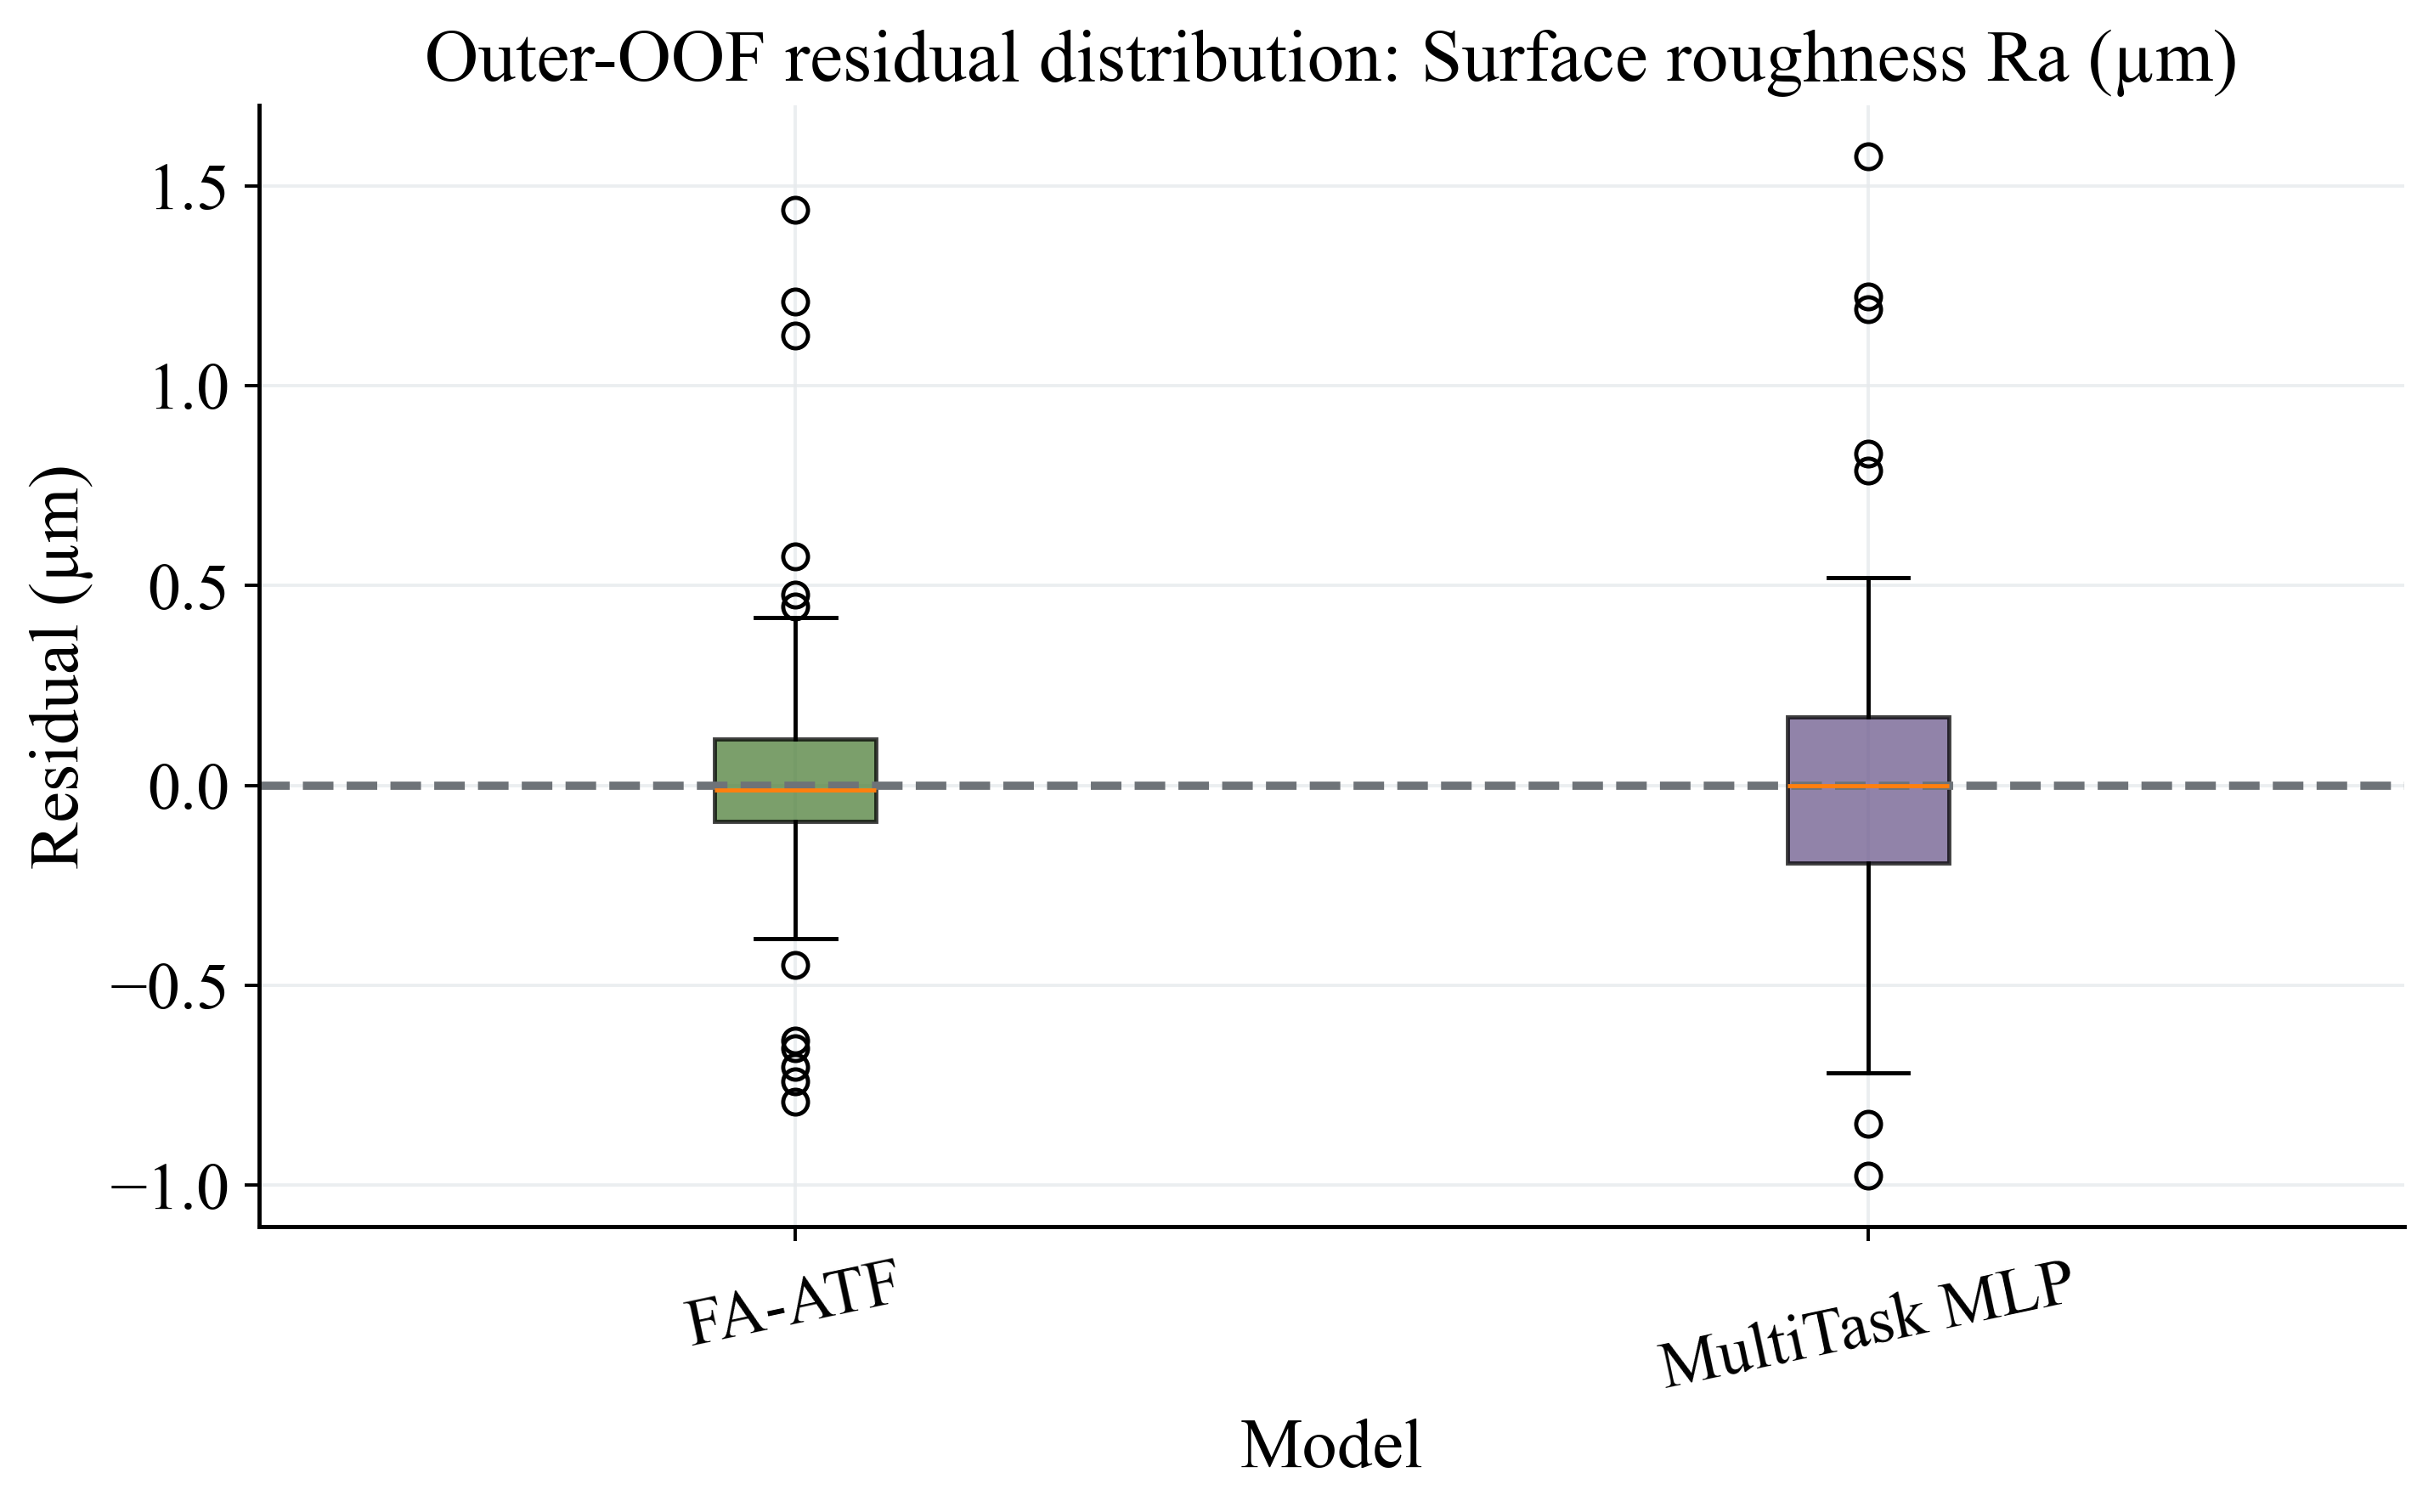

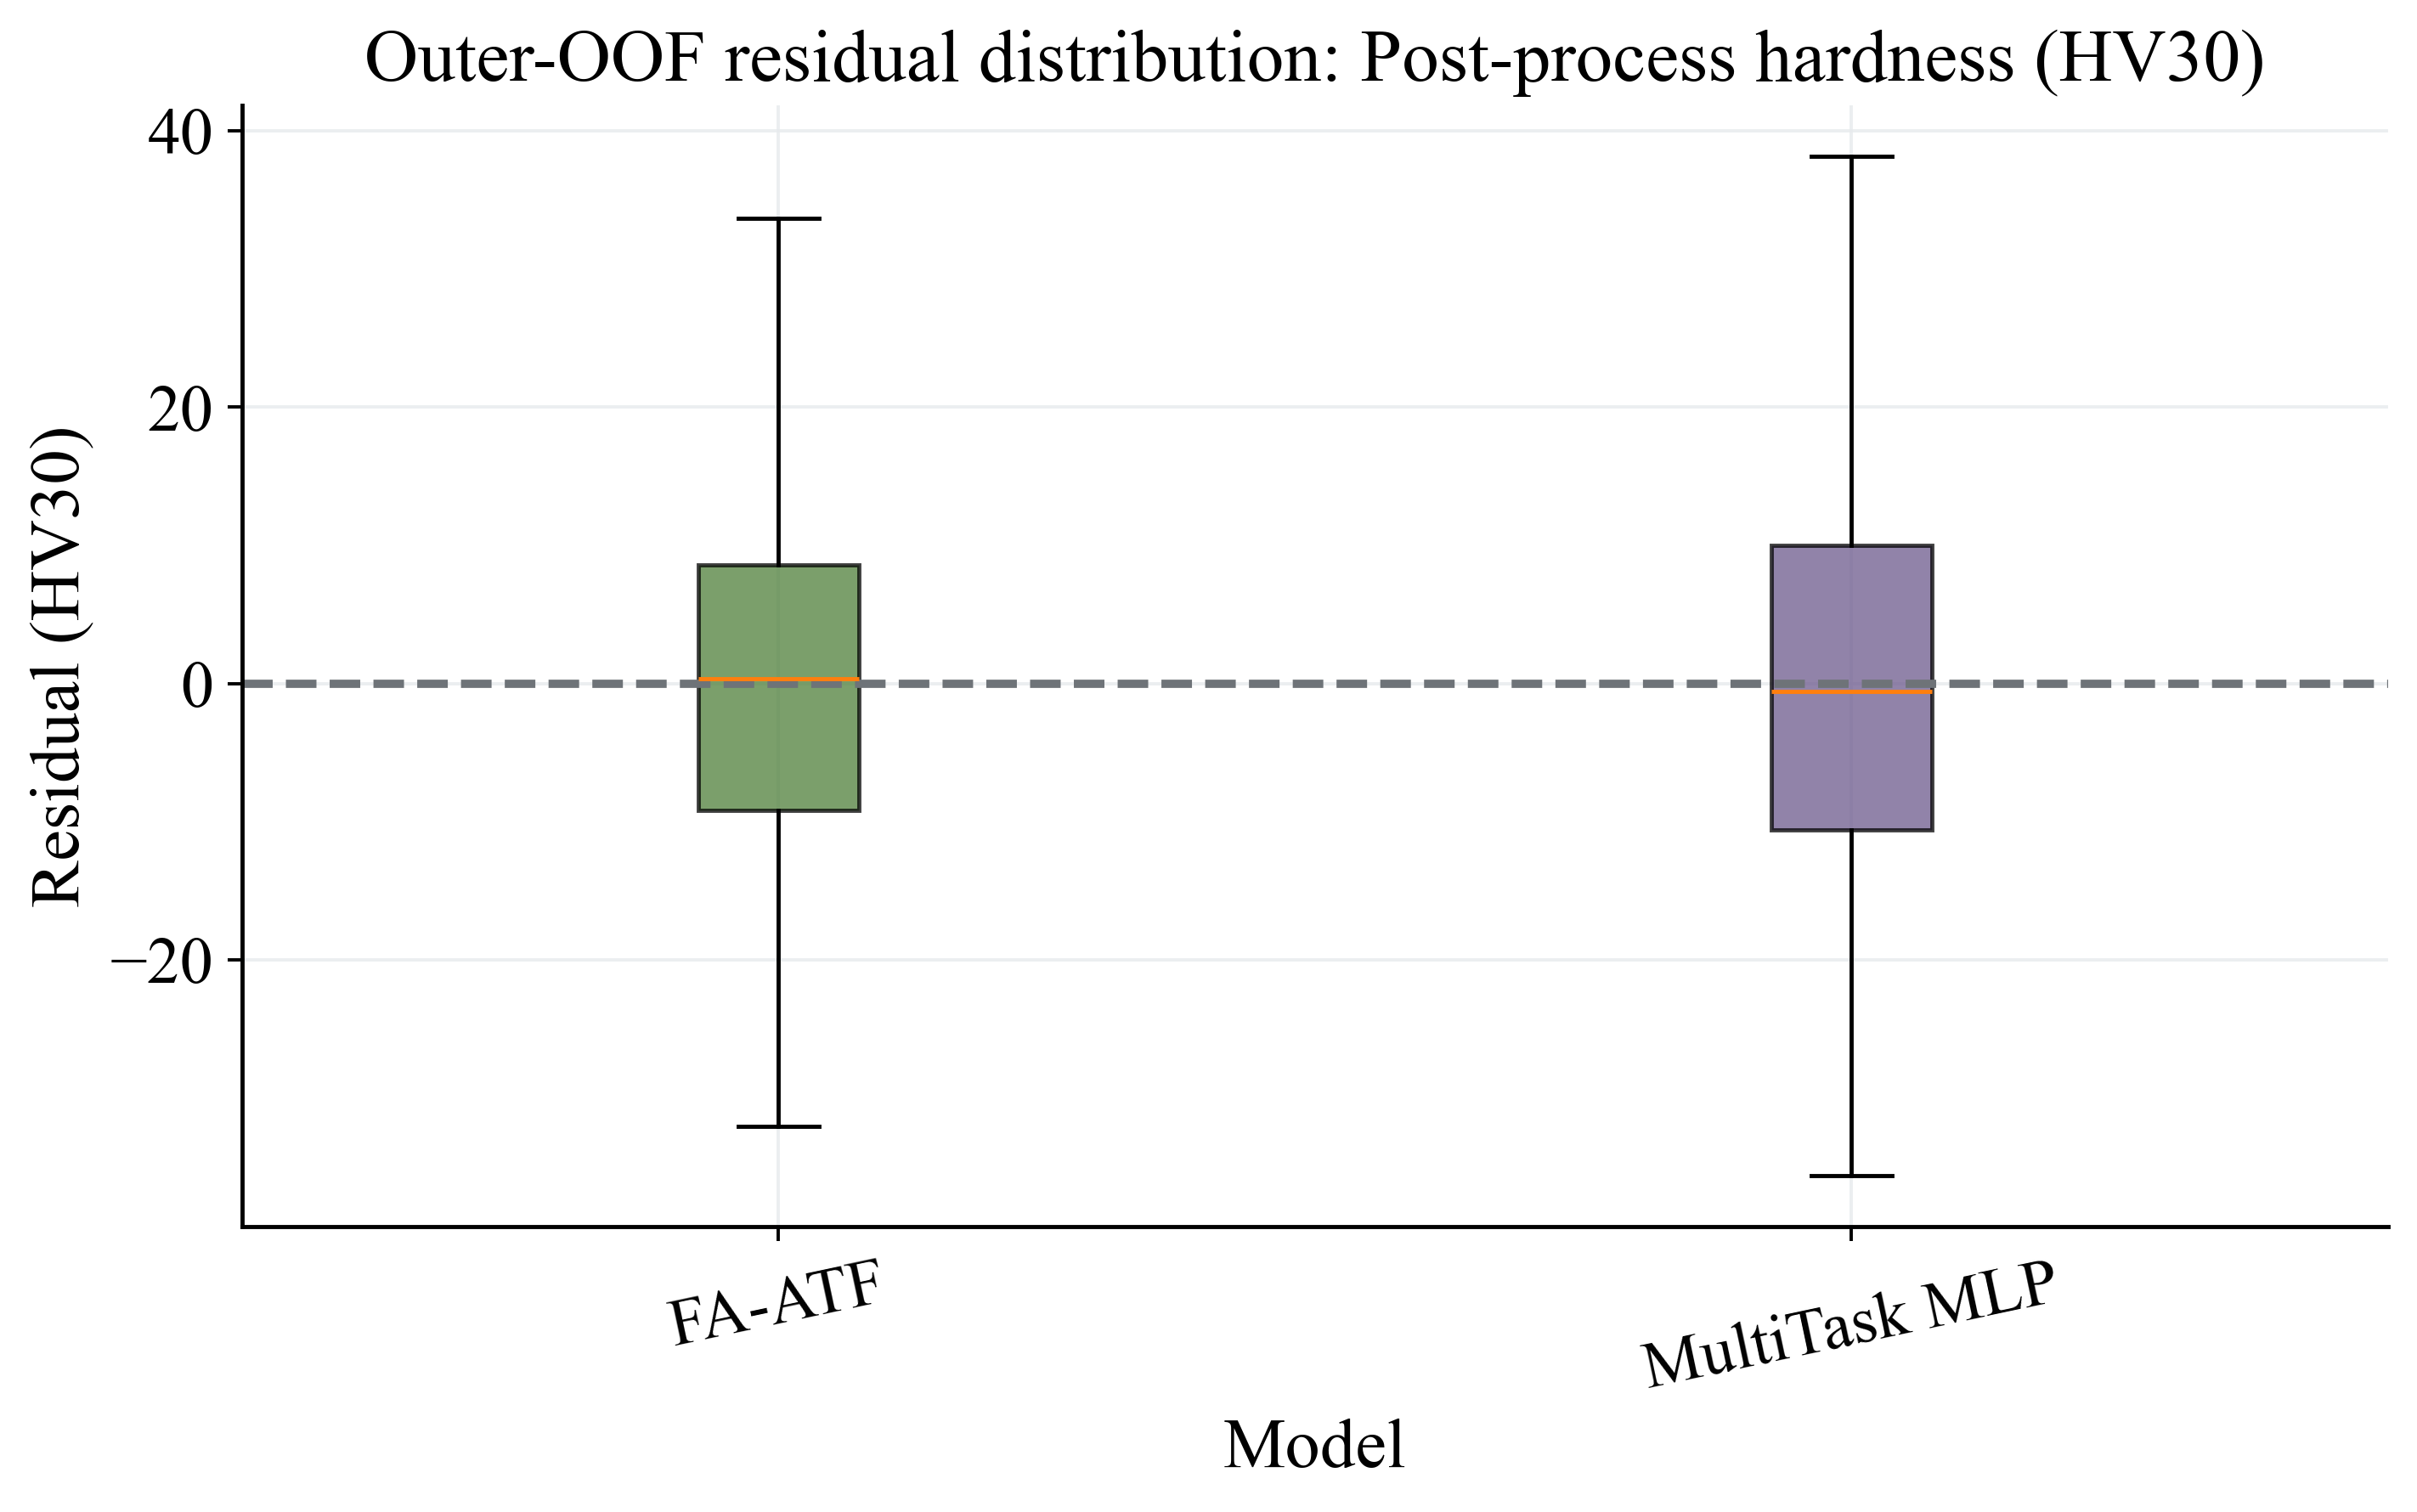

In [19]:
residual_source = all_predictions[
    all_predictions.model.isin(focal_models)
][["sample_id", "model", "target", "y_true", "y_pred"]].copy()
residual_source["residual"] = residual_source.y_true - residual_source.y_pred
for target in TARGETS:
    target_slug = "ra" if target == TARGETS[0] else "hv30"
    part = residual_source[residual_source.target.eq(target)]
    values = [part[part.model.eq(model)].residual for model in focal_models]
    fig, axis = plt.subplots(figsize=(8.8, 5.8))
    boxes = axis.boxplot(values, labels=focal_models, patch_artist=True, showfliers=True)
    for patch, color in zip(boxes["boxes"], [PALETTE["green"], PALETTE["purple"], PALETTE["blue"]]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    axis.axhline(0.0, color=PALETTE["gray"], linestyle="--")
    axis.set_title(f"Outer-OOF residual distribution: {TARGET_LABELS[target]}")
    axis.set_xlabel("Model")
    axis.set_ylabel("Residual (µm)" if target == TARGETS[0] else "Residual (HV30)")
    axis.tick_params(axis="x", rotation=12)
    fig.subplots_adjust(left=0.16, right=0.98, top=0.88, bottom=0.23)
    save_scientific_figure(fig, f"focal_model_residual_distribution_{target_slug}", part)
    display(fig)
    plt.close(fig)

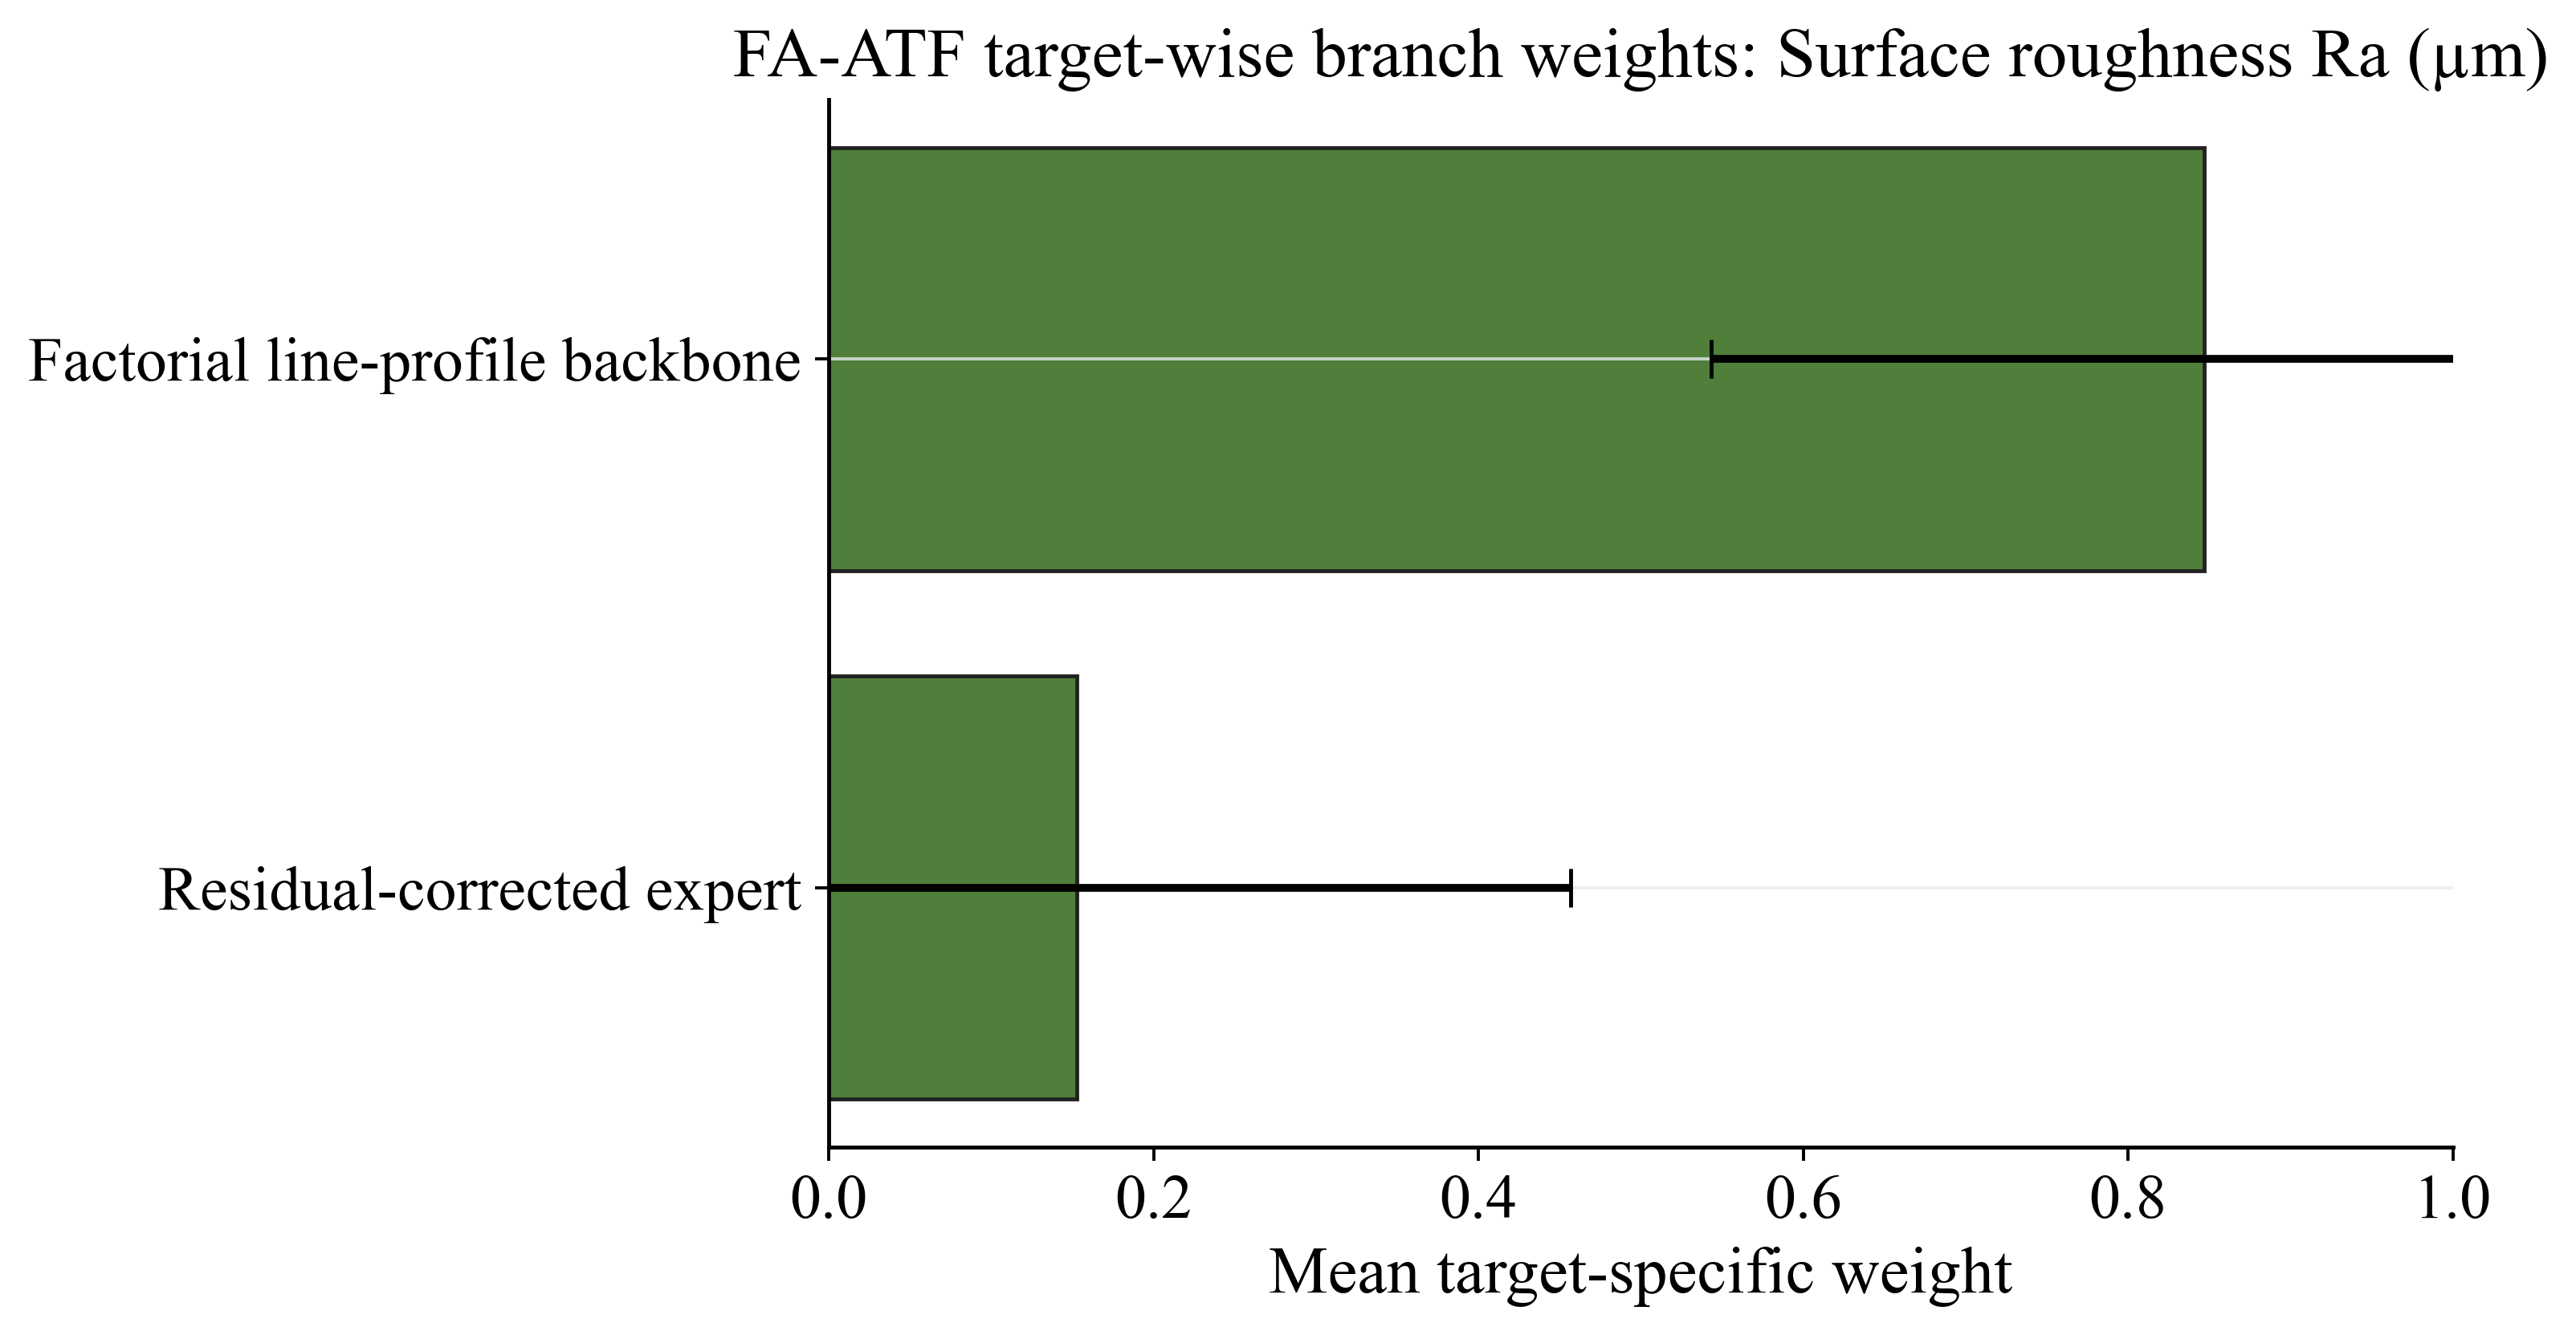

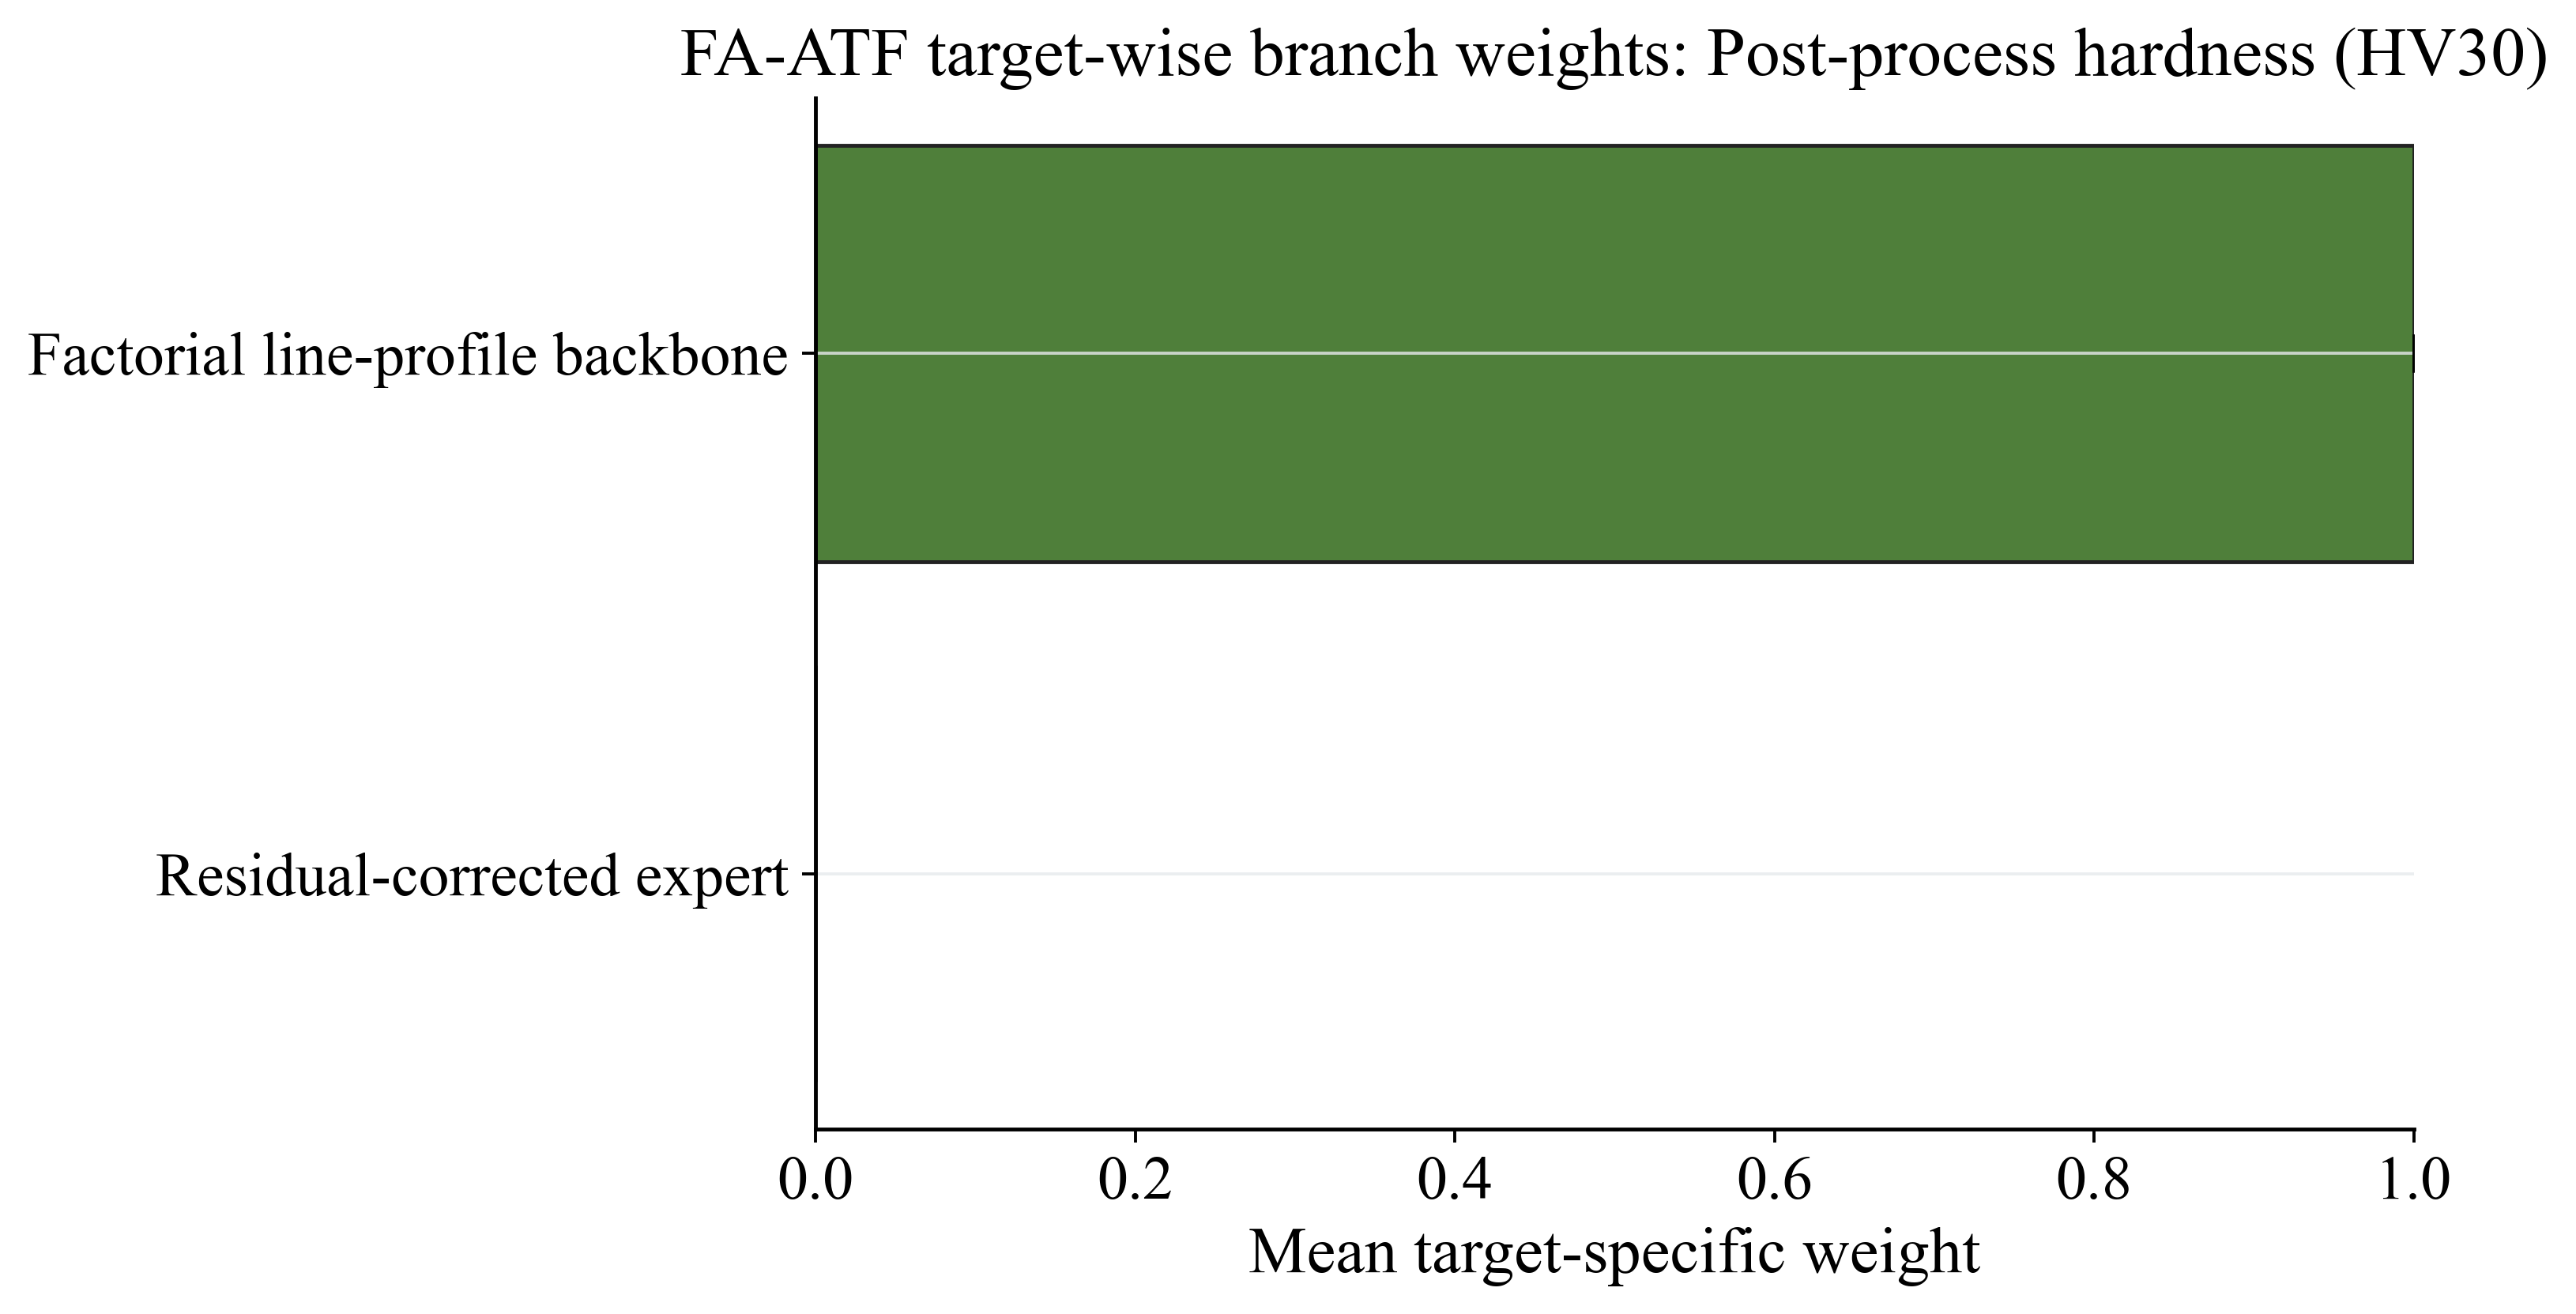

In [20]:
weight_source = weights.copy()
expert_display_names = {
    "Factorial line-profile branch": "Line-profile",
    "Residual neural branch": "Residual MLP",
    "Factorial tensor branch": "Tensor (screened)",
}
for target in TARGETS:
    target_slug = "ra" if target == TARGETS[0] else "hv30"
    part = weight_source[weight_source.target.eq(target)]
    pivot = part.pivot(index="outer_fold", columns="expert", values="weight")
    mean_weight = pivot.mean().sort_values(ascending=True)
    sd_weight = pivot.std().reindex(mean_weight.index).fillna(0.0)
    positions = np.arange(len(mean_weight))
    fig, axis = plt.subplots(figsize=(8.5, 5.4))
    axis.barh(positions, mean_weight.values, xerr=sd_weight.values, capsize=5,
              color=PALETTE["green"], edgecolor=PALETTE["black"])
    axis.set_yticks(positions, labels=[expert_display_names.get(name, name) for name in mean_weight.index])
    axis.set_title(f"FA-ATF target-wise branch weights: {TARGET_LABELS[target]}")
    axis.set_xlabel("Mean target-specific weight")
    axis.set_ylabel("")
    axis.set_xlim(0, 1)
    axis.grid(axis="x")
    fig.subplots_adjust(left=0.30, right=0.98, top=0.88, bottom=0.19)
    save_scientific_figure(fig, f"fa_atf_targetwise_branch_weights_{target_slug}", part)
    display(fig)
    plt.close(fig)

## 13. Compare accuracy and measured inference latency

FA-ATF inference latency is measured end-to-end from the reconstructed frozen outer-fold bundles.
The exact current-run mean across the nine held-out outer-fold prediction paths is computed from the
saved timing artifact and reported in the table below; it is a reproducible runtime measurement on the current hardware, not a deployment benchmark.

In [21]:
baseline_timing = pd.read_csv(METRIC_DIR / "baseline_timing_complexity_summary.csv")
modern_timing = pd.read_csv(METRIC_DIR / "modern_timing_complexity_summary.csv")
fa_atf_timing = pd.read_csv(METRIC_DIR / "fa_atf_timing.csv")
measured_latency = pd.concat([
    baseline_timing[["model", "mean_inference_ms_per_sample"]],
    modern_timing[["model", "mean_inference_ms_per_sample"]],
    pd.DataFrame([{
        "model": "FA-ATF",
        "mean_inference_ms_per_sample": fa_atf_timing.inference_ms_per_sample.mean(),
    }]),
], ignore_index=True)

accuracy_latency = ranking[["rank", "model", "model_family", "mean_NRMSE", "mean_NRMSE_CI_low", "mean_NRMSE_CI_high"]].merge(
    measured_latency, on="model", how="left"
)
accuracy_latency["latency_measurement_status"] = np.select(
    [
        accuracy_latency.model.eq("FA-ATF") & accuracy_latency.mean_inference_ms_per_sample.notna(),
        accuracy_latency.mean_inference_ms_per_sample.notna(),
    ],
    [
        "Measured end-to-end from reconstructed outer-fold bundles",
        "Measured on held-out outer-fold prediction calls",
    ],
    default="Not measured; no latency claim",
)
accuracy_latency.to_csv(METRIC_DIR / "accuracy_latency_comparison.csv", index=False)
display_grouped_table(accuracy_latency.round(6), "Accuracy–latency comparison")


**Accuracy–latency comparison — model_family=Proposed — Predictive performance**

model,model_family,rank,mean_NRMSE,mean_NRMSE_CI_low,mean_NRMSE_CI_high
FA-ATF,Proposed,1,0.377289,0.275048,0.474027


**Accuracy–latency comparison — model_family=Proposed — Uncertainty and statistical evidence**

model,model_family,rank,mean_inference_ms_per_sample
FA-ATF,Proposed,1,0.681285


**Accuracy–latency comparison — model_family=Proposed — Computational efficiency**

model,model_family,rank,latency_measurement_status
FA-ATF,Proposed,1,Measured end-to-end from reconstructed outer-fold bundles


... (14 outputs left out)

**Accuracy–latency comparison — model_family=Modern classical — Uncertainty and statistical evidence**

model,model_family,rank,mean_inference_ms_per_sample
CatBoost,Modern classical,4,0.094471
LightGBM,Modern classical,6,0.103214
XGBoost,Modern classical,7,0.142750
GaussianProcess,Modern classical,16,0.106131


**Accuracy–latency comparison — model_family=Modern classical — Computational efficiency**

model,model_family,rank,latency_measurement_status
CatBoost,Modern classical,4,Measured on held-out outer-fold prediction calls
LightGBM,Modern classical,6,Measured on held-out outer-fold prediction calls
XGBoost,Modern classical,7,Measured on held-out outer-fold prediction calls
GaussianProcess,Modern classical,16,Measured on held-out outer-fold prediction calls


## 14. Explain FA-ATF by branch-output permutation

This global component analysis permutes one expert's outer-fold predictions at a time while holding
the frozen fold-specific fusion weights and all other expert outputs fixed. The reported change in
target-wise NRMSE measures dependence on each branch; it does not reuse target labels for fitting.

**Branch-output permutation dependence — Complete table**

target,expert,mean_delta_NRMSE,CI_low,CI_high,permutations
surface_roughness_Ra_um,Factorial line-profile backbone,0.528240,0.363640,0.676240,300
surface_roughness_Ra_um,Residual-corrected expert,0.148810,0.066000,0.216740,300
post_process_hardness_HV30,Factorial line-profile backbone,1.012260,0.859600,1.156740,300
post_process_hardness_HV30,Residual-corrected expert,0.000000,0.000000,0.000000,300


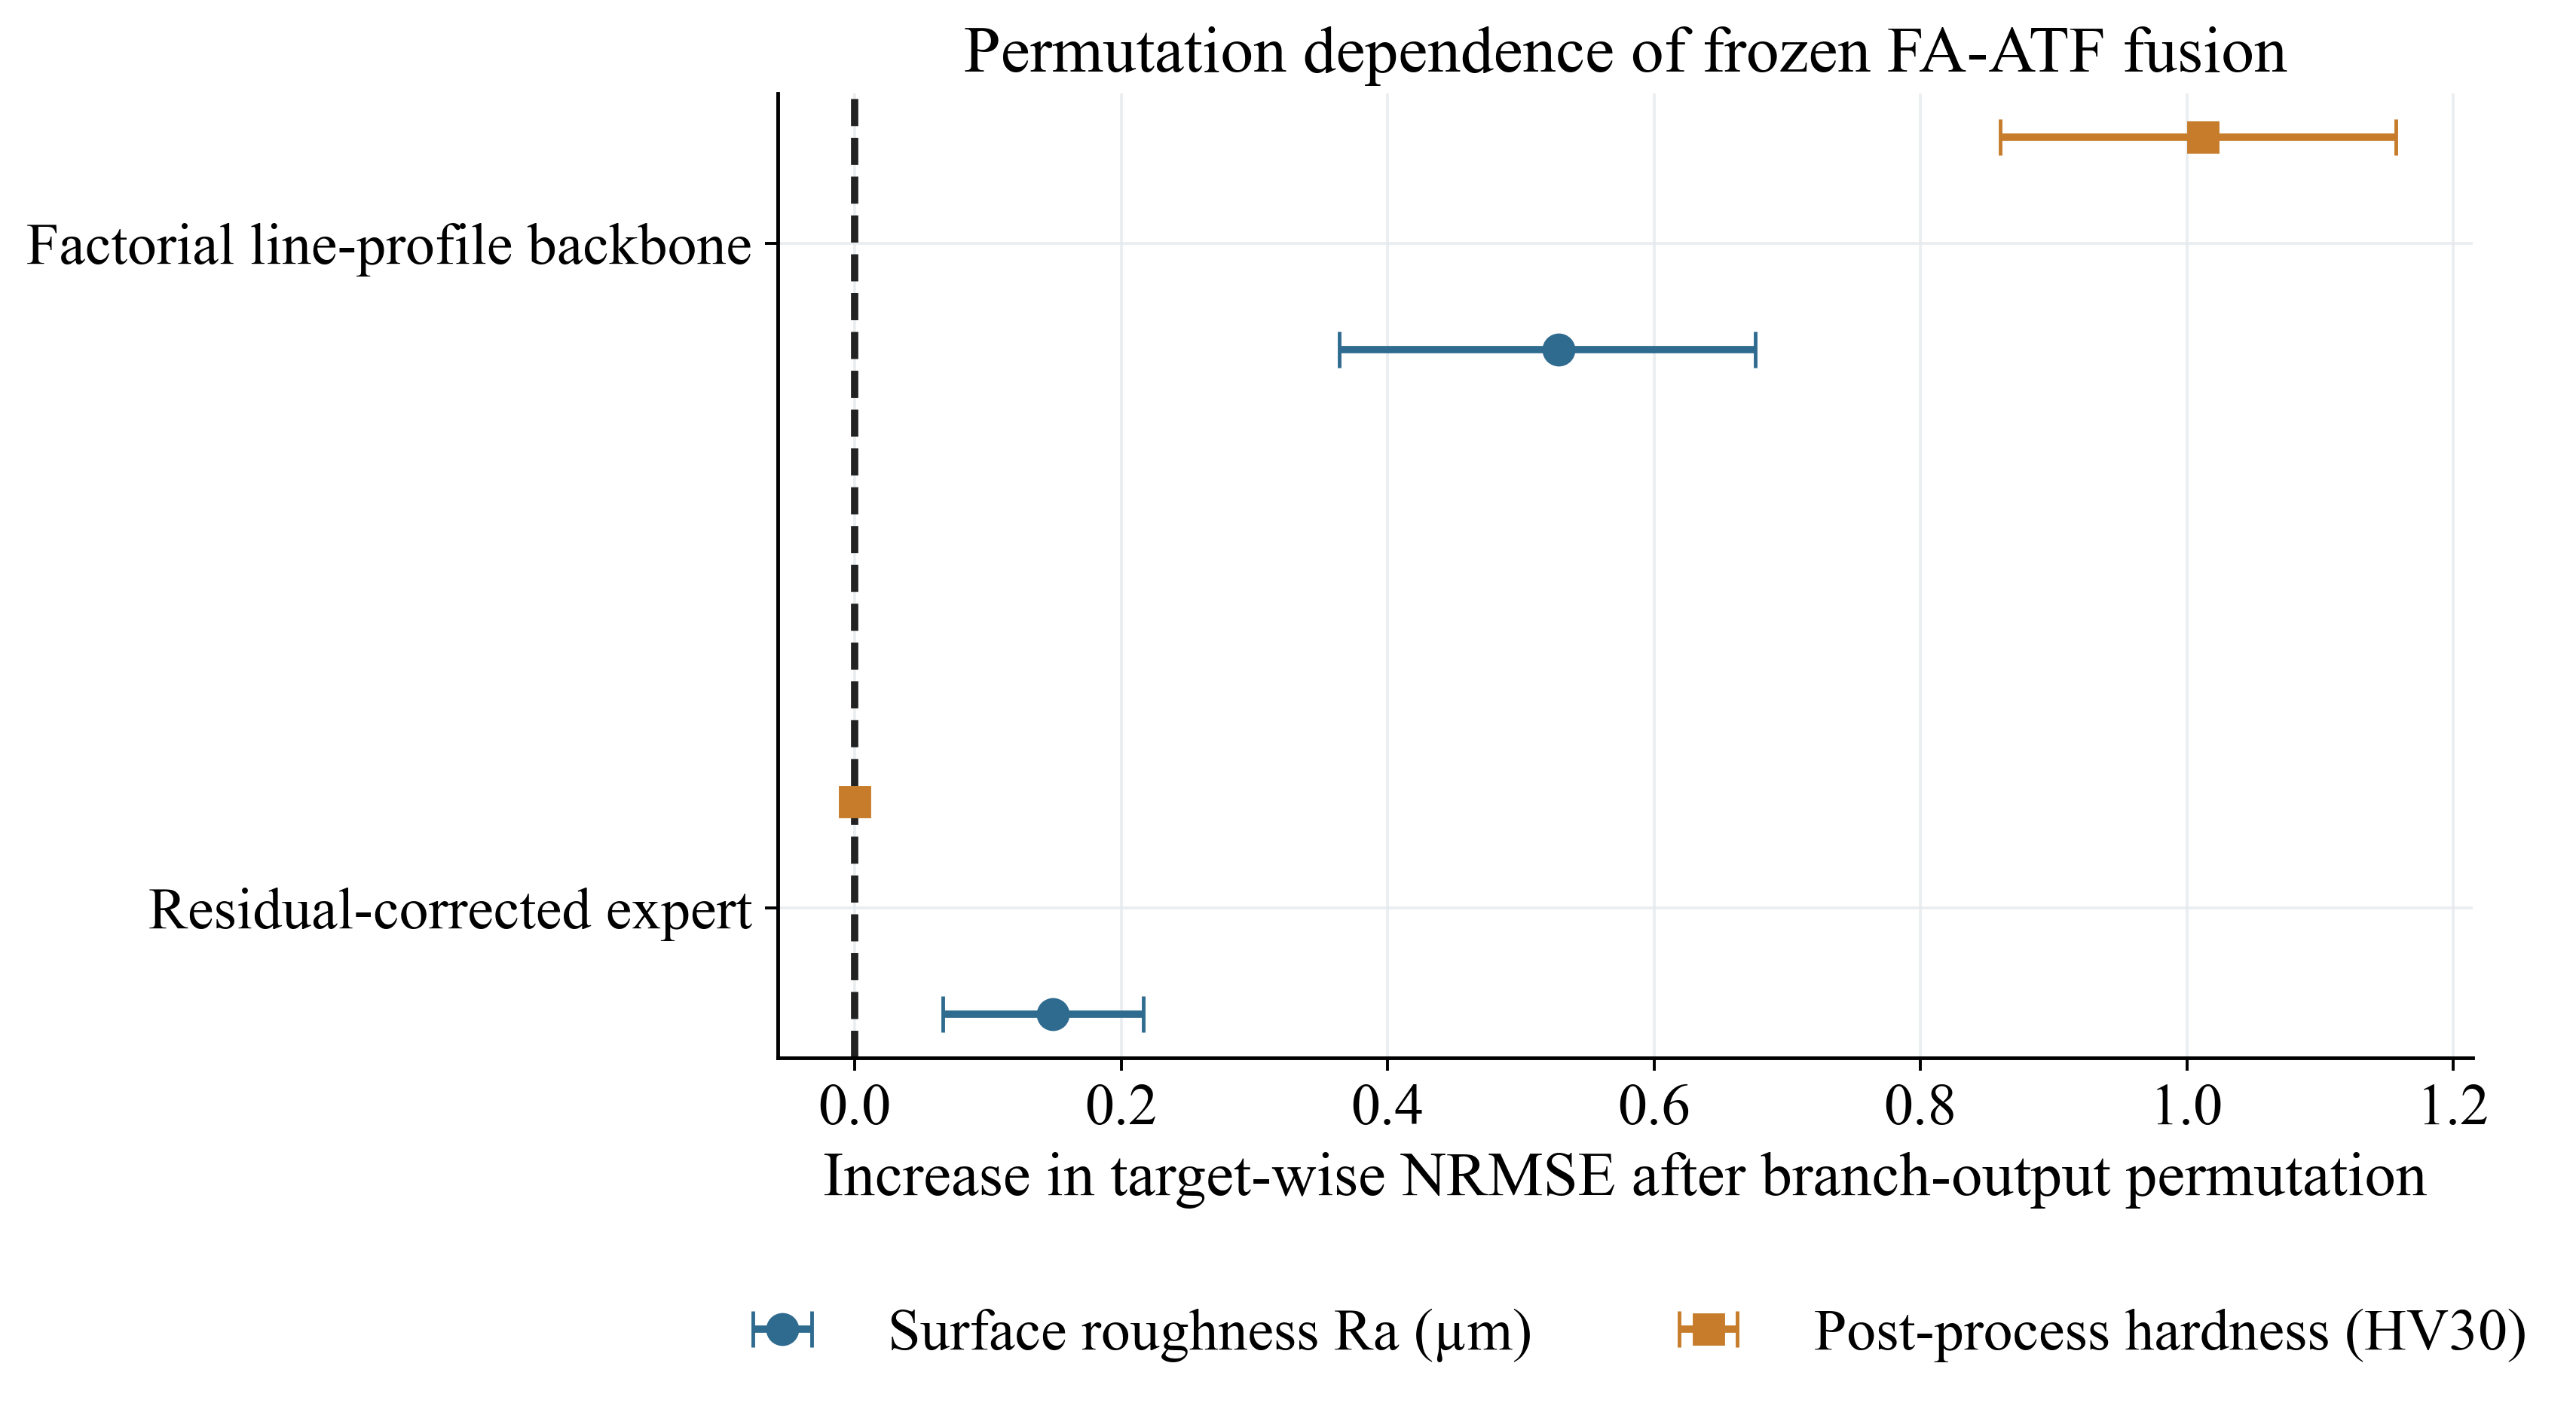

In [22]:
component_names = sorted(expert_outer.expert.unique())
rng = np.random.default_rng(SEED + 61)
permutation_rows = []

for target in TARGETS:
    target_base = proposed[proposed.target.eq(target)].set_index("sample_id").sort_index()
    base_prediction = target_base.y_pred.copy()
    base_nrmse = np.sqrt(mean_squared_error(target_base.y_true, base_prediction)) / TARGET_SCALES[target]
    for expert in component_names:
        delta_values = []
        for repeat in range(300):
            permuted_prediction = base_prediction.copy()
            for outer_fold in sorted(data.outer_fold.unique()):
                branch = expert_outer[
                    expert_outer.target.eq(target)
                    & expert_outer.outer_fold.eq(outer_fold)
                    & expert_outer.expert.eq(expert)
                ].set_index("sample_id").sort_index()
                if branch.empty:
                    continue
                weight_part = weights[
                    weights.target.eq(target)
                    & weights.outer_fold.eq(outer_fold)
                    & weights.expert.eq(expert)
                ]
                if weight_part.empty:
                    continue
                branch_weight = float(weight_part.iloc[0].weight)
                observed = branch.y_pred.to_numpy()
                shuffled = observed[rng.permutation(len(observed))]
                permuted_prediction.loc[branch.index] += branch_weight * (shuffled - observed)
            permuted_nrmse = (
                np.sqrt(mean_squared_error(target_base.y_true, permuted_prediction)) / TARGET_SCALES[target]
            )
            delta_values.append(permuted_nrmse - base_nrmse)
        permutation_rows.append({
            "target": target, "expert": expert,
            "mean_delta_NRMSE": float(np.mean(delta_values)),
            "CI_low": float(np.quantile(delta_values, 0.025)),
            "CI_high": float(np.quantile(delta_values, 0.975)),
            "permutations": len(delta_values),
        })

component_permutation = pd.DataFrame(permutation_rows)
component_permutation.to_csv(STATISTICS_DIR / "fa_atf_component_permutation_importance.csv", index=False)
display_grouped_table(component_permutation.round(5), "Branch-output permutation dependence")





ordered_experts = (
    component_permutation.groupby("expert").mean_delta_NRMSE.mean().sort_values().index.tolist()
)
fig, axis = plt.subplots(figsize=(10.2, 6.2))
positions = np.arange(len(ordered_experts))
for offset, target, color, marker in [
    (-0.16, TARGETS[0], PALETTE["blue"], "o"),
    (0.16, TARGETS[1], PALETTE["orange"], "s"),
]:
    part = component_permutation[component_permutation.target.eq(target)].set_index("expert").reindex(ordered_experts)
    mean_value = part.mean_delta_NRMSE.to_numpy()
    x_error = np.vstack([mean_value - part.CI_low.to_numpy(), part.CI_high.to_numpy() - mean_value])
    axis.errorbar(mean_value, positions + offset, xerr=x_error, fmt=marker, color=color,
                  capsize=5, markersize=8, label=TARGET_LABELS[target])
axis.axvline(0, color=PALETTE["black"], linestyle="--")
axis.set_yticks(positions, ordered_experts)
axis.set_xlabel("Increase in target-wise NRMSE after branch-output permutation")
axis.set_ylabel("")
axis.set_title("Permutation dependence of frozen FA-ATF fusion")
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.37), frameon=False, ncol=2)
fig.subplots_adjust(left=0.35, right=0.98, top=0.88, bottom=0.29)
save_scientific_figure(fig, "fa_atf_component_permutation_importance", component_permutation)
display(fig)
plt.close(fig)


## 15. Estimate standardized model-implied marginal factorial contrasts

For factor \(x\) and target \(t\), define the model-implied marginal factorial contrast
\[
C_{x,t}=\frac{\bar{\hat y}_t(x_{\mathrm{high}})-\bar{\hat y}_t(x_{\mathrm{low}})}{x_{\mathrm{high}}-x_{\mathrm{low}}}\frac{\operatorname{IQR}(x)}{\operatorname{IQR}(y_t)}.
\]
The balanced full-factorial design supports stable marginal averaging over the other observed factors. The contrast is a descriptive summary of frozen OOF predictions inside the observed levels; it is noncausal and does not support extrapolation.

**Model-implied marginal factorial contrasts — Predictors and design variables**

target,feature,low_level,high_level,standardized_marginal_factorial_contrast
surface_roughness_Ra_um,HV_init_HV30,400.000000,600.000000,-0.015140
surface_roughness_Ra_um,feed_mm_rev,0.050000,0.500000,1.150900
surface_roughness_Ra_um,cutting_speed_m_min,100.000000,250.000000,-0.200390
surface_roughness_Ra_um,depth_of_cut_mm,0.050000,0.500000,0.014980
post_process_hardness_HV30,HV_init_HV30,400.000000,600.000000,1.099260
post_process_hardness_HV30,feed_mm_rev,0.050000,0.500000,0.181120
post_process_hardness_HV30,cutting_speed_m_min,100.000000,250.000000,-0.098860
post_process_hardness_HV30,depth_of_cut_mm,0.050000,0.500000,-0.052790


**Model-implied marginal factorial contrasts — Uncertainty and statistical evidence**

target,feature,mean_prediction_low,mean_prediction_high
surface_roughness_Ra_um,HV_init_HV30,1.036450,1.014080
surface_roughness_Ra_um,feed_mm_rev,0.249200,1.950230
surface_roughness_Ra_um,cutting_speed_m_min,1.132570,0.836390
surface_roughness_Ra_um,depth_of_cut_mm,1.001990,1.024130
post_process_hardness_HV30,HV_init_HV30,500.228280,595.863820
post_process_hardness_HV30,feed_mm_rev,532.154900,547.912290
post_process_hardness_HV30,cutting_speed_m_min,543.480680,534.879430
post_process_hardness_HV30,depth_of_cut_mm,540.340640,535.748040


**Model-implied marginal factorial contrasts — Additional reported attributes**

target,feature,response_difference,feature_IQR,target_IQR
surface_roughness_Ra_um,HV_init_HV30,-0.022370,200.000000,1.478000
surface_roughness_Ra_um,feed_mm_rev,1.701030,0.450000,1.478000
surface_roughness_Ra_um,cutting_speed_m_min,-0.296180,150.000000,1.478000
surface_roughness_Ra_um,depth_of_cut_mm,0.022140,0.450000,1.478000
post_process_hardness_HV30,HV_init_HV30,95.635540,200.000000,87.000000
post_process_hardness_HV30,feed_mm_rev,15.757380,0.450000,87.000000
post_process_hardness_HV30,cutting_speed_m_min,-8.601250,150.000000,87.000000
post_process_hardness_HV30,depth_of_cut_mm,-4.592590,0.450000,87.000000


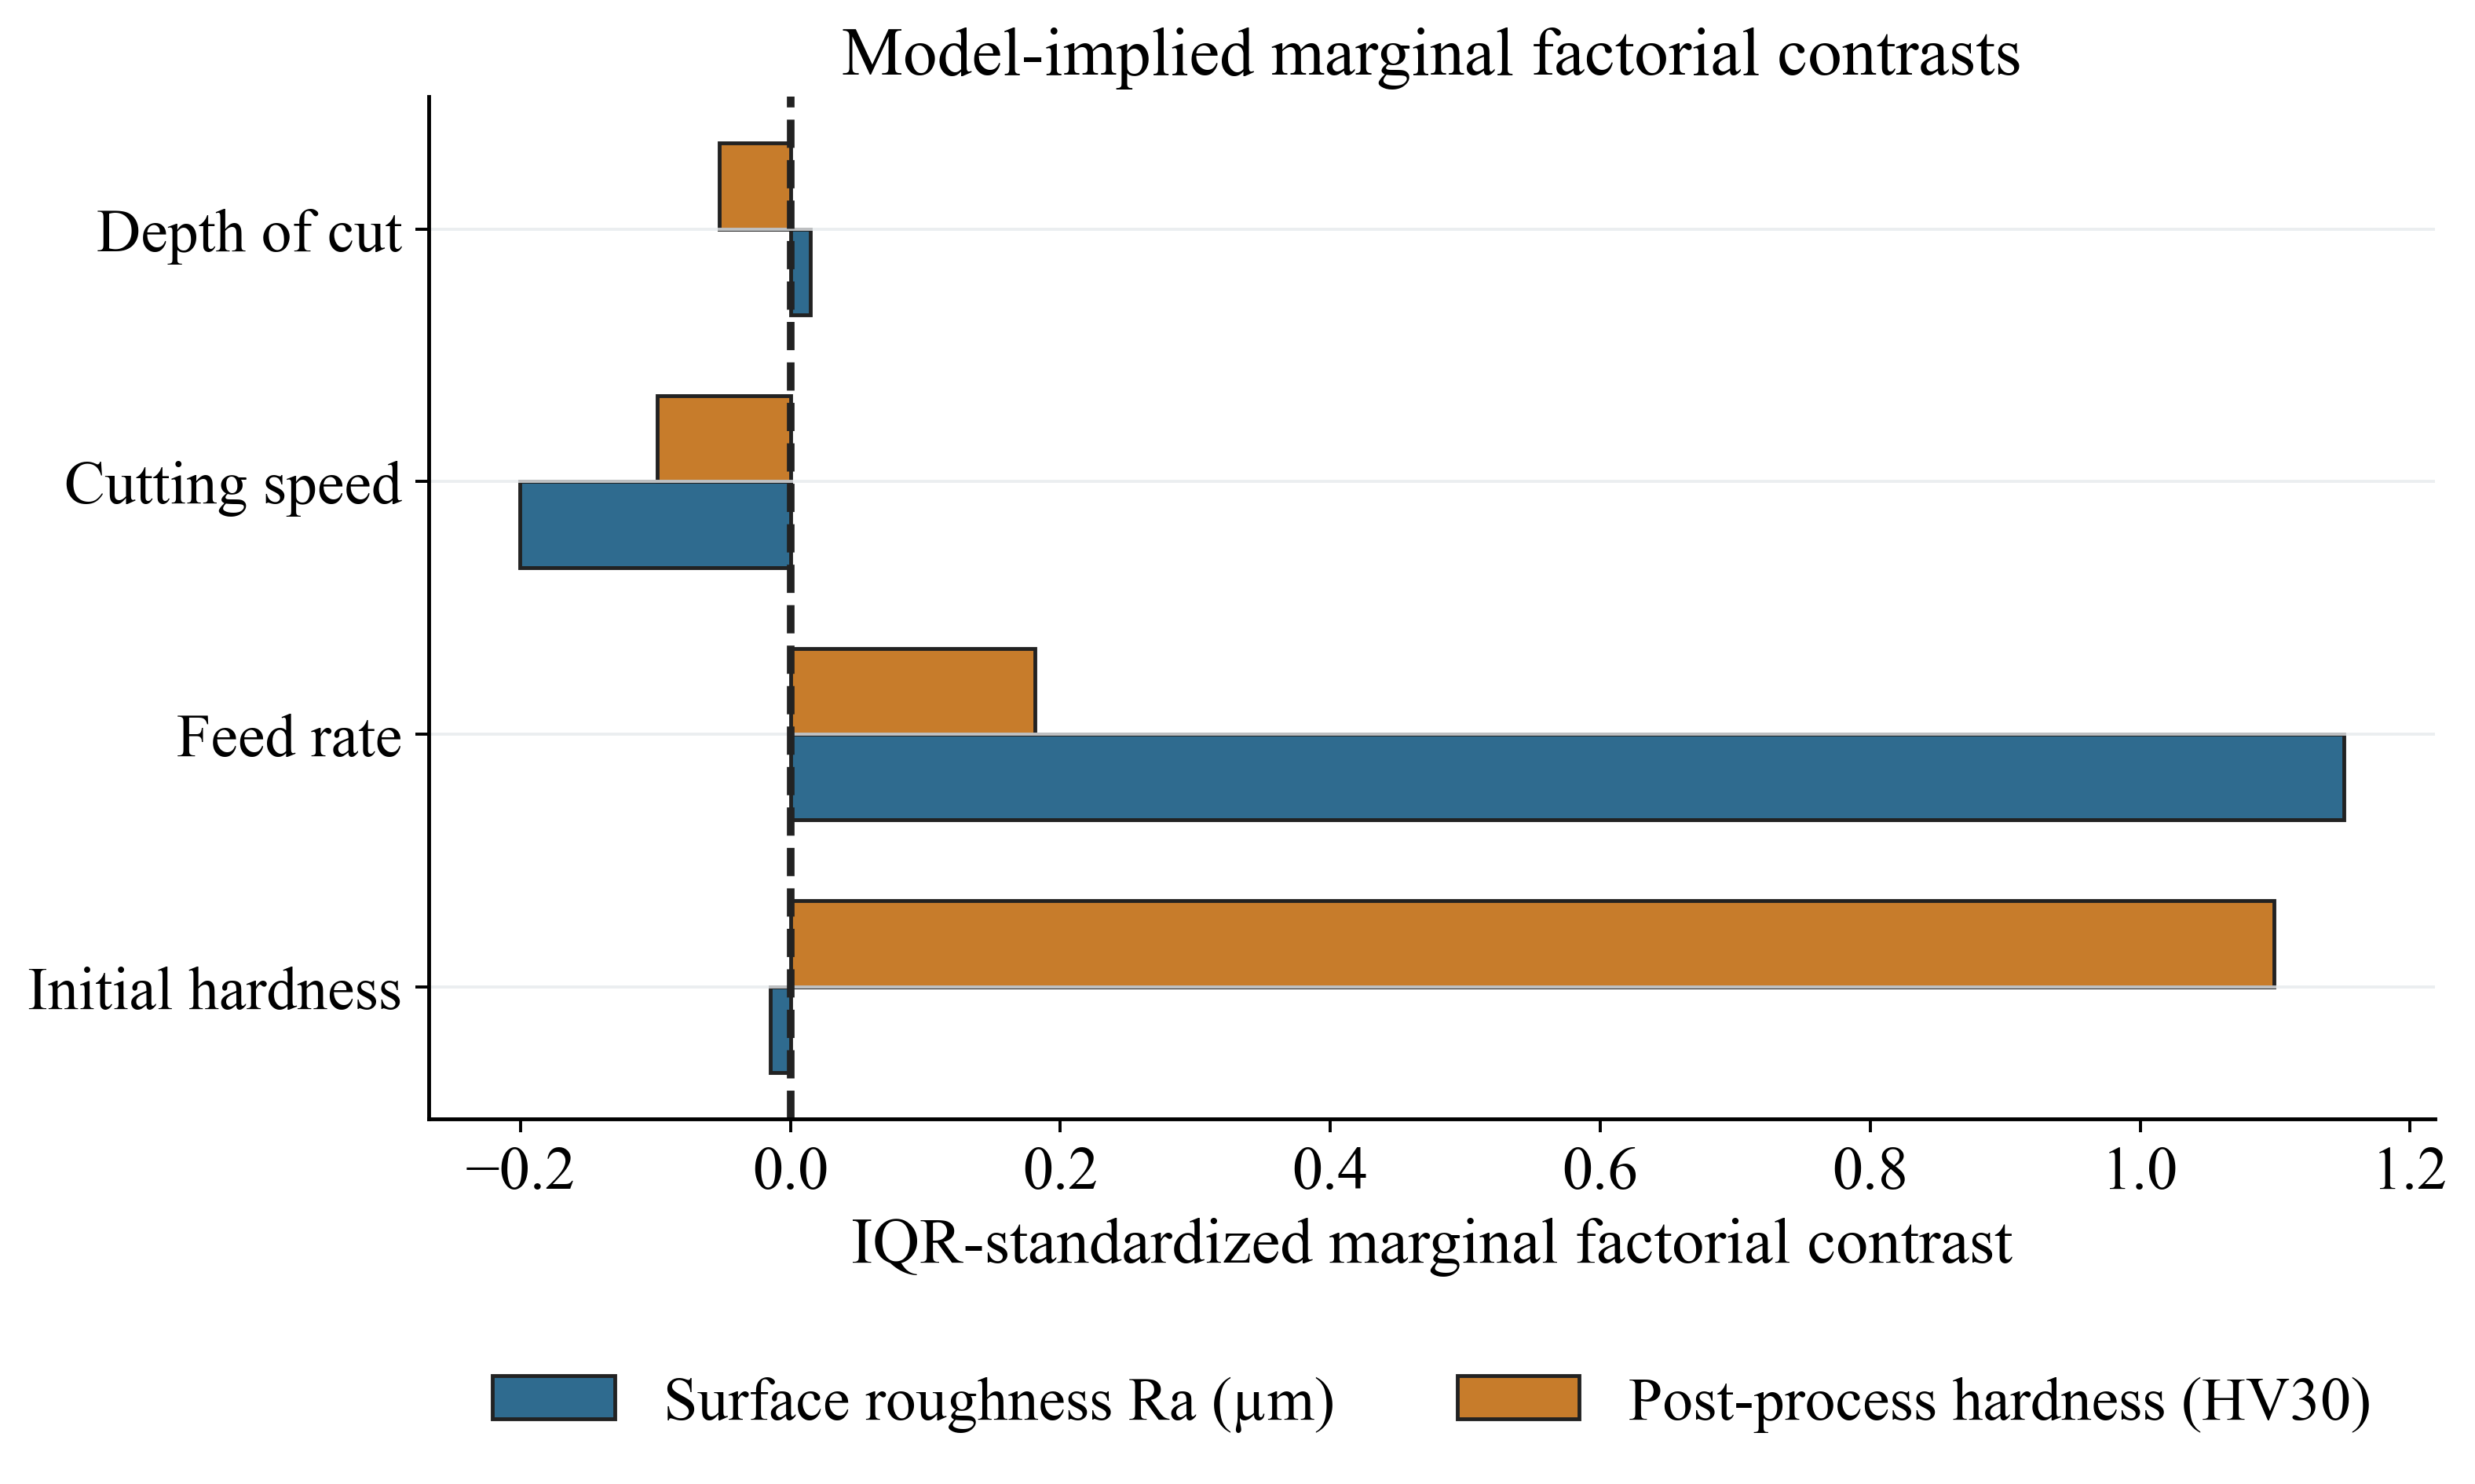

In [23]:
FACTOR_FEATURES = ["HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm"]
FACTOR_LABELS = {
    "HV_init_HV30": "Initial hardness",
    "feed_mm_rev": "Feed rate",
    "cutting_speed_m_min": "Cutting speed",
    "depth_of_cut_mm": "Depth of cut",
}
prediction_design = proposed.merge(data[["sample_id", *FACTOR_FEATURES]], on="sample_id", how="left")
contrast_rows = []
for target in TARGETS:
    target_part = prediction_design[prediction_design.target.eq(target)]
    target_iqr = data[target].quantile(0.75) - data[target].quantile(0.25)
    for feature in FACTOR_FEATURES:
        low, high = target_part[feature].min(), target_part[feature].max()
        low_mean = target_part.loc[target_part[feature].eq(low), "y_pred"].mean()
        high_mean = target_part.loc[target_part[feature].eq(high), "y_pred"].mean()
        feature_iqr = data[feature].quantile(0.75) - data[feature].quantile(0.25)
        physical_slope = (high_mean - low_mean) / (high - low)
        contrast_rows.append({
            "target": target, "feature": feature, "low_level": low, "high_level": high,
            "mean_prediction_low": low_mean, "mean_prediction_high": high_mean,
            "response_difference": high_mean - low_mean,
            "feature_IQR": feature_iqr, "target_IQR": target_iqr,
            "standardized_marginal_factorial_contrast": physical_slope * feature_iqr / target_iqr,
        })

factorial_contrasts = pd.DataFrame(contrast_rows)
factorial_contrasts.to_csv(STATISTICS_DIR / "fa_atf_standardized_marginal_factorial_contrasts.csv", index=False)
display_grouped_table(factorial_contrasts.round(5), "Model-implied marginal factorial contrasts")





contrast_matrix = factorial_contrasts.pivot(
    index="feature", columns="target", values="standardized_marginal_factorial_contrast"
).reindex(index=FACTOR_FEATURES, columns=TARGETS)
positions = np.arange(len(FACTOR_FEATURES))
bar_height = 0.34
fig, axis = plt.subplots(figsize=(10.0, 6.2))
axis.barh(
    positions - bar_height / 2,
    contrast_matrix[TARGETS[0]].to_numpy(),
    height=bar_height,
    color=PALETTE["blue"],
    edgecolor=PALETTE["black"],
    label=TARGET_LABELS[TARGETS[0]],
)
axis.barh(
    positions + bar_height / 2,
    contrast_matrix[TARGETS[1]].to_numpy(),
    height=bar_height,
    color=PALETTE["orange"],
    edgecolor=PALETTE["black"],
    label=TARGET_LABELS[TARGETS[1]],
)
axis.axvline(0.0, color=PALETTE["black"], linestyle="--")
axis.set_yticks(positions, labels=[FACTOR_LABELS[item] for item in FACTOR_FEATURES])
axis.set_xlabel("IQR-standardized marginal factorial contrast")
axis.set_ylabel("")
axis.set_title("Model-implied marginal factorial contrasts")
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.36), ncol=2, frameon=False)
axis.grid(axis="x")
fig.subplots_adjust(left=0.25, bottom=0.28, right=0.98, top=0.88)
save_scientific_figure(fig, "fa_atf_standardized_marginal_factorial_contrasts", factorial_contrasts)
display(fig)
plt.close(fig)


## 16. Restrict the process trade-off to observed OOF predictions

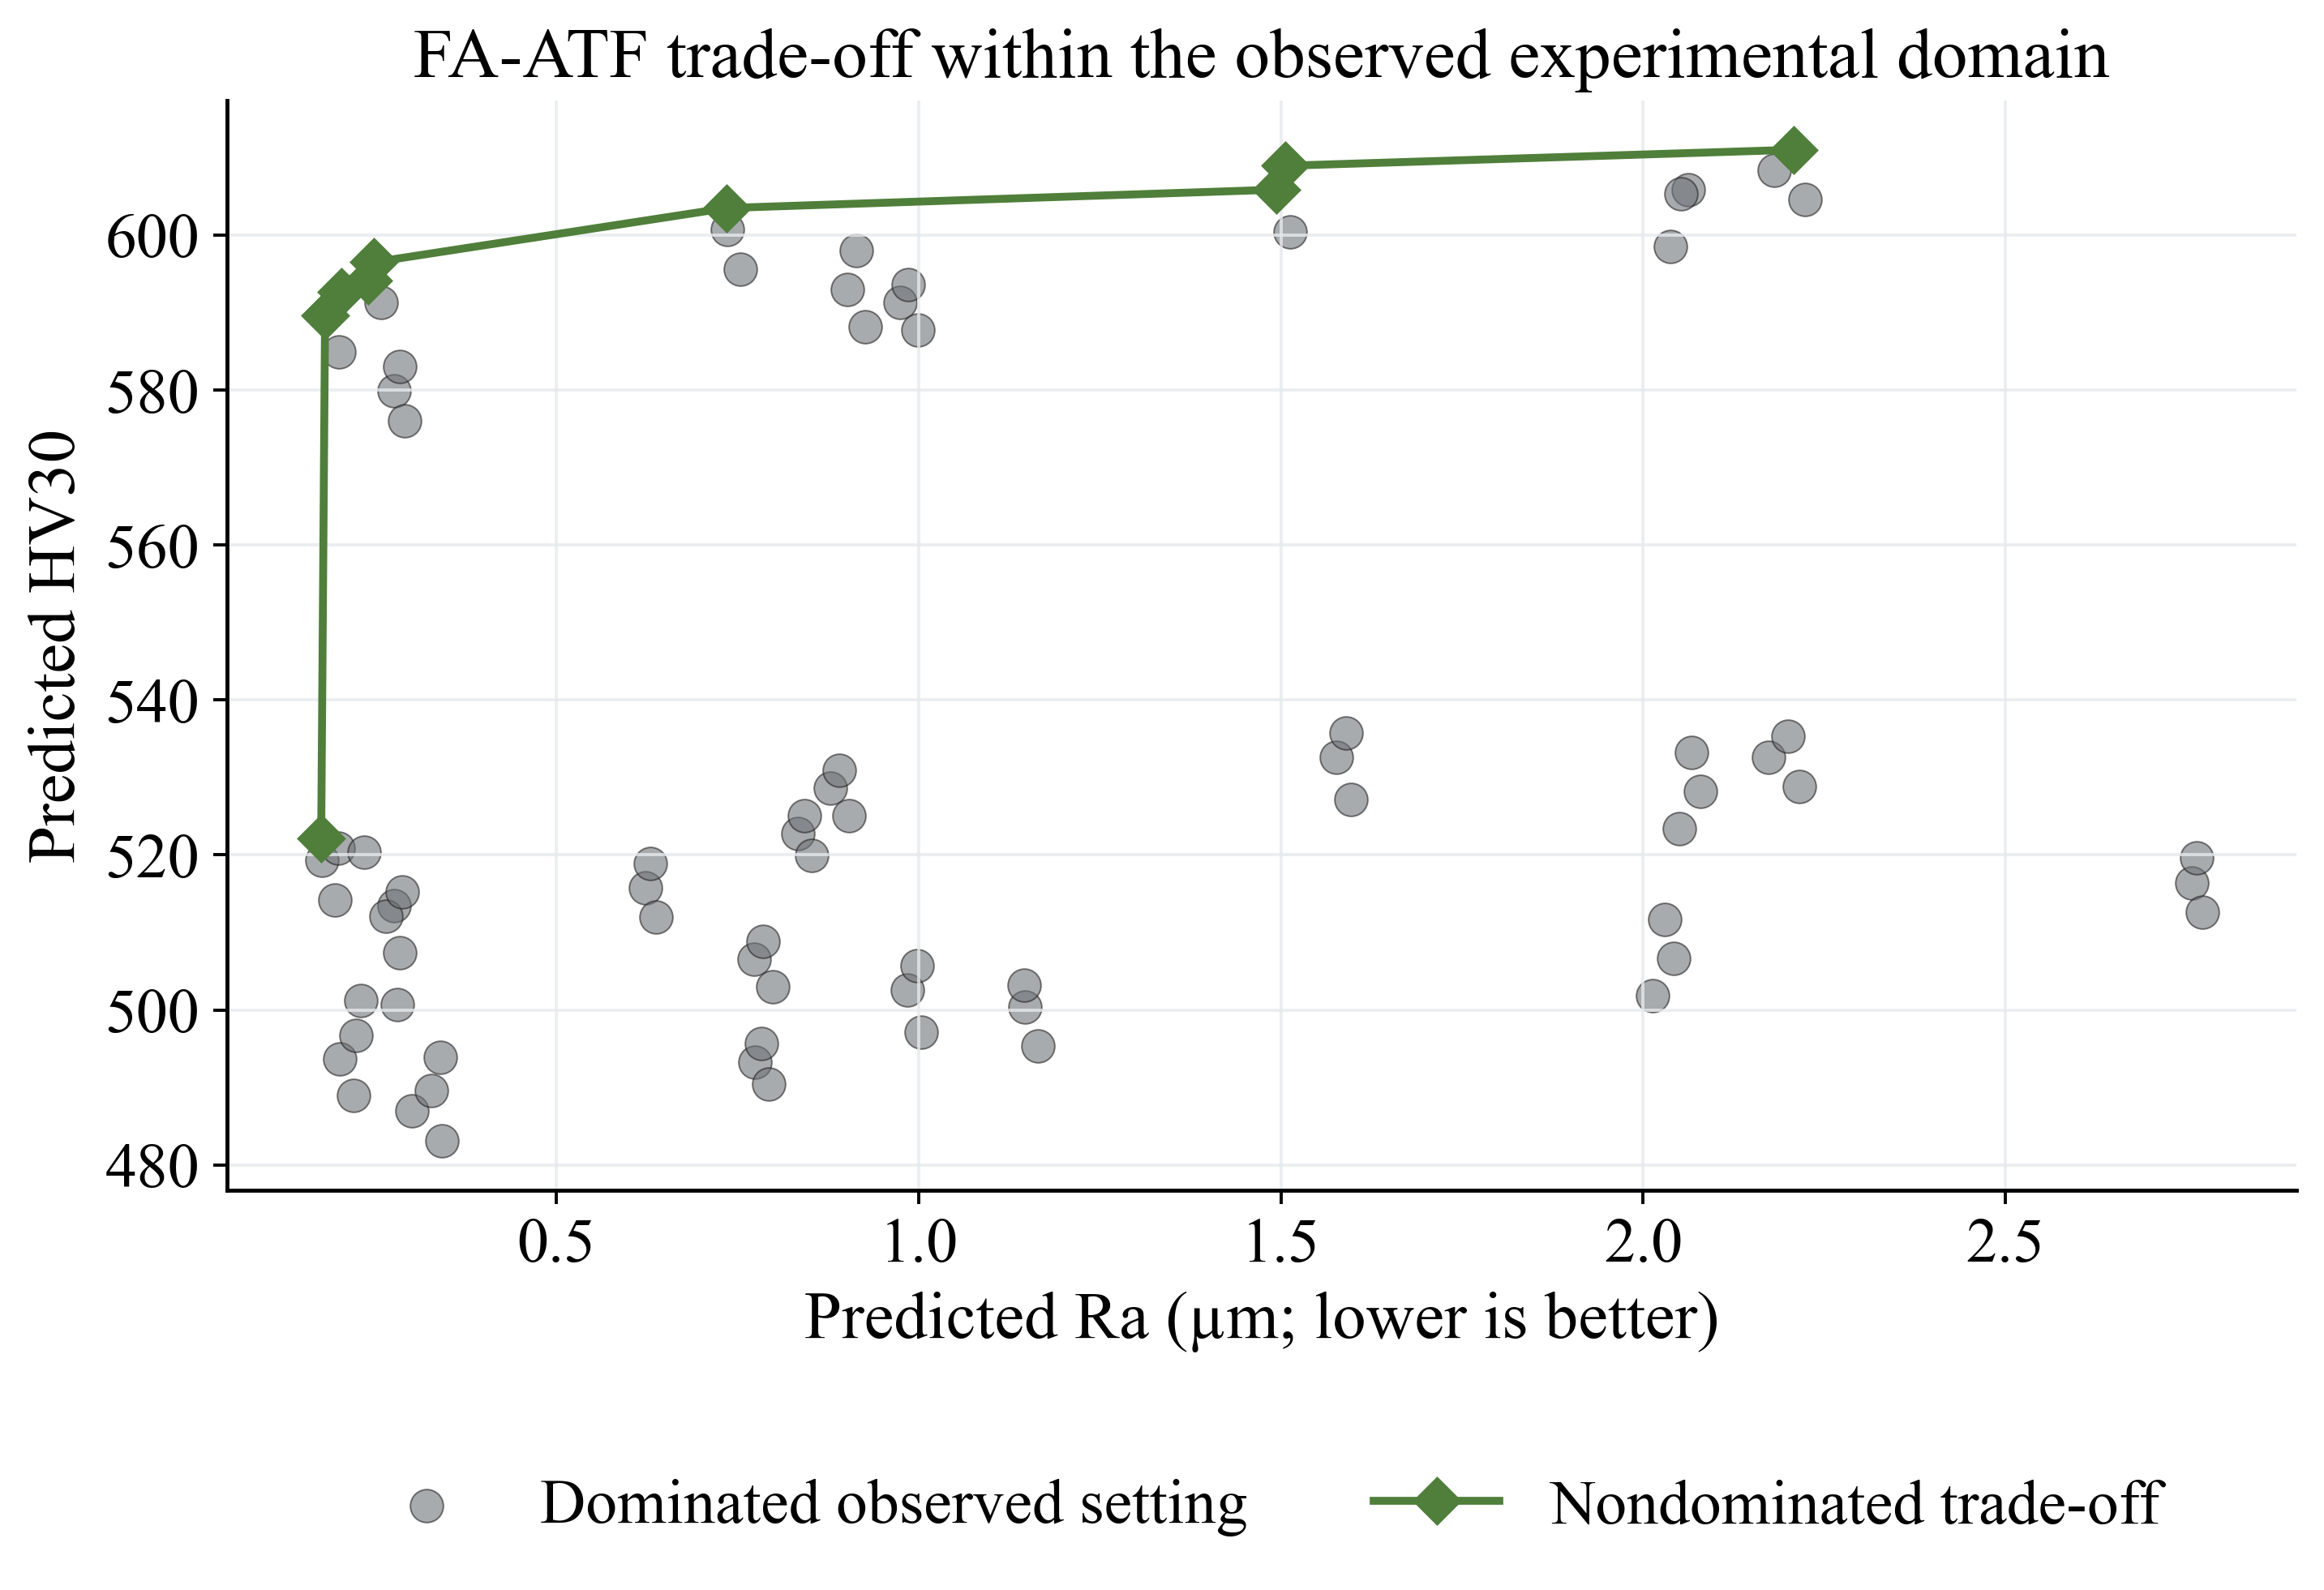

In [24]:
fa_wide = proposed.pivot(index="sample_id", columns="target", values="y_pred").reset_index()
fa_wide = fa_wide.merge(data[["sample_id", "HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm"]], on="sample_id")
ra_values = fa_wide[TARGETS[0]].to_numpy()
hv_values = fa_wide[TARGETS[1]].to_numpy()
nondominated = np.ones(len(fa_wide), dtype=bool)
for index in range(len(fa_wide)):
    dominates = (ra_values <= ra_values[index]) & (hv_values >= hv_values[index]) & ((ra_values < ra_values[index]) | (hv_values > hv_values[index]))
    if np.any(dominates):
        nondominated[index] = False
fa_wide["pareto_status"] = np.where(nondominated, "Nondominated trade-off", "Dominated observed setting")
pareto = fa_wide[nondominated].sort_values(TARGETS[0])
fa_wide.to_csv(METRIC_DIR / "fa_atf_observed_domain_pareto.csv", index=False)

fig, axis = plt.subplots(figsize=(9.0, 6.4))
dominated = fa_wide[~nondominated]
axis.scatter(dominated[TARGETS[0]], dominated[TARGETS[1]], s=70, color=PALETTE["gray"],
             alpha=0.60, edgecolor=PALETTE["black"], linewidth=0.4,
             label="Dominated observed setting")
axis.plot(pareto[TARGETS[0]], pareto[TARGETS[1]], color=PALETTE["green"],
          marker="D", markersize=8, label="Nondominated trade-off")
axis.set_title("FA-ATF trade-off within the observed experimental domain")
axis.set_xlabel("Predicted Ra (µm; lower is better)")
axis.set_ylabel("Predicted HV30")
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.37), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.28, left=0.17, right=0.98, top=0.88)
save_scientific_figure(fig, "fa_atf_observed_domain_pareto", fa_wide)
display(fig)
plt.close(fig)

## 17. Stress-test robustness within the observed factorial domain

A genuinely independent validation set requires newly manufactured and measured specimens.
It cannot be produced by repartitioning these 81 observations. The analyses below therefore
remain internal robustness checks: every prediction is still outer-OOF, every specimen is
absent from its fold-training data, and distance is calculated from that fold's training
factor space only.

In [25]:
from scipy.stats import spearmanr

ROBUSTNESS_FACTORS = [
    "HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm"
]
PROFILE_FACTORS = ["HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min"]
distance_rows = []
combination_checks = []

for outer_fold in sorted(data.outer_fold.unique()):
    fold_train = data.loc[data.outer_fold.ne(outer_fold)].copy()
    fold_test = data.loc[data.outer_fold.eq(outer_fold)].copy()
    train_mean = fold_train[ROBUSTNESS_FACTORS].mean()
    train_scale = fold_train[ROBUSTNESS_FACTORS].std(ddof=0).replace(0.0, 1.0)
    train_scaled = ((fold_train[ROBUSTNESS_FACTORS] - train_mean) / train_scale).to_numpy()
    test_scaled = ((fold_test[ROBUSTNESS_FACTORS] - train_mean) / train_scale).to_numpy()
    nearest_distance = np.sqrt(
        ((test_scaled[:, None, :] - train_scaled[None, :, :]) ** 2).sum(axis=2)
    ).min(axis=1)

    training_profiles = set(map(tuple, fold_train[PROFILE_FACTORS].to_numpy()))
    for sample_id, profile, distance in zip(
        fold_test.sample_id,
        map(tuple, fold_test[PROFILE_FACTORS].to_numpy()),
        nearest_distance,
    ):
        distance_rows.append({
            "sample_id": int(sample_id), "outer_fold": int(outer_fold),
            "nearest_training_distance": float(distance),
        })
        combination_checks.append({
            "sample_id": int(sample_id), "outer_fold": int(outer_fold),
            "profile_combination_absent_from_training": profile not in training_profiles,
        })

domain_distance = pd.DataFrame(distance_rows)
domain_distance["distance_band"] = pd.qcut(
    domain_distance.nearest_training_distance,
    q=3,
    labels=["Near", "Intermediate", "Far"],
)
combination_checks = pd.DataFrame(combination_checks)
robustness_predictions = (
    proposed.merge(domain_distance, on=["sample_id", "outer_fold"], validate="many_to_one")
    .merge(data[["sample_id", "specimen_id", *ROBUSTNESS_FACTORS]],
           on=["sample_id", "specimen_id"], validate="many_to_one")
)

validation_scope_audit = pd.DataFrame([
    {"check": "Independent compatible Ra/HV30 datasets", "observed": 0,
     "interpretation": "Prospective compatible 51CrV4 measurements remain required"},
    {"check": "Outer-OOF observations", "observed": proposed.sample_id.nunique(),
     "interpretation": "Internal generalization evidence"},
    {"check": "Held-out specimen groups", "observed": proposed.specimen_id.nunique(),
     "interpretation": "No specimen overlap with fold training"},
    {"check": "Held-out input-profile rows", "observed": int(
        combination_checks.profile_combination_absent_from_training.sum()),
     "interpretation": "HV_init-feed-speed combination absent from fold training"},
    {"check": "Independent validation", "observed": "Not performed",
     "interpretation": "Internal robustness does not replace independent validation"},
])
domain_distance.to_csv(STATISTICS_DIR / "fa_atf_domain_distance_per_sample.csv", index=False)
validation_scope_audit.to_csv(AUDIT_DIR / "validation_scope_boundary.csv", index=False)
display_grouped_table(validation_scope_audit, "Validation scope and evidence boundary")

**Validation scope and evidence boundary — Complete table**

check,observed,interpretation
Independent compatible Ra/HV30 datasets,0,Prospective compatible 51CrV4 measurements remain required
Outer-OOF observations,81,Internal generalization evidence
Held-out specimen groups,27,No specimen overlap with fold training
Held-out input-profile rows,81,HV_init-feed-speed combination absent from fold training
Independent validation,Not performed,Internal robustness does not replace independent validation


In [26]:
distance_metric_rows = []
distance_correlation_rows = []
for (target, distance_band), part in robustness_predictions.groupby(
    ["target", "distance_band"], observed=True
):
    absolute_error = np.abs(part.y_true - part.y_pred)
    distance_metric_rows.append({
        "target": target, "distance_band": str(distance_band),
        "observations": len(part), "specimens": part.specimen_id.nunique(),
        "MAE": float(absolute_error.mean()),
        "NRMSE": float(np.sqrt(mean_squared_error(part.y_true, part.y_pred)) / TARGET_SCALES[target]),
    })
for target, part in robustness_predictions.groupby("target"):
    correlation, p_value = spearmanr(
        part.nearest_training_distance, np.abs(part.y_true - part.y_pred)
    )
    distance_correlation_rows.append({
        "target": target, "spearman_rho_distance_vs_absolute_error": float(correlation),
        "two_sided_p_value": float(p_value), "observations": len(part),
        "interpretation": "Descriptive post-hoc robustness test",
    })

domain_shift_metrics = pd.DataFrame(distance_metric_rows)
distance_error_association = pd.DataFrame(distance_correlation_rows)
domain_shift_metrics.to_csv(STATISTICS_DIR / "fa_atf_domain_shift_metrics.csv", index=False)
distance_error_association.to_csv(
    STATISTICS_DIR / "fa_atf_distance_error_association.csv", index=False
)
display_grouped_table(domain_shift_metrics.round(4), "Performance by fold-local distance band")
display_grouped_table(
    distance_error_association.round(4), "Distance-error association"
)

**Performance by fold-local distance band — Complete table**

target,distance_band,observations,specimens,MAE,NRMSE
post_process_hardness_HV30,Near,30,10,10.714500,0.302100
post_process_hardness_HV30,Intermediate,24,8,8.697600,0.245700
post_process_hardness_HV30,Far,27,9,17.384200,0.430000
surface_roughness_Ra_um,Near,30,10,0.106400,0.167500
surface_roughness_Ra_um,Intermediate,24,8,0.081900,0.127500
surface_roughness_Ra_um,Far,27,9,0.466400,0.691700


**Distance-error association — Complete table**

target,spearman_rho_distance_vs_absolute_error,two_sided_p_value,observations,interpretation
post_process_hardness_HV30,0.196000,0.079600,81,Descriptive post-hoc robustness test
surface_roughness_Ra_um,0.407900,0.000200,81,Descriptive post-hoc robustness test


In [27]:
subgroup_rows = []
for factor in ROBUSTNESS_FACTORS:
    for level, level_frame in robustness_predictions.groupby(factor):
        for target, part in level_frame.groupby("target"):
            subgroup_rows.append({
                "factor": factor, "level": level, "target": target,
                "observations": len(part), "specimens": part.specimen_id.nunique(),
                "MAE": mean_absolute_error(part.y_true, part.y_pred),
                "NRMSE": np.sqrt(mean_squared_error(part.y_true, part.y_pred)) / TARGET_SCALES[target],
                "R2": r2_score(part.y_true, part.y_pred),
            })
subgroup_metrics = pd.DataFrame(subgroup_rows)
worst_subgroups = (
    subgroup_metrics.sort_values("NRMSE", ascending=False)
    .groupby(["target", "factor"], as_index=False).first()
    .sort_values(["target", "factor"])
)

conditional_source = uncertainty.merge(
    domain_distance, on=["sample_id", "outer_fold"], validate="many_to_one"
)
conditional_source["covered"] = (
    (conditional_source.y_true >= conditional_source.lower_90)
    & (conditional_source.y_true <= conditional_source.upper_90)
)
conditional_source["interval_width"] = (
    conditional_source.upper_90 - conditional_source.lower_90
)
conditional_coverage = (
    conditional_source.groupby(["target", "distance_band"], observed=True)
    .agg(
        observations=("sample_id", "size"),
        specimens=("specimen_id", "nunique"),
        empirical_coverage=("covered", "mean"),
        mean_interval_width=("interval_width", "mean"),
    ).reset_index()
)
conditional_coverage["normalized_mean_width"] = conditional_coverage.apply(
    lambda row: row.mean_interval_width / TARGET_SCALES[row.target], axis=1
)

subgroup_metrics.to_csv(STATISTICS_DIR / "fa_atf_factor_level_metrics.csv", index=False)
worst_subgroups.to_csv(STATISTICS_DIR / "fa_atf_worst_factor_subgroups.csv", index=False)
conditional_coverage.to_csv(
    STATISTICS_DIR / "fa_atf_conditional_coverage_by_distance.csv", index=False
)
display_grouped_table(worst_subgroups.round(4), "Worst observed factor level per target")
display_grouped_table(
    conditional_coverage.round(4), "Conditional 90% interval performance"
)

**Worst observed factor level per target — Predictive performance**

target,factor,level,MAE,NRMSE,R2
post_process_hardness_HV30,HV_init_HV30,600.000000,13.364700,0.364400,-0.134000
post_process_hardness_HV30,cutting_speed_m_min,175.000000,14.922200,0.403900,0.851300
post_process_hardness_HV30,depth_of_cut_mm,0.250000,12.405900,0.358800,0.870600
post_process_hardness_HV30,feed_mm_rev,0.500000,17.384200,0.430000,0.791500
surface_roughness_Ra_um,HV_init_HV30,500.000000,0.328200,0.606700,0.717700
surface_roughness_Ra_um,cutting_speed_m_min,100.000000,0.253100,0.552500,0.815400
surface_roughness_Ra_um,depth_of_cut_mm,0.050000,0.228700,0.454500,0.803300
surface_roughness_Ra_um,feed_mm_rev,0.500000,0.466400,0.691700,0.214700


**Worst observed factor level per target — Sample, fold, and provenance**

target,factor,level,observations,specimens
post_process_hardness_HV30,HV_init_HV30,600.000000,27,9
post_process_hardness_HV30,cutting_speed_m_min,175.000000,27,9
post_process_hardness_HV30,depth_of_cut_mm,0.250000,27,27
post_process_hardness_HV30,feed_mm_rev,0.500000,27,9
surface_roughness_Ra_um,HV_init_HV30,500.000000,27,9
surface_roughness_Ra_um,cutting_speed_m_min,100.000000,27,9
surface_roughness_Ra_um,depth_of_cut_mm,0.050000,27,27
surface_roughness_Ra_um,feed_mm_rev,0.500000,27,9


**Conditional 90% interval performance — Complete table**

target,distance_band,observations,specimens,empirical_coverage,mean_interval_width,normalized_mean_width
post_process_hardness_HV30,Near,30,10,1.000000,69.263100,1.518100
post_process_hardness_HV30,Intermediate,24,8,1.000000,74.416100,1.631000
post_process_hardness_HV30,Far,27,9,0.963000,76.400100,1.674500
surface_roughness_Ra_um,Near,30,10,1.000000,3.031800,3.555900
surface_roughness_Ra_um,Intermediate,24,8,1.000000,2.938500,3.446500
surface_roughness_Ra_um,Far,27,9,0.888900,2.722700,3.193300


## 18. Compare robustness across every observed factorial level

The proposed model is now compared with the strongest baseline, modern classical, and deep-learning
models at each of the 12 observed factor levels. Mean target-wise NRMSE is recomputed within each
level, and confidence intervals resample the physical specimens present in that level. Negative
differences favor FA-ATF; mixed signs are retained rather than averaged away.


In [28]:
FOCAL_MODELS = list(dict.fromkeys(["FA-ATF", best_baseline, best_modern, best_dl]))
FACTOR_LABELS = {
    "HV_init_HV30": "Initial hardness",
    "feed_mm_rev": "Feed rate",
    "cutting_speed_m_min": "Cutting speed",
    "depth_of_cut_mm": "Depth of cut",
}
FACTOR_BOOTSTRAPS = 2000
factor_rng = np.random.default_rng(SEED + 809)
factor_metric_rows = []
factor_comparison_rows = []

for factor in ROBUSTNESS_FACTORS:
    ordered_levels = np.sort(data[factor].unique())
    for level_index, level in enumerate(ordered_levels):
        level_data = data[data[factor].eq(level)].sort_values("sample_id")
        sample_ids = level_data.sample_id.to_numpy()
        sample_groups = level_data.specimen_id.to_numpy()
        unique_level_groups = np.unique(sample_groups)
        positions_by_group = {
            group: np.flatnonzero(sample_groups == group) for group in unique_level_groups
        }
        truth_by_target = {}
        predictions_by_target = {}
        point_by_model_target = {}

        for target in TARGETS:
            target_part = all_predictions[
                all_predictions.target.eq(target)
                & all_predictions.model.isin(FOCAL_MODELS)
                & all_predictions.sample_id.isin(sample_ids)
            ]
            prediction_wide = target_part.pivot(
                index="sample_id", columns="model", values="y_pred"
            ).reindex(index=sample_ids, columns=FOCAL_MODELS)
            truth = target_part.groupby("sample_id").y_true.first().reindex(sample_ids).to_numpy()
            truth_by_target[target] = truth
            predictions_by_target[target] = prediction_wide.to_numpy()
            for model_index_local, model in enumerate(FOCAL_MODELS):
                score = np.sqrt(np.mean(
                    (truth - prediction_wide.to_numpy()[:, model_index_local]) ** 2
                )) / TARGET_SCALES[target]
                point_by_model_target[(model, target)] = score
                factor_metric_rows.append({
                    "factor": factor, "factor_label": FACTOR_LABELS[factor],
                    "level": level, "level_order": level_index + 1,
                    "model": model, "target": target,
                    "observations": len(sample_ids),
                    "specimens": len(unique_level_groups), "NRMSE": score,
                })

        point_macro = {
            model: np.mean([point_by_model_target[(model, target)] for target in TARGETS])
            for model in FOCAL_MODELS
        }
        bootstrap_delta = {comparator: np.empty(FACTOR_BOOTSTRAPS) for comparator in comparators}
        for bootstrap_index in range(FACTOR_BOOTSTRAPS):
            sampled_groups = factor_rng.choice(
                unique_level_groups, size=len(unique_level_groups), replace=True
            )
            positions = np.concatenate([positions_by_group[group] for group in sampled_groups])
            bootstrap_macro = {model: [] for model in FOCAL_MODELS}
            for target in TARGETS:
                truth = truth_by_target[target][positions]
                predictions = predictions_by_target[target][positions]
                target_scores = np.sqrt(np.mean(
                    (truth[:, None] - predictions) ** 2, axis=0
                )) / TARGET_SCALES[target]
                for model_index_local, model in enumerate(FOCAL_MODELS):
                    bootstrap_macro[model].append(target_scores[model_index_local])
            for comparator in comparators:
                bootstrap_delta[comparator][bootstrap_index] = (
                    np.mean(bootstrap_macro["FA-ATF"])
                    - np.mean(bootstrap_macro[comparator])
                )

        for comparator in comparators:
            delta = point_macro["FA-ATF"] - point_macro[comparator]
            factor_comparison_rows.append({
                "factor": factor, "factor_label": FACTOR_LABELS[factor],
                "level": level, "level_order": level_index + 1,
                "comparator": comparator,
                "observations": len(sample_ids), "specimens": len(unique_level_groups),
                "delta_mean_targetwise_NRMSE": delta,
                "CI_low": np.quantile(bootstrap_delta[comparator], 0.025),
                "CI_high": np.quantile(bootstrap_delta[comparator], 0.975),
                "bootstrap_probability_FA_ATF_lower_error": np.mean(
                    bootstrap_delta[comparator] < 0
                ),
                "cluster_bootstrap_resamples": FACTOR_BOOTSTRAPS,
            })

focal_factor_metrics = pd.DataFrame(factor_metric_rows)
factor_level_comparisons = pd.DataFrame(factor_comparison_rows)
factor_level_summary = factor_level_comparisons.groupby("comparator", as_index=False).agg(
    factor_levels=("level", "size"),
    levels_favoring_FA_ATF=("delta_mean_targetwise_NRMSE", lambda values: int(np.sum(values < 0))),
    mean_delta=("delta_mean_targetwise_NRMSE", "mean"),
    minimum_delta=("delta_mean_targetwise_NRMSE", "min"),
    maximum_delta=("delta_mean_targetwise_NRMSE", "max"),
)
focal_factor_metrics.to_csv(STATISTICS_DIR / "focal_models_factor_level_metrics.csv", index=False)
factor_level_comparisons.to_csv(STATISTICS_DIR / "fa_atf_factor_level_comparisons.csv", index=False)
factor_level_summary.to_csv(STATISTICS_DIR / "fa_atf_factor_level_comparison_summary.csv", index=False)
display_grouped_table(factor_level_summary.round(5), "Factor-level comparative robustness")


**Factor-level comparative robustness — Complete table**

comparator,factor_levels,levels_favoring_FA_ATF,mean_delta,minimum_delta,maximum_delta
CatBoost,12,9,-0.036150,-0.117890,0.034870
MultiTask MLP,12,12,-0.039670,-0.087120,-0.006890
RandomForest,12,9,-0.025090,-0.092520,0.058900


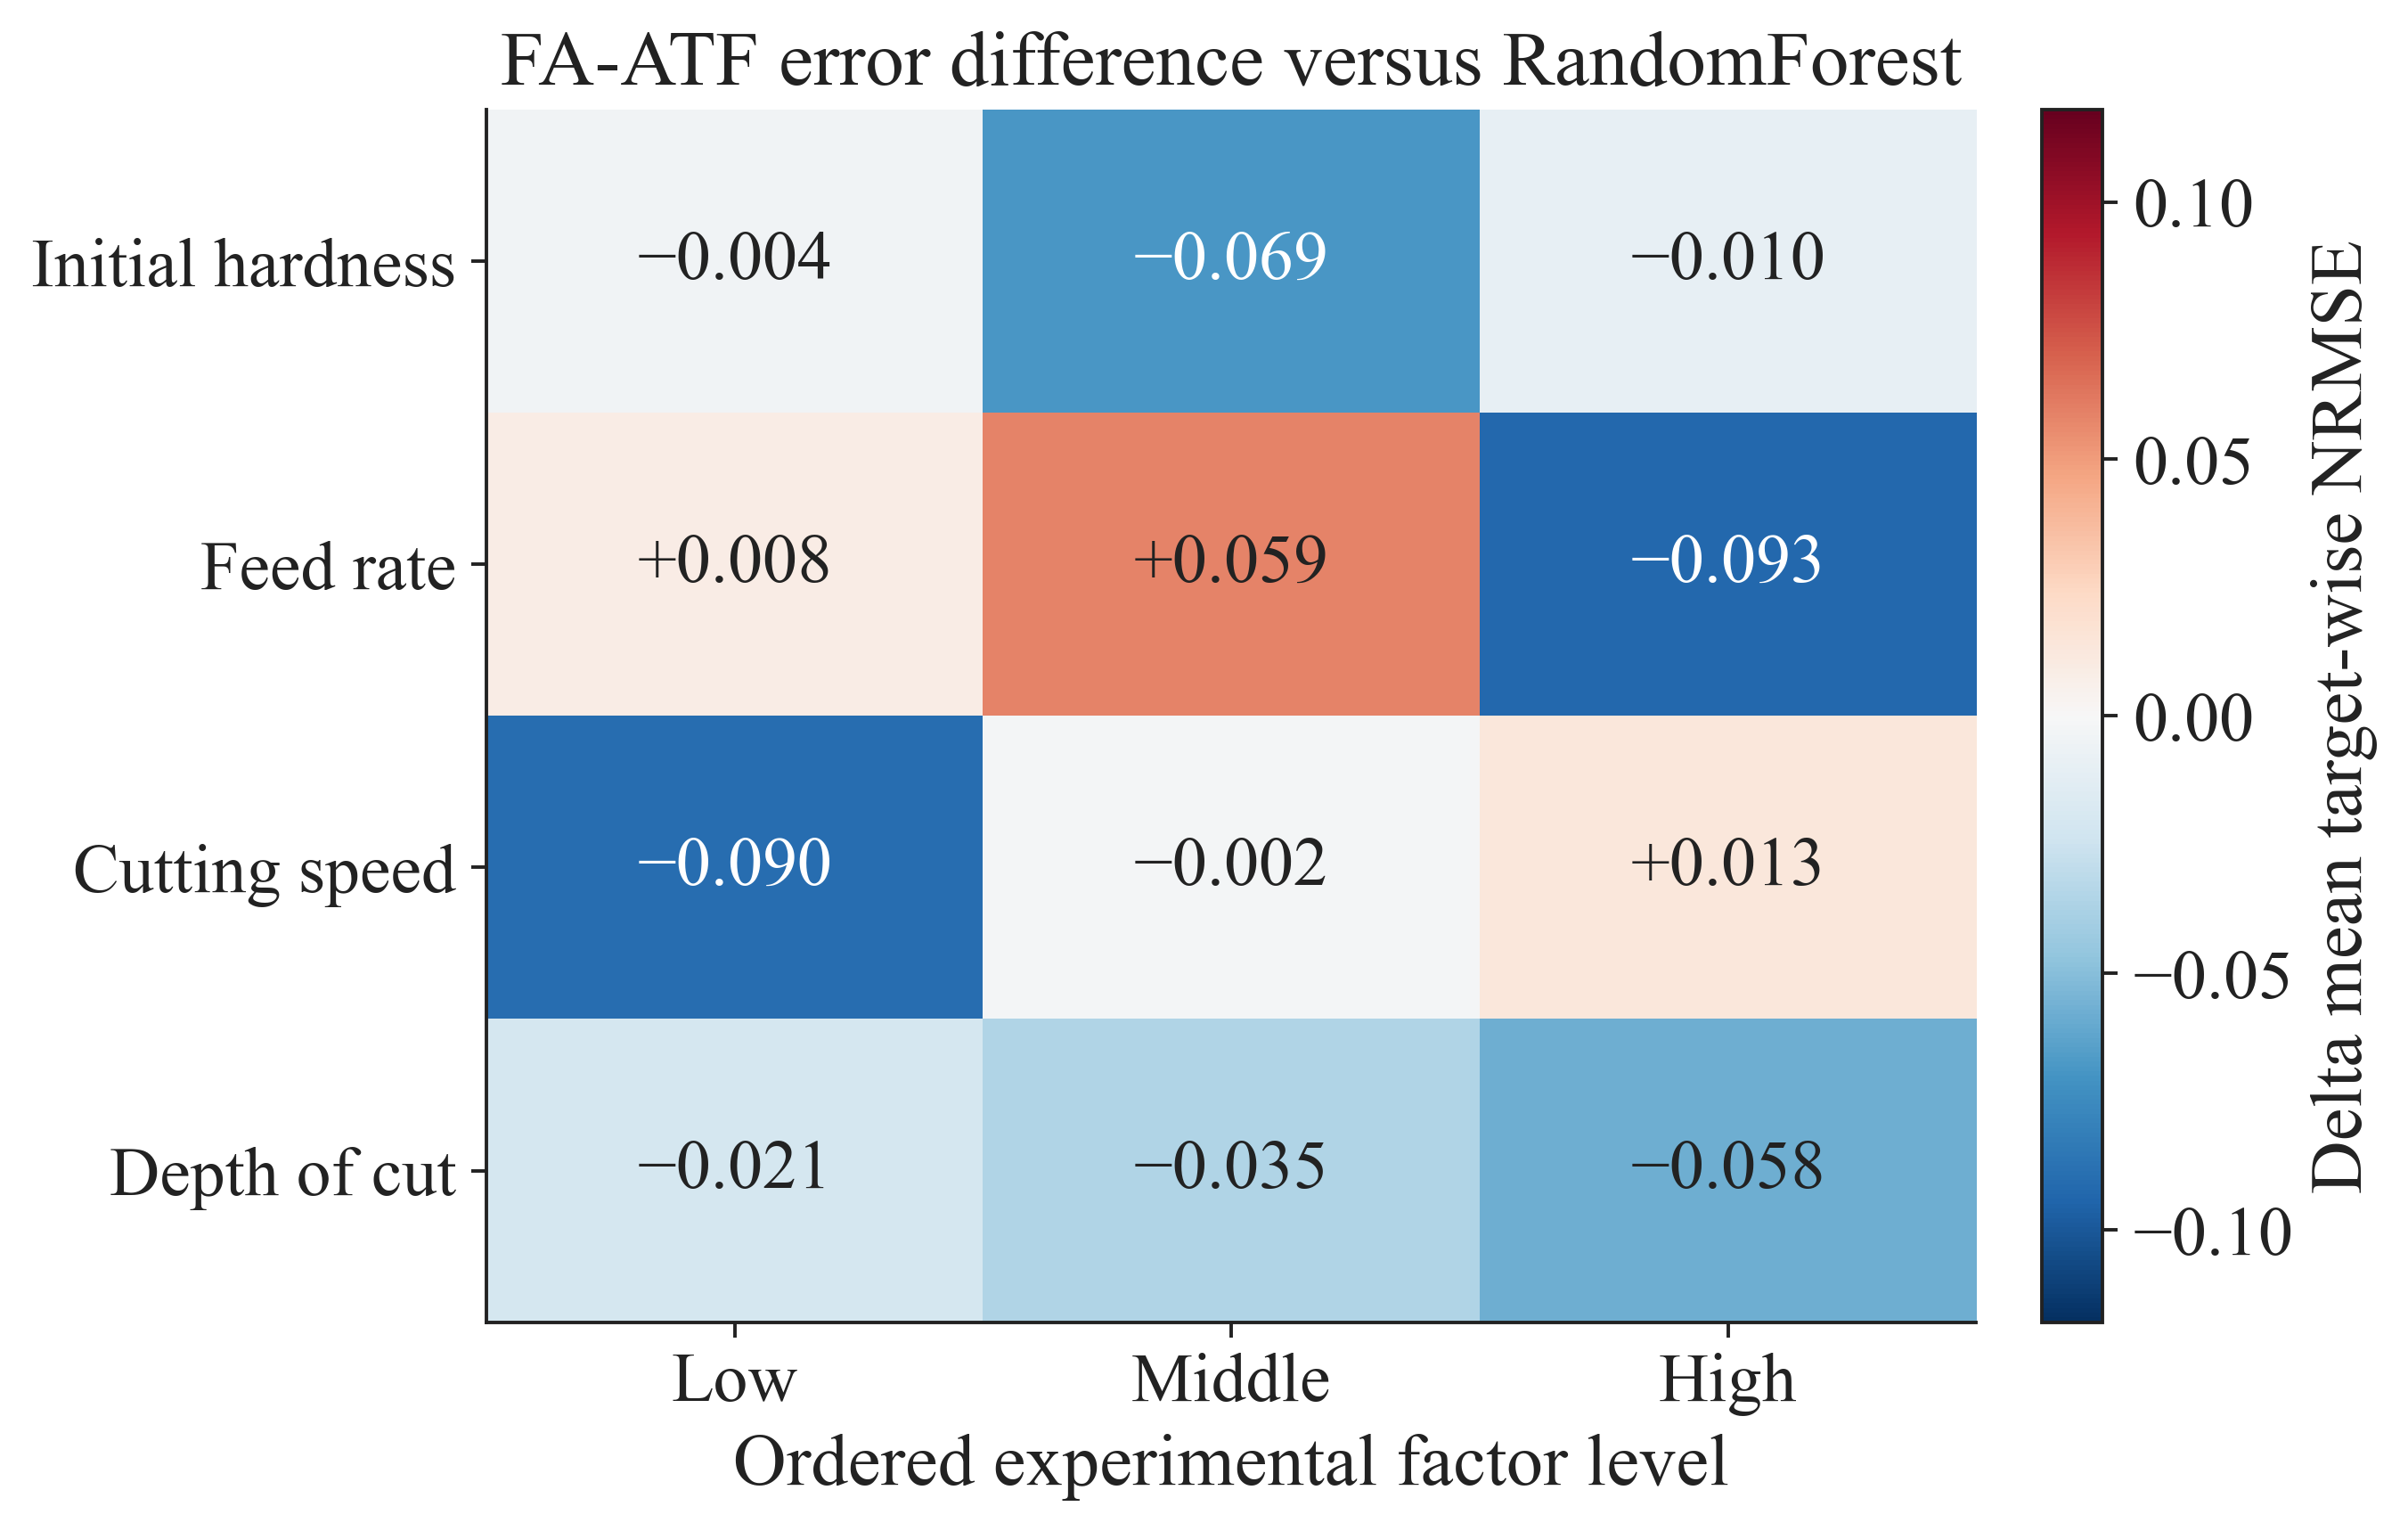

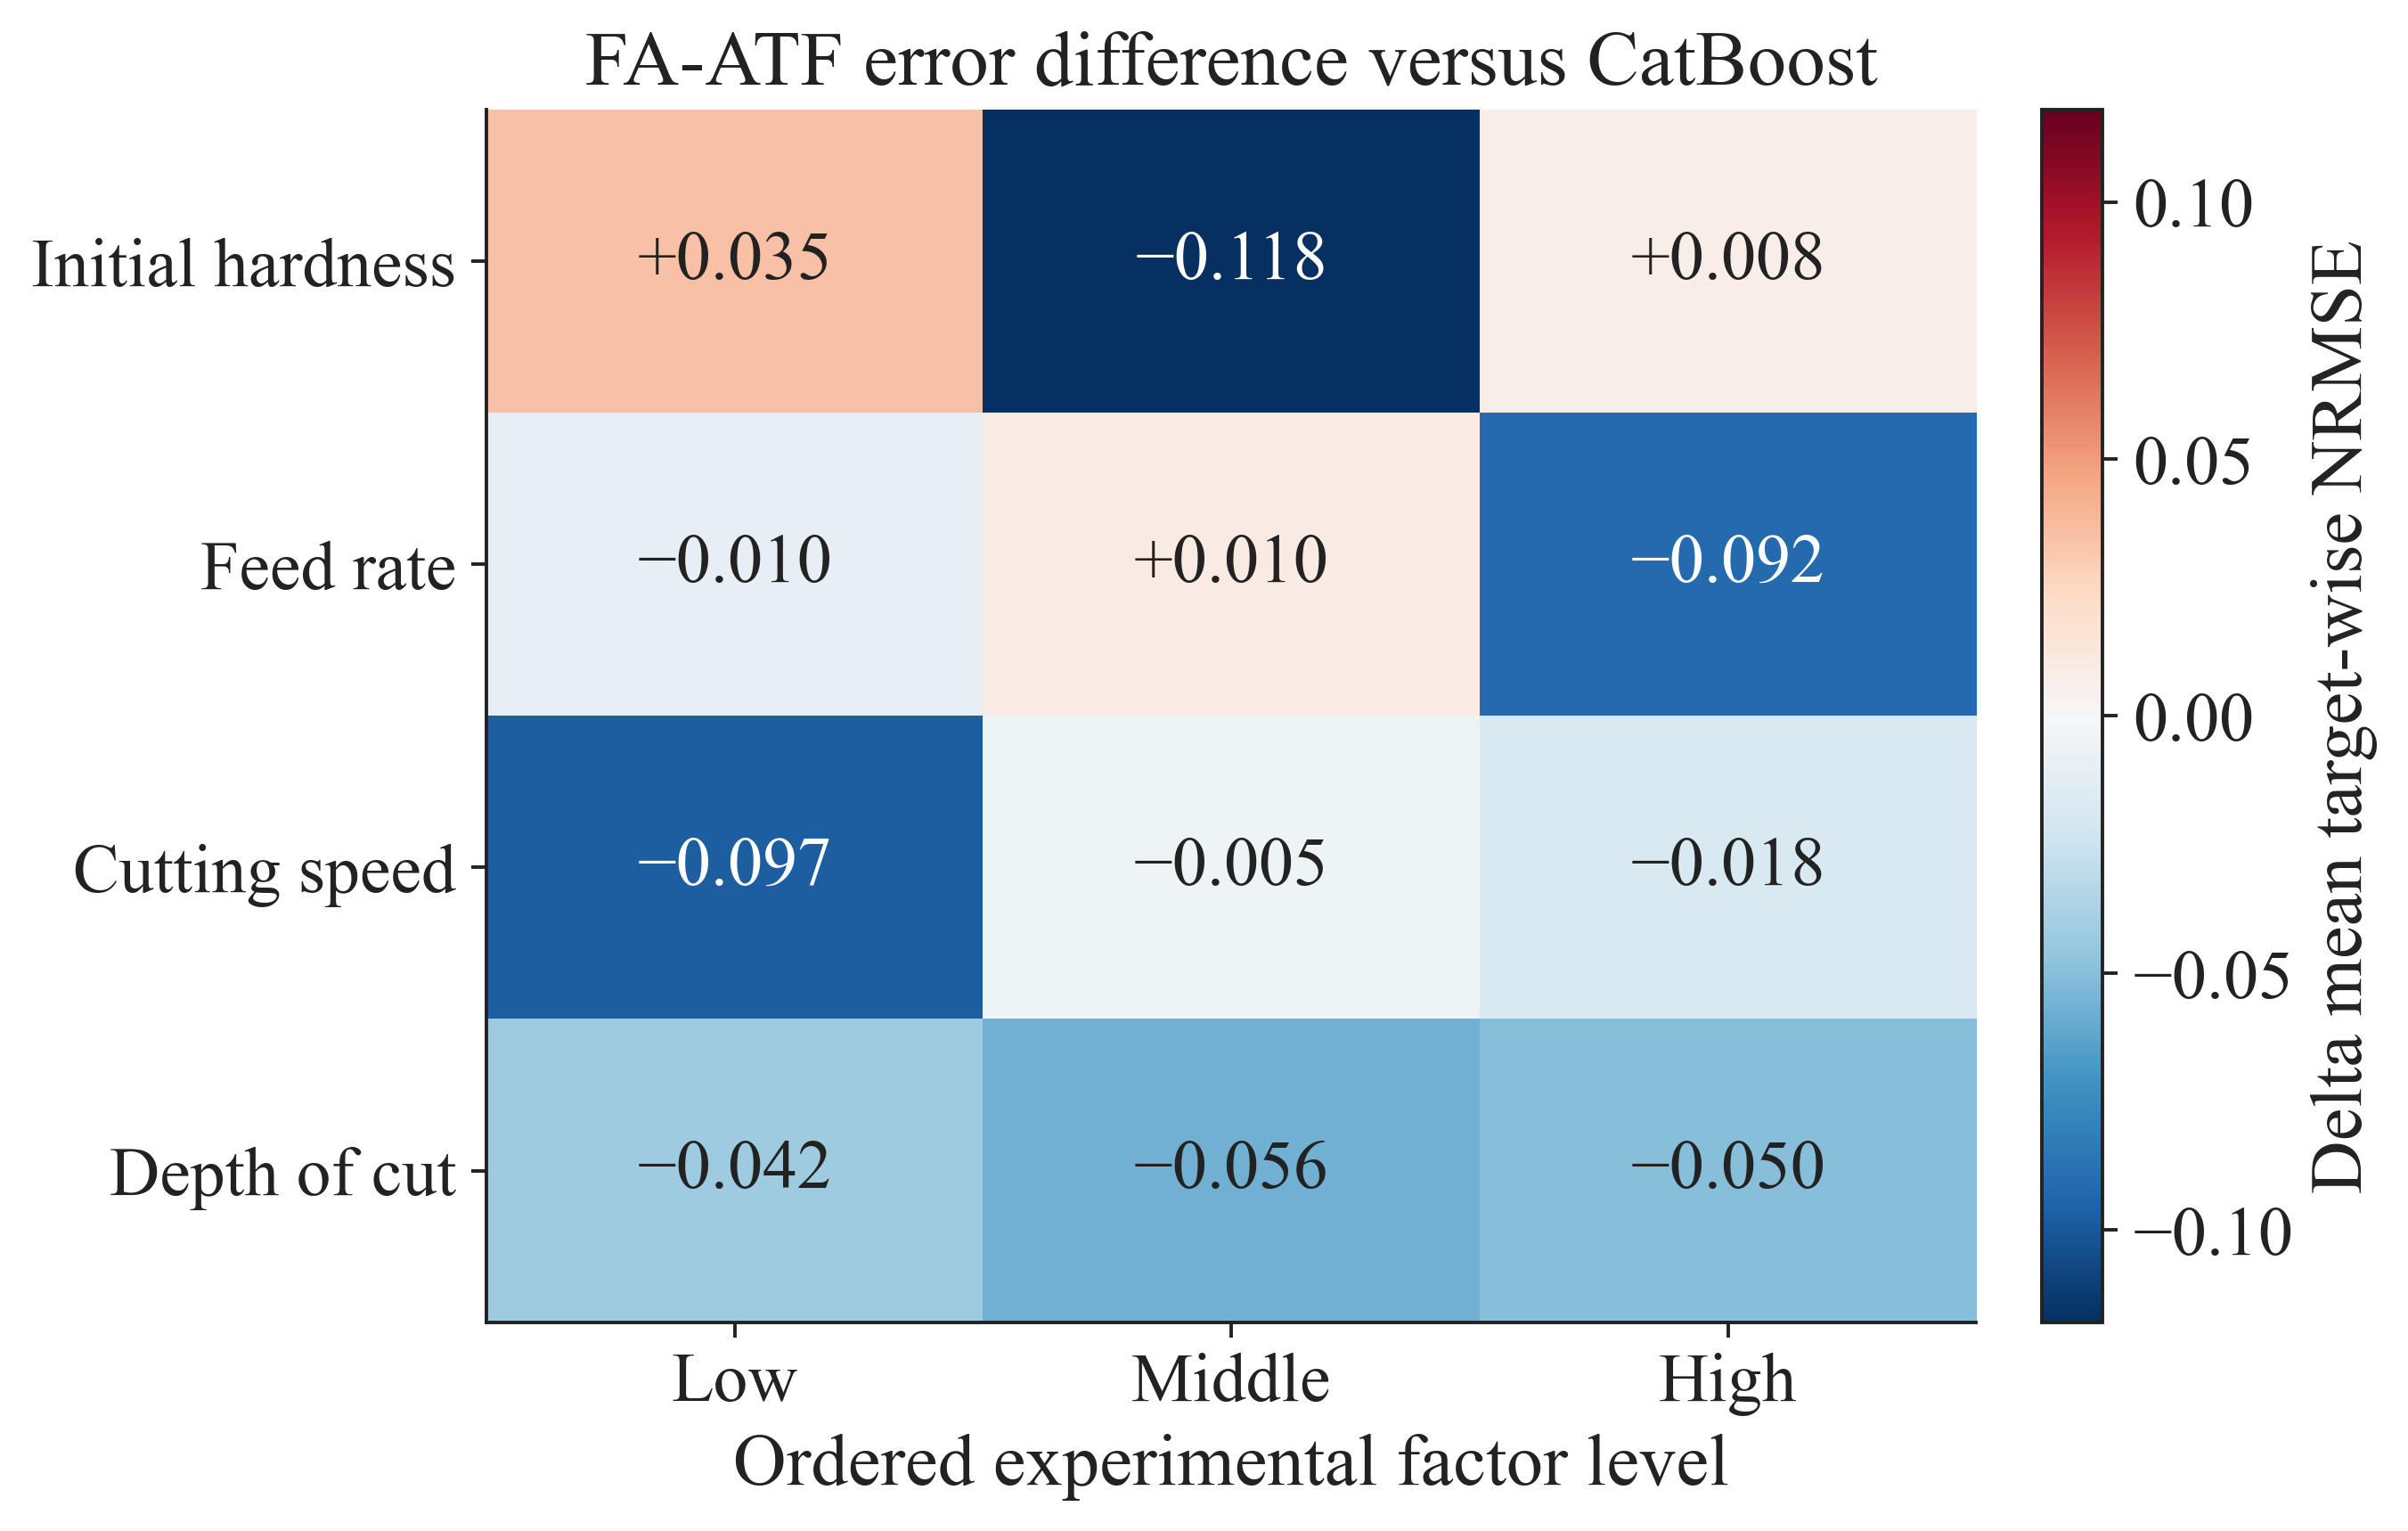

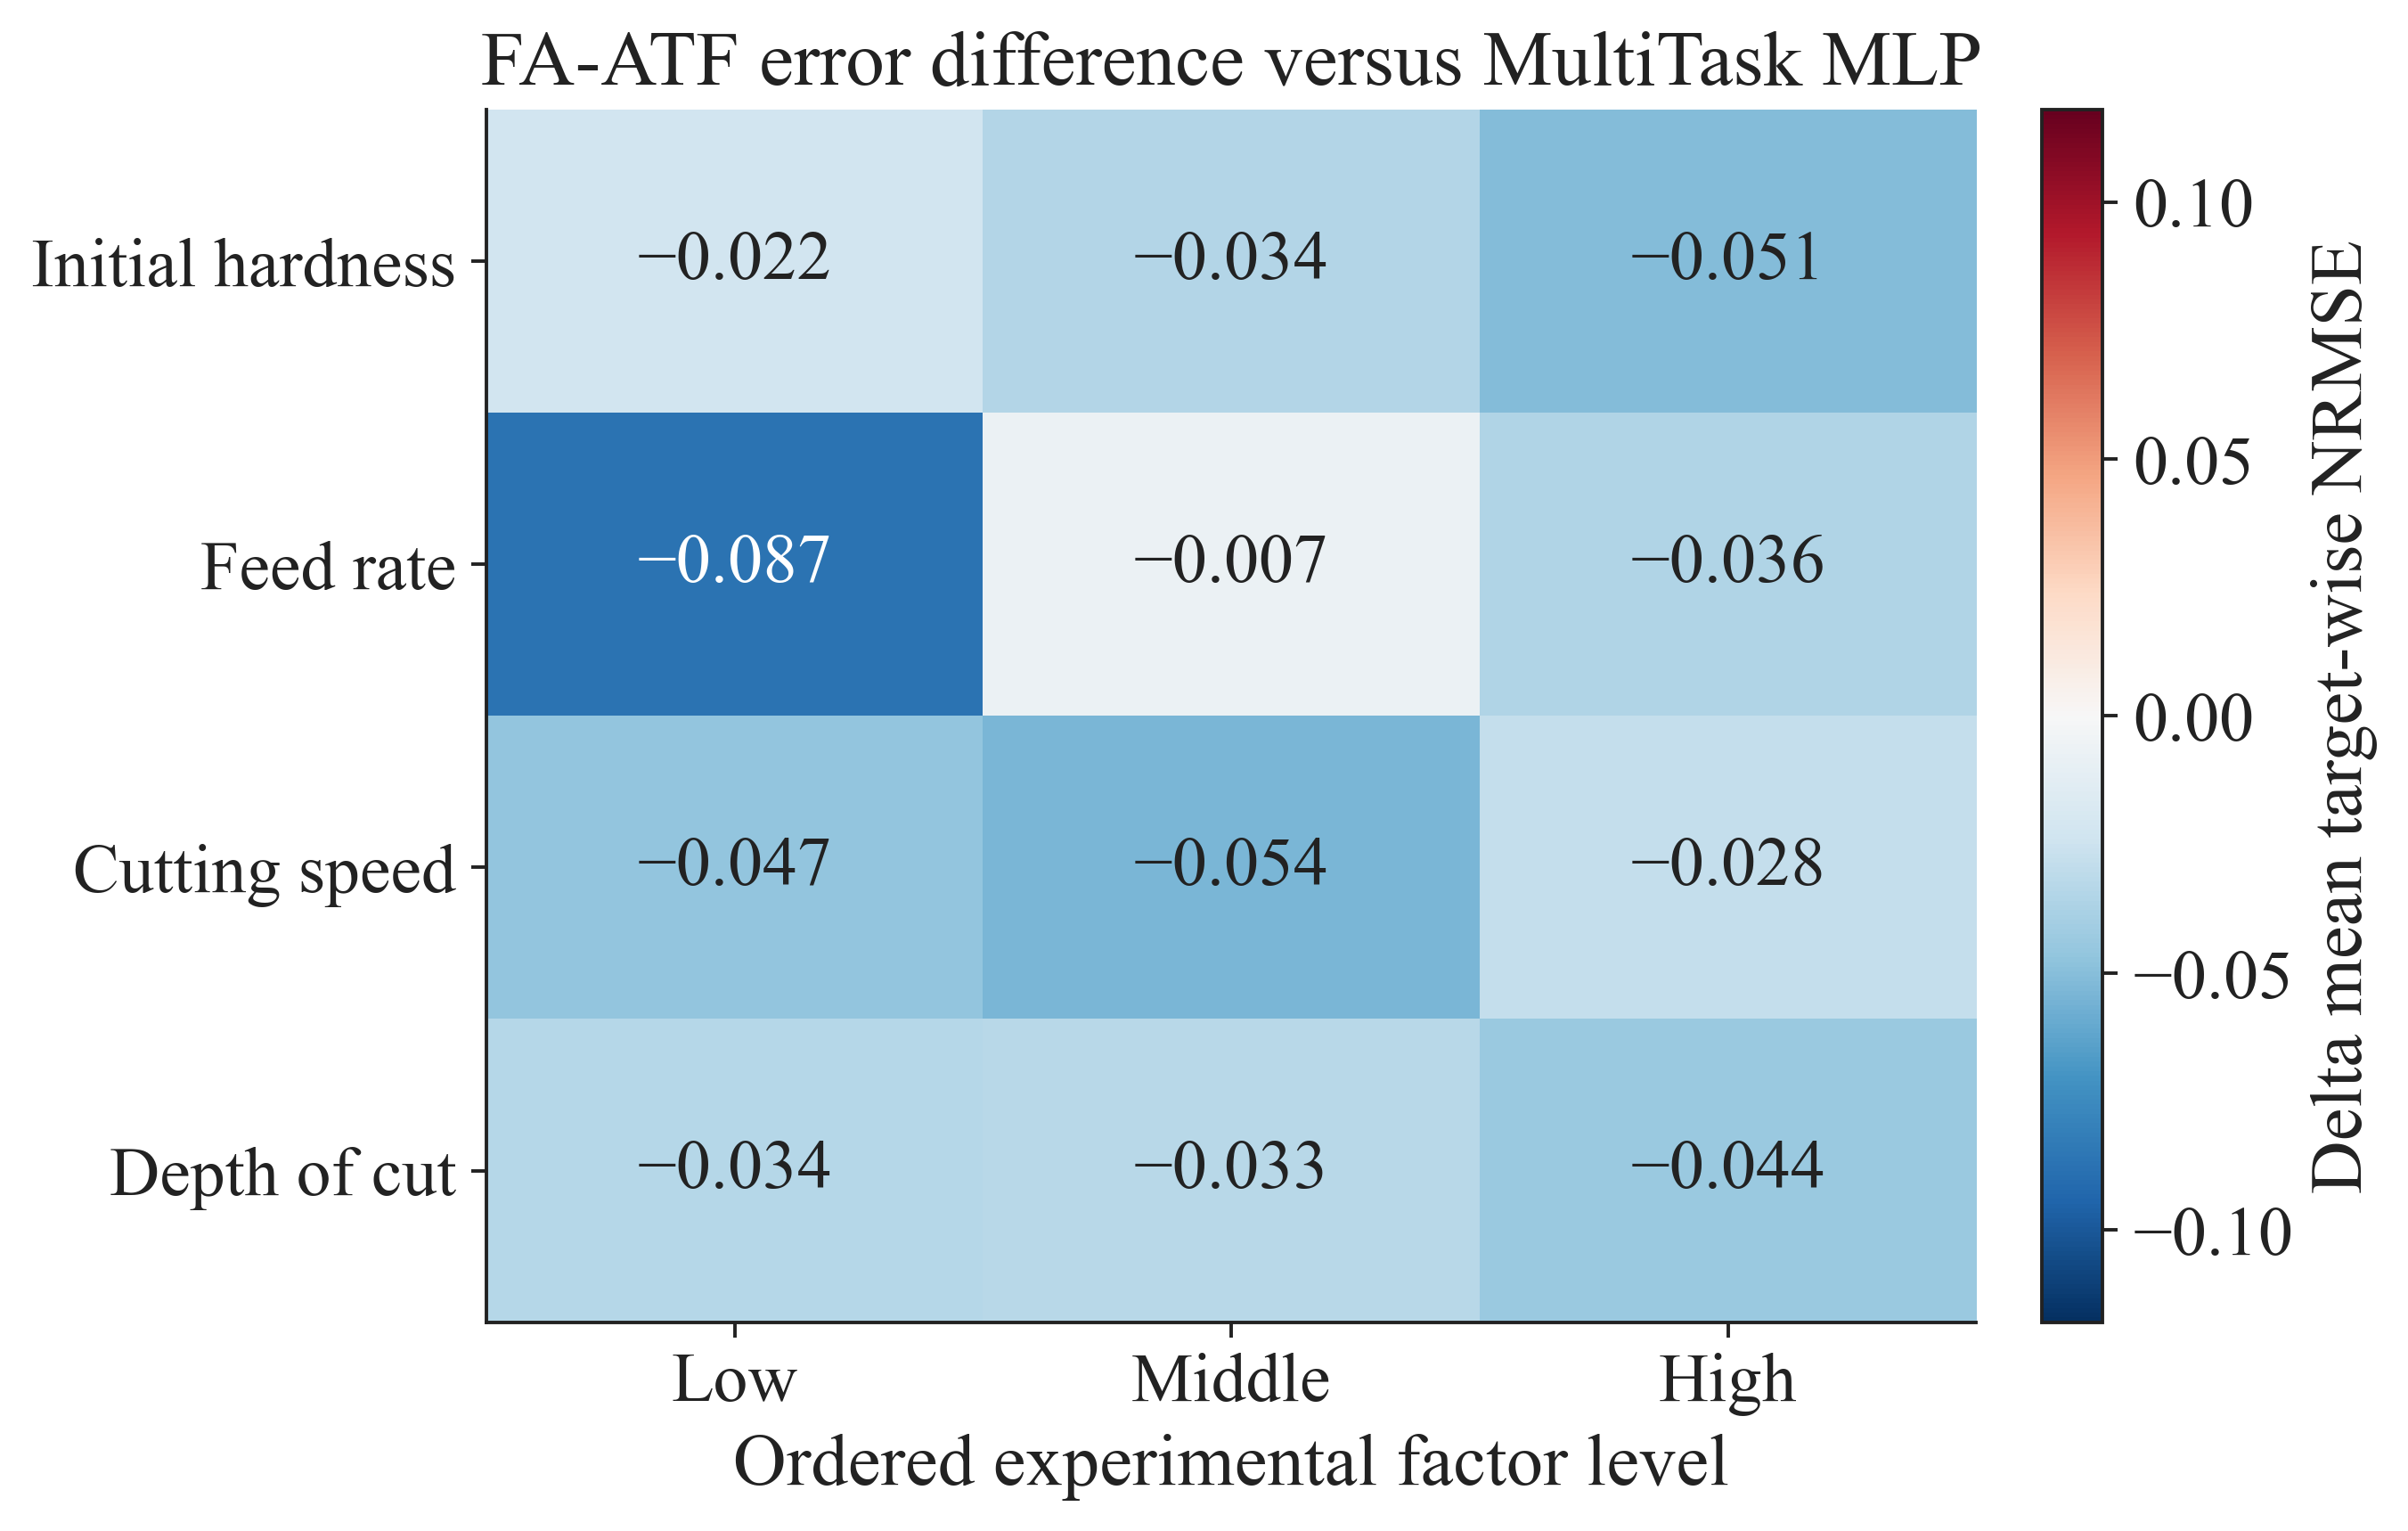

In [29]:
common_limit = factor_level_comparisons.delta_mean_targetwise_NRMSE.abs().max()
common_limit = max(common_limit, 0.01)
comparator_slugs = {
    best_baseline: "baseline",
    best_modern: "modern_classical",
    best_dl: "deep_learning",
}
for comparator in comparators:
    part = factor_level_comparisons[
        factor_level_comparisons.comparator.eq(comparator)
    ].copy()
    matrix = part.pivot(
        index="factor_label", columns="level_order",
        values="delta_mean_targetwise_NRMSE",
    ).reindex(index=[FACTOR_LABELS[factor] for factor in ROBUSTNESS_FACTORS], columns=[1, 2, 3])
    fig, axis = plt.subplots(figsize=(8.8, 5.8))
    image_map = axis.imshow(
        matrix.to_numpy(), cmap="RdBu_r", vmin=-common_limit, vmax=common_limit,
        aspect="auto",
    )
    axis.set_xticks(range(3), labels=["Low", "Middle", "High"])
    axis.set_yticks(range(len(matrix.index)), labels=matrix.index)
    axis.set_xlabel("Ordered experimental factor level")
    axis.set_ylabel("")
    axis.set_title(f"FA-ATF error difference versus {comparator}")
    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix.iloc[row_index, column_index]
            axis.text(
                column_index, row_index,
                format_scientific_number(value, decimals=3, show_plus=True),
                ha="center", va="center",
                color="white" if abs(value) > 0.55 * common_limit else PALETTE["black"],
            )
    colorbar = fig.colorbar(image_map, ax=axis, fraction=0.055, pad=0.04)
    colorbar.set_label("Delta mean target-wise NRMSE")
    axis.grid(False)
    fig.subplots_adjust(left=0.30, right=0.90, bottom=0.19, top=0.86)
    save_scientific_figure(
        fig, f"factor_level_delta_{comparator_slugs[comparator]}", part
    )
    display(fig)
    plt.close(fig)


In [30]:
factor_uncertainty = uncertainty.merge(
    data[["sample_id", *ROBUSTNESS_FACTORS]], on="sample_id", validate="many_to_one"
)
factor_uncertainty["covered"] = (
    (factor_uncertainty.y_true >= factor_uncertainty.lower_90)
    & (factor_uncertainty.y_true <= factor_uncertainty.upper_90)
)
factor_uncertainty["interval_width"] = (
    factor_uncertainty.upper_90 - factor_uncertainty.lower_90
)
coverage_factor_rows = []
coverage_rng = np.random.default_rng(SEED + 911)

for factor in ROBUSTNESS_FACTORS:
    for level, level_part in factor_uncertainty.groupby(factor):
        for target, target_part in level_part.groupby("target"):
            group_sizes = target_part.groupby("specimen_id").size()
            assert group_sizes.nunique() == 1
            group_statistics = target_part.groupby("specimen_id").agg(
                group_coverage=("covered", "mean"),
                group_width=("interval_width", "mean"),
            )
            bootstrap_indices = coverage_rng.integers(
                0, len(group_statistics), size=(FACTOR_BOOTSTRAPS, len(group_statistics))
            )
            bootstrap_coverage = group_statistics.group_coverage.to_numpy()[bootstrap_indices].mean(axis=1)
            bootstrap_width = group_statistics.group_width.to_numpy()[bootstrap_indices].mean(axis=1)
            coverage_factor_rows.append({
                "factor": factor, "factor_label": FACTOR_LABELS[factor],
                "level": level, "target": target,
                "observations": len(target_part), "specimens": len(group_statistics),
                "empirical_coverage": target_part.covered.mean(),
                "coverage_CI_low": np.quantile(bootstrap_coverage, 0.025),
                "coverage_CI_high": np.quantile(bootstrap_coverage, 0.975),
                "normalized_mean_width": target_part.interval_width.mean() / TARGET_SCALES[target],
                "normalized_width_CI_low": np.quantile(bootstrap_width, 0.025) / TARGET_SCALES[target],
                "normalized_width_CI_high": np.quantile(bootstrap_width, 0.975) / TARGET_SCALES[target],
                "cluster_bootstrap_resamples": FACTOR_BOOTSTRAPS,
            })

factor_conditional_coverage = pd.DataFrame(coverage_factor_rows)
worst_factor_coverage = (
    factor_conditional_coverage.sort_values("empirical_coverage")
    .groupby(["target", "factor"], as_index=False).first()
    .sort_values(["target", "factor"])
)
factor_conditional_coverage.to_csv(
    STATISTICS_DIR / "fa_atf_factor_level_conditional_coverage.csv", index=False
)
worst_factor_coverage.to_csv(
    STATISTICS_DIR / "fa_atf_worst_factor_coverage.csv", index=False
)
display_grouped_table(
    worst_factor_coverage.round(4), "Lowest conditional coverage at each factor"
)


**Lowest conditional coverage at each factor — Uncertainty and statistical evidence (part 1/2)**

target,factor,factor_label,level,empirical_coverage,coverage_CI_low,coverage_CI_high,normalized_width_CI_low,normalized_width_CI_high
post_process_hardness_HV30,HV_init_HV30,Initial hardness,600.000000,0.963000,0.888900,1.000000,1.508400,1.708200
post_process_hardness_HV30,cutting_speed_m_min,Cutting speed,175.000000,0.963000,0.888900,1.000000,1.556000,1.812900
post_process_hardness_HV30,depth_of_cut_mm,Depth of cut,0.250000,0.963000,0.888900,1.000000,1.546900,1.669300
post_process_hardness_HV30,feed_mm_rev,Feed rate,0.500000,0.963000,0.888900,1.000000,1.552000,1.793100
surface_roughness_Ra_um,HV_init_HV30,Initial hardness,500.000000,0.888900,0.666700,1.000000,2.907500,3.808000
surface_roughness_Ra_um,cutting_speed_m_min,Cutting speed,100.000000,0.888900,0.666700,1.000000,2.793500,3.651700
surface_roughness_Ra_um,depth_of_cut_mm,Depth of cut,0.250000,0.963000,0.888900,1.000000,3.142200,3.653500
surface_roughness_Ra_um,feed_mm_rev,Feed rate,0.500000,0.888900,0.666700,1.000000,2.606300,3.780400


**Lowest conditional coverage at each factor — Uncertainty and statistical evidence (part 2/2)**

target,factor,factor_label,level,cluster_bootstrap_resamples
post_process_hardness_HV30,HV_init_HV30,Initial hardness,600.000000,2000
post_process_hardness_HV30,cutting_speed_m_min,Cutting speed,175.000000,2000
post_process_hardness_HV30,depth_of_cut_mm,Depth of cut,0.250000,2000
post_process_hardness_HV30,feed_mm_rev,Feed rate,0.500000,2000
surface_roughness_Ra_um,HV_init_HV30,Initial hardness,500.000000,2000
surface_roughness_Ra_um,cutting_speed_m_min,Cutting speed,100.000000,2000
surface_roughness_Ra_um,depth_of_cut_mm,Depth of cut,0.250000,2000
surface_roughness_Ra_um,feed_mm_rev,Feed rate,0.500000,2000


**Lowest conditional coverage at each factor — Sample, fold, and provenance**

target,factor,factor_label,level,observations,specimens,normalized_mean_width
post_process_hardness_HV30,HV_init_HV30,Initial hardness,600.000000,27,9,1.603700
post_process_hardness_HV30,cutting_speed_m_min,Cutting speed,175.000000,27,9,1.689400
post_process_hardness_HV30,depth_of_cut_mm,Depth of cut,0.250000,27,27,1.603700
post_process_hardness_HV30,feed_mm_rev,Feed rate,0.500000,27,9,1.674500
surface_roughness_Ra_um,HV_init_HV30,Initial hardness,500.000000,27,9,3.402600
surface_roughness_Ra_um,cutting_speed_m_min,Cutting speed,100.000000,27,9,3.266800
surface_roughness_Ra_um,depth_of_cut_mm,Depth of cut,0.250000,27,27,3.402600
surface_roughness_Ra_um,feed_mm_rev,Feed rate,0.500000,27,9,3.193300


In [31]:
dl_levels = factor_level_summary.set_index("comparator").loc[best_dl, "levels_favoring_FA_ATF"]
baseline_levels = factor_level_summary.set_index("comparator").loc[best_baseline, "levels_favoring_FA_ATF"]
modern_levels = factor_level_summary.set_index("comparator").loc[best_modern, "levels_favoring_FA_ATF"]
display(Markdown(
    f"**Interpretation.** FA-ATF has the lower point NRMSE at {int(baseline_levels)}/12 observed "
    f"factor levels versus {best_baseline}, {int(modern_levels)}/12 versus {best_modern}, and "
    f"{int(dl_levels)}/12 versus {best_dl}. The factor-level confidence intervals expose regimes "
    "where differences remain uncertain; this conditional analysis prevents a favorable global "
    "average from being presented as uniform dominance."
))


**Interpretation.** FA-ATF has the lower point NRMSE at 9/12 observed factor levels versus RandomForest, 9/12 versus CatBoost, and 12/12 versus MultiTask MLP. The factor-level confidence intervals expose regimes where differences remain uncertain; this conditional analysis prevents a favorable global average from being presented as uniform dominance.

## 19. Test predictive skill against a specimen-profile permutation null

The permutation unit is the complete three-section specimen profile, not an individual row.
This preserves within-specimen dependence and asks whether the frozen OOF predictions are
more informative than randomly reassigned specimen profiles. It is a skill test, not a new
independent validation or a confirmatory superiority test.

In [32]:
N_PROFILE_PERMUTATIONS = 5000
permutation_rng = np.random.default_rng(SEED + 307)
permutation_test_rows = []

for target, part in robustness_predictions.groupby("target"):
    true_profiles = part.pivot(
        index="specimen_id", columns="depth_of_cut_mm", values="y_true"
    ).sort_index()
    predicted_profiles = part.pivot(
        index="specimen_id", columns="depth_of_cut_mm", values="y_pred"
    ).reindex(true_profiles.index)
    if true_profiles.isna().any().any() or predicted_profiles.isna().any().any():
        raise RuntimeError("A complete three-section specimen profile is required.")

    observed_nrmse = np.sqrt(np.mean(
        (true_profiles.to_numpy() - predicted_profiles.to_numpy()) ** 2
    )) / TARGET_SCALES[target]
    null_nrmse = np.empty(N_PROFILE_PERMUTATIONS)
    predicted_array = predicted_profiles.to_numpy()
    true_array = true_profiles.to_numpy()
    for permutation_index in range(N_PROFILE_PERMUTATIONS):
        permuted_prediction = predicted_array[permutation_rng.permutation(len(predicted_array))]
        null_nrmse[permutation_index] = np.sqrt(
            np.mean((true_array - permuted_prediction) ** 2)
        ) / TARGET_SCALES[target]

    permutation_test_rows.append({
        "target": target, "specimen_profiles": len(true_profiles),
        "sections_per_profile": true_profiles.shape[1],
        "observed_NRMSE": float(observed_nrmse),
        "null_median_NRMSE": float(np.median(null_nrmse)),
        "null_2_5_percentile": float(np.quantile(null_nrmse, 0.025)),
        "null_97_5_percentile": float(np.quantile(null_nrmse, 0.975)),
        "one_sided_permutation_p": float(
            (1 + np.sum(null_nrmse <= observed_nrmse)) / (N_PROFILE_PERMUTATIONS + 1)
        ),
    })

profile_permutation_test = pd.DataFrame(permutation_test_rows)
profile_permutation_test.to_csv(
    STATISTICS_DIR / "fa_atf_specimen_profile_permutation_test.csv", index=False
)
display_grouped_table(profile_permutation_test.round(4), "Specimen-profile permutation skill test")

**Specimen-profile permutation skill test — Predictive performance**

target,observed_NRMSE,null_median_NRMSE
post_process_hardness_HV30,0.336600,1.346700
surface_roughness_Ra_um,0.418000,1.330600


**Specimen-profile permutation skill test — Uncertainty and statistical evidence**

target,specimen_profiles,sections_per_profile,null_2_5_percentile,null_97_5_percentile,one_sided_permutation_p
post_process_hardness_HV30,27,3,1.072200,1.570000,0.000200
surface_roughness_Ra_um,27,3,1.031500,1.552100,0.000200


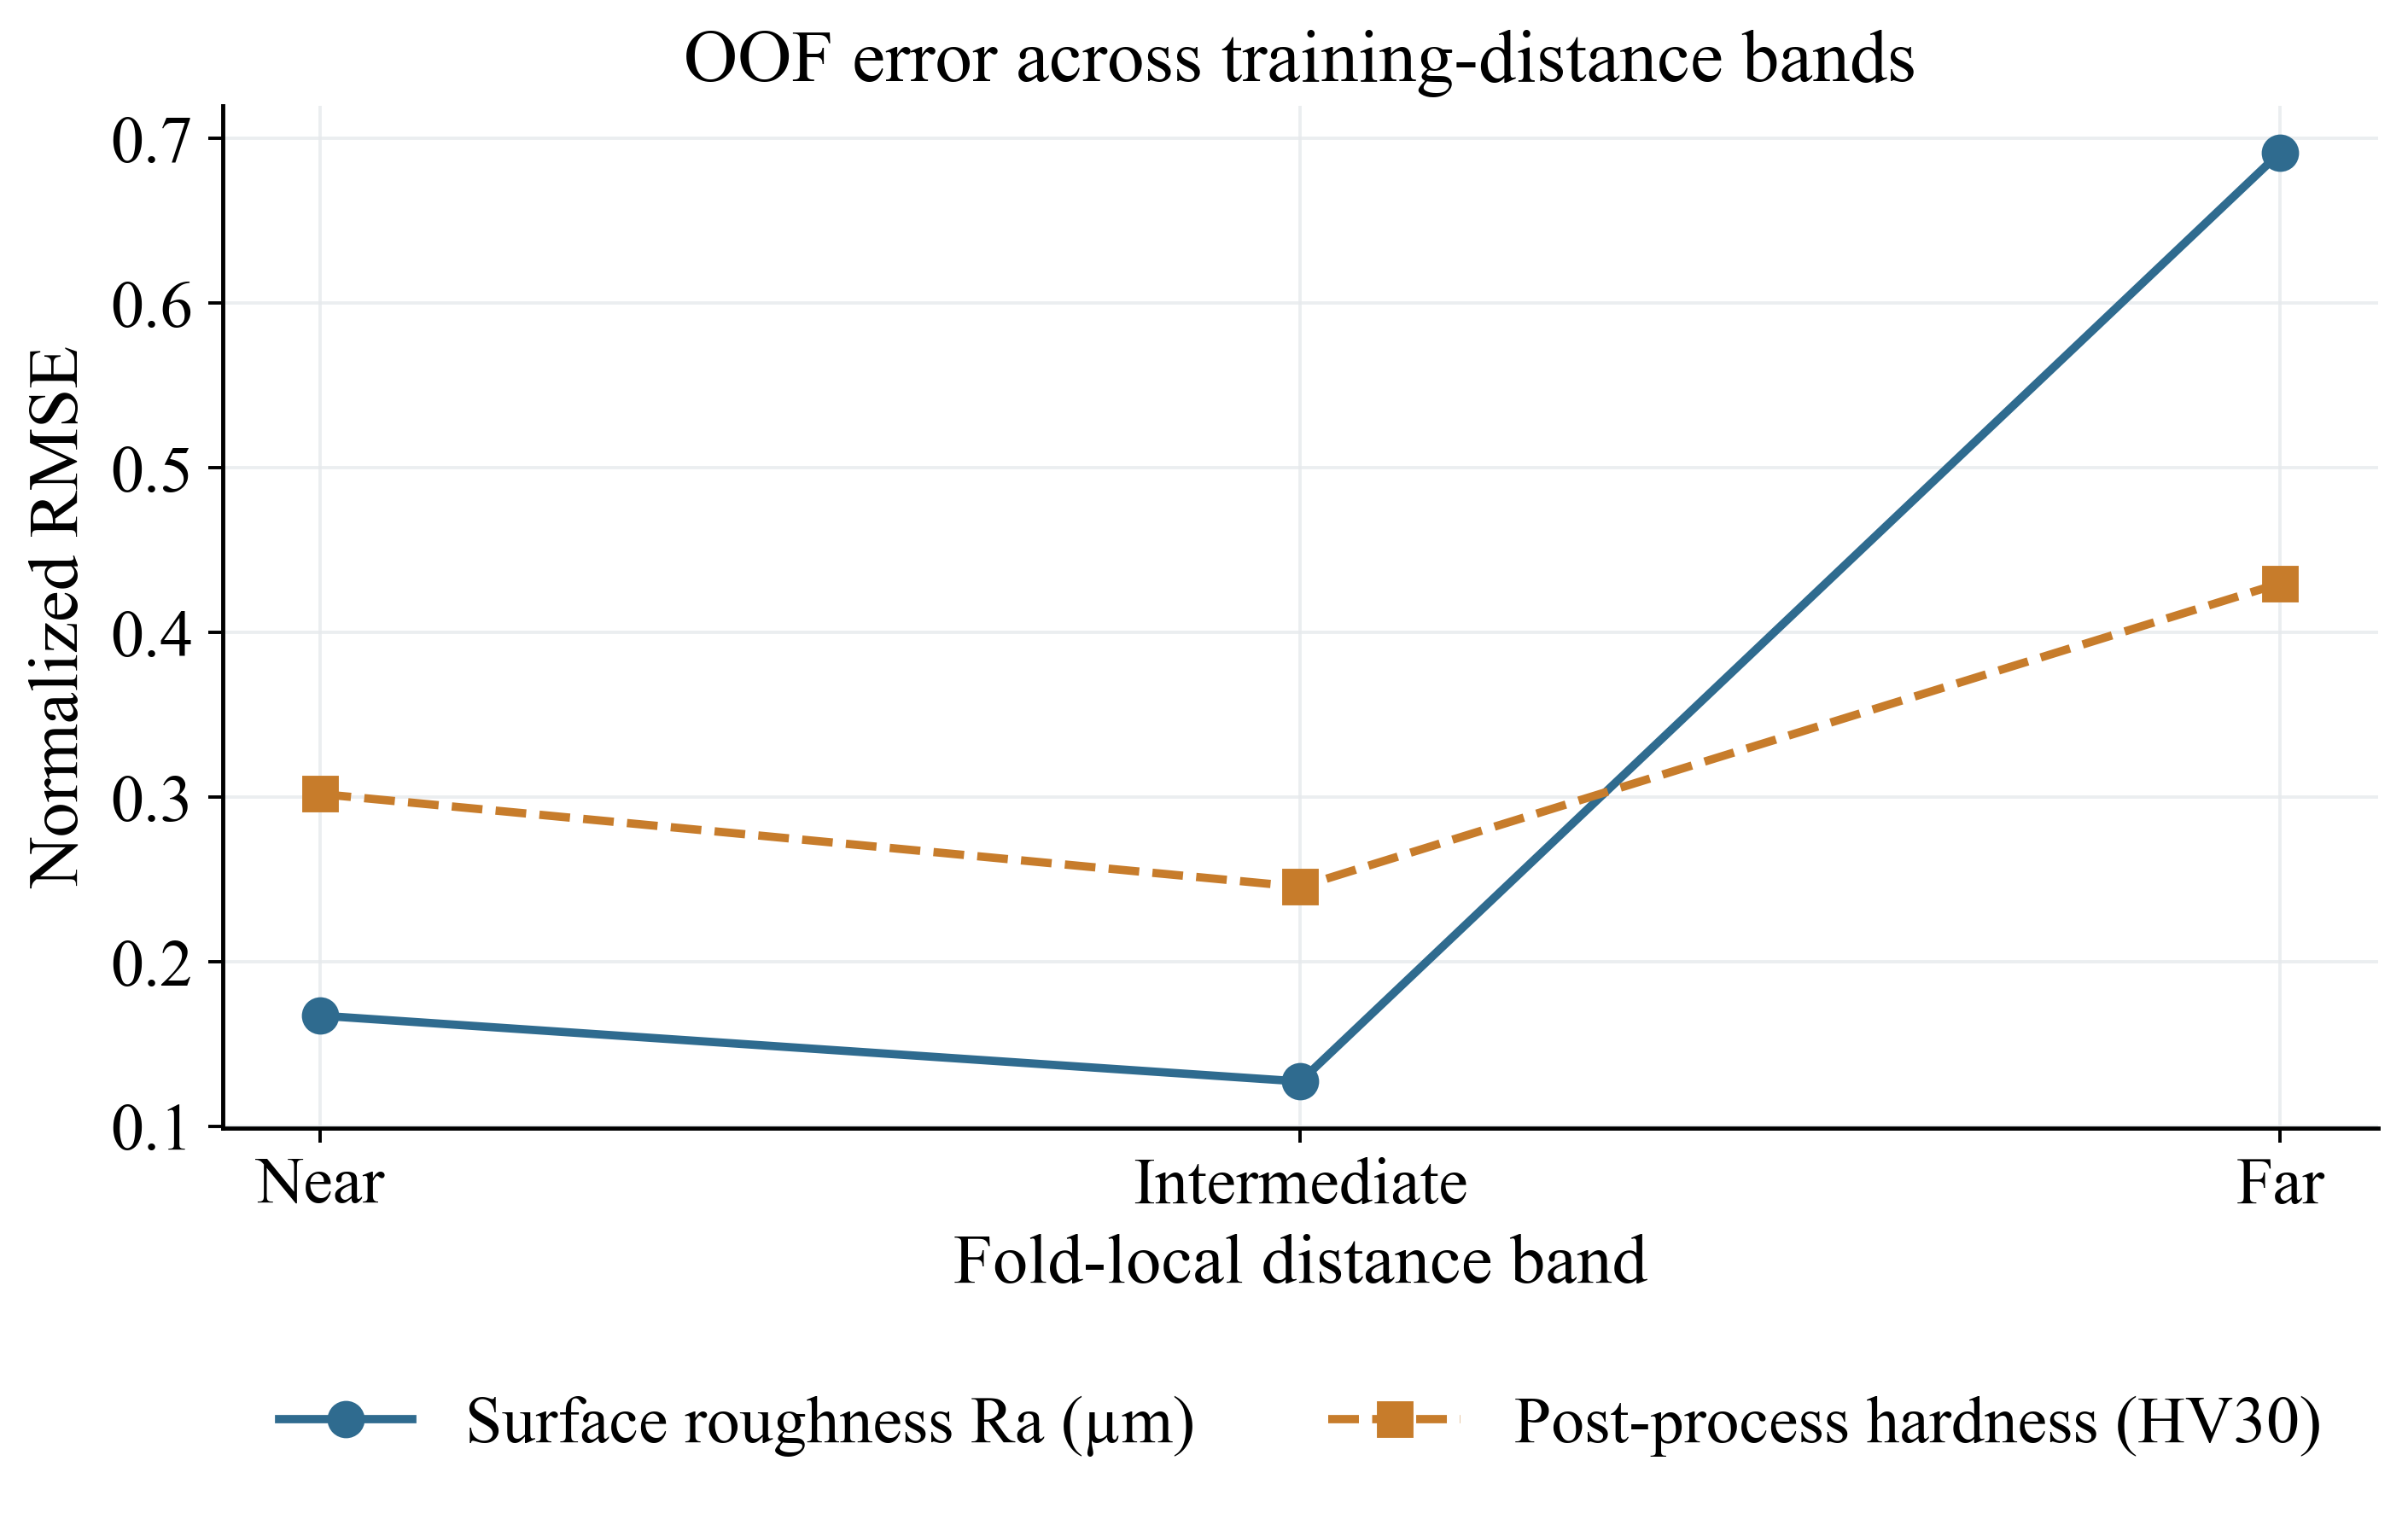

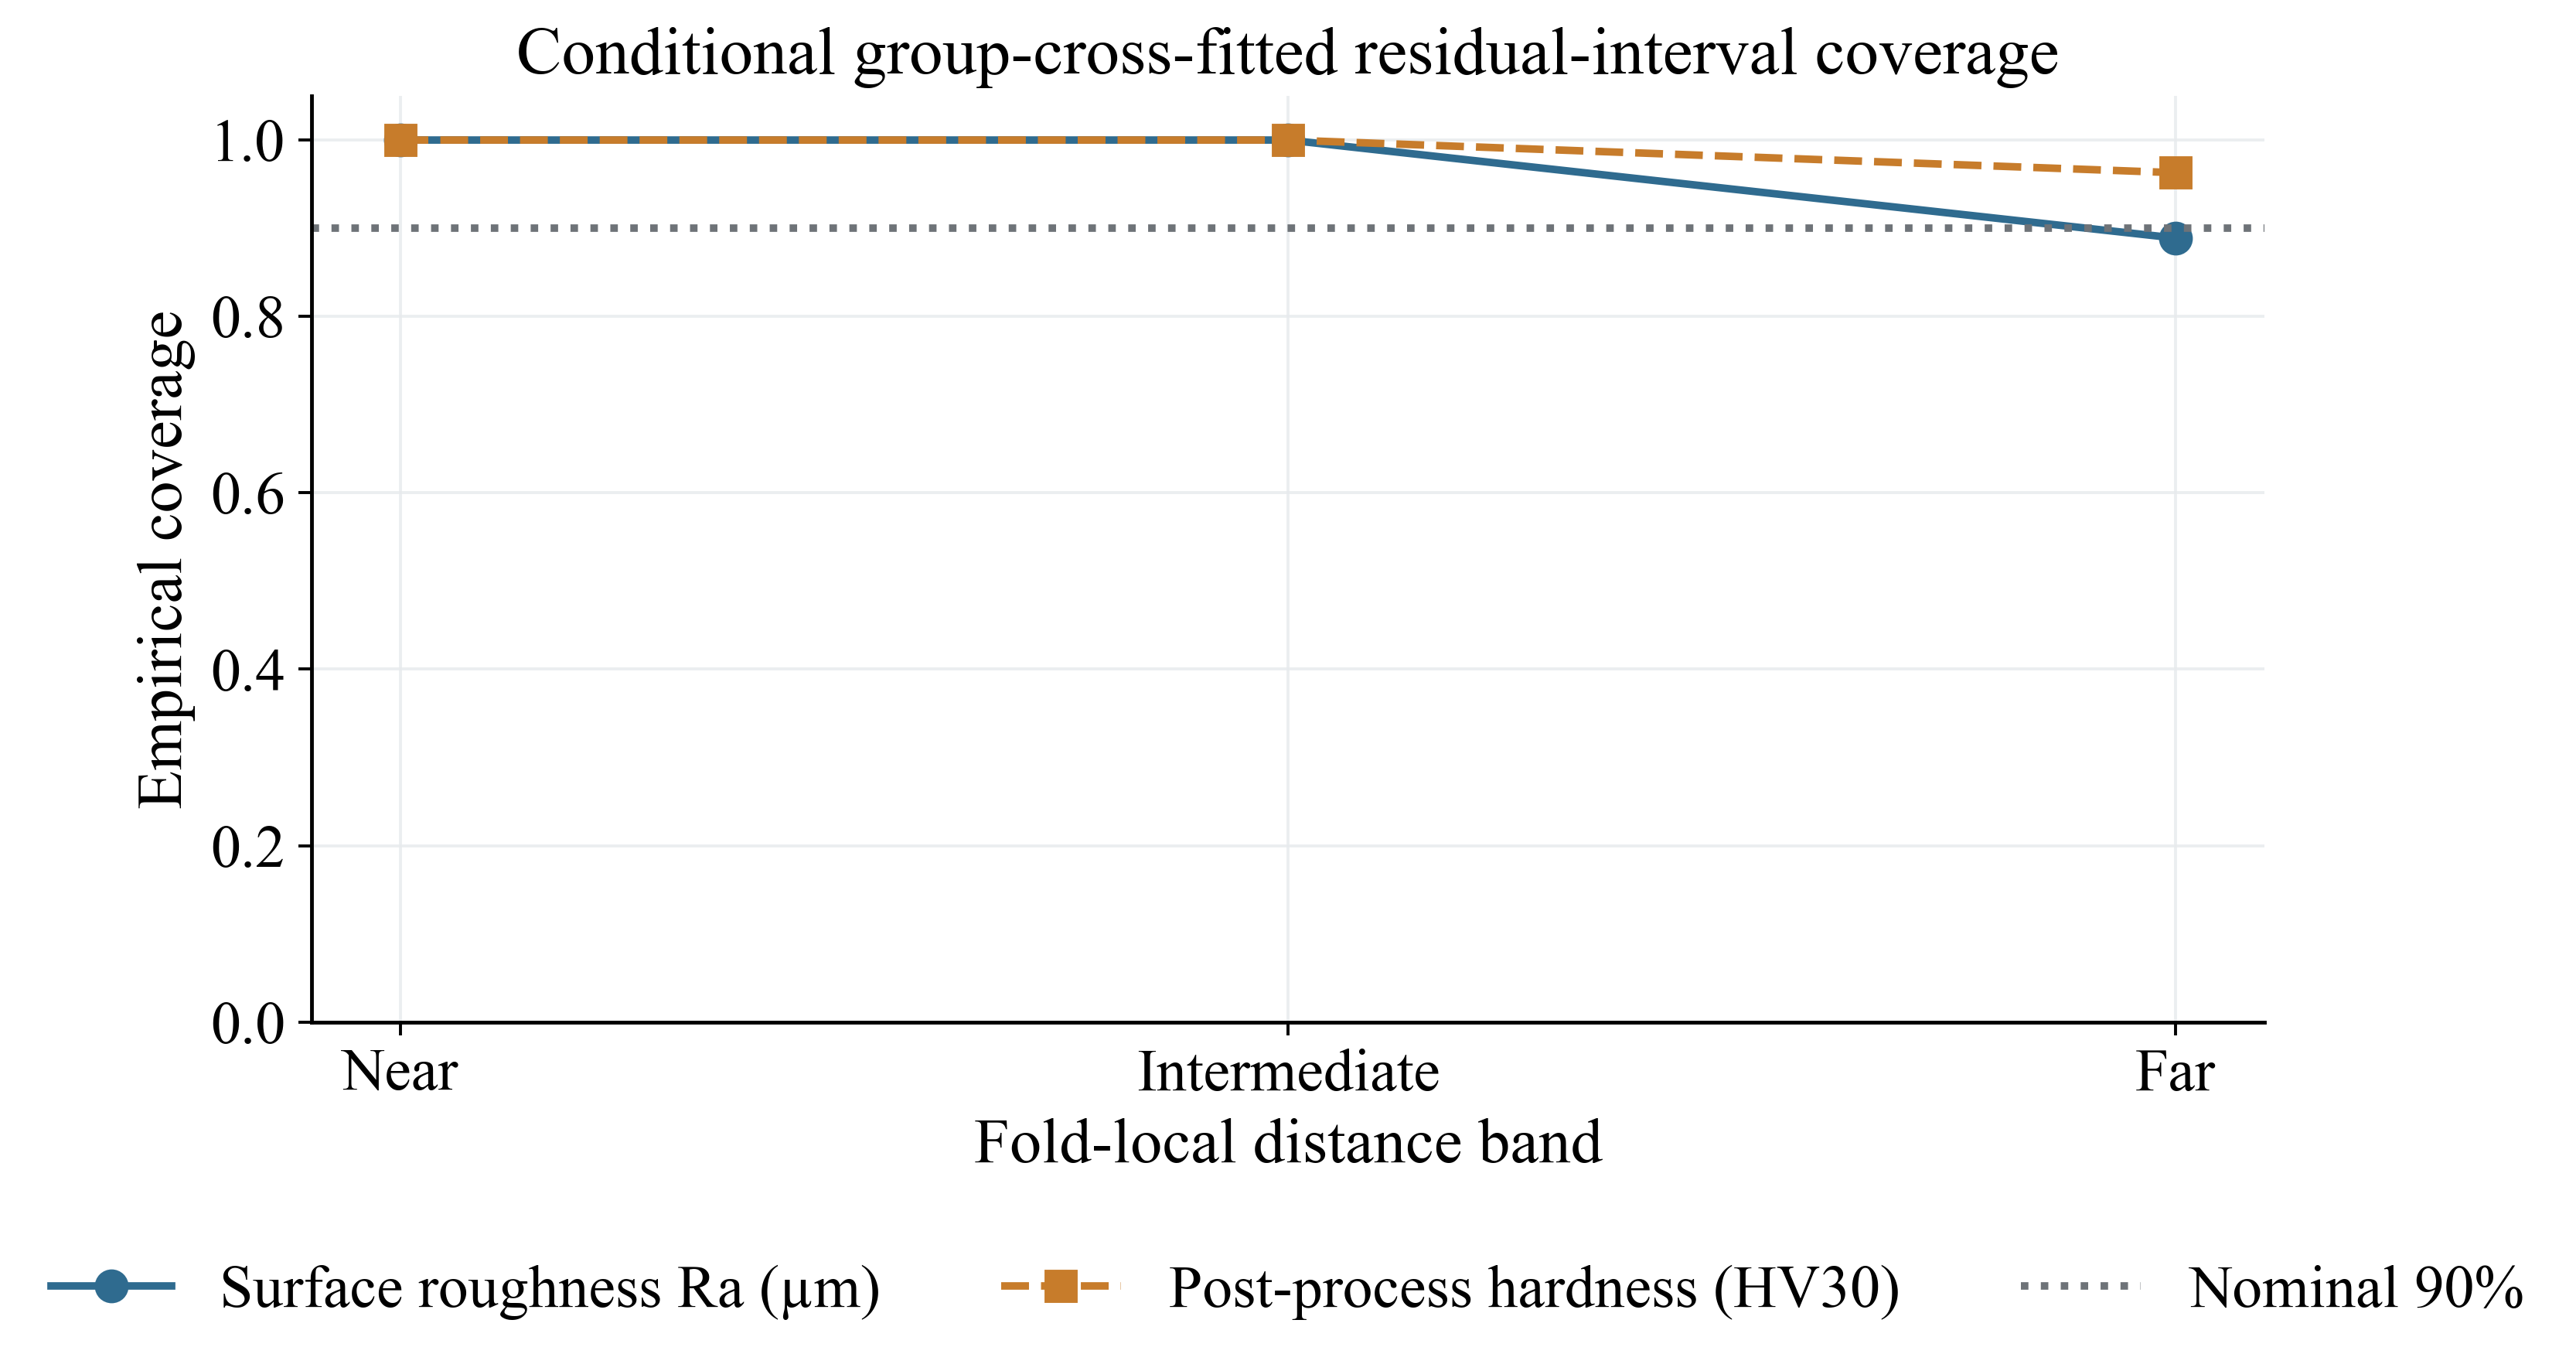

In [33]:
distance_order = ["Near", "Intermediate", "Far"]
target_styles = {
    TARGETS[0]: (PALETTE["blue"], "o", "-"),
    TARGETS[1]: (PALETTE["orange"], "s", "--"),
}
robustness_figure_source = domain_shift_metrics.merge(
    conditional_coverage[
        ["target", "distance_band", "empirical_coverage", "normalized_mean_width"]
    ], on=["target", "distance_band"], validate="one_to_one"
)

fig, axis = plt.subplots(figsize=(8.8, 5.8))
for target in TARGETS:
    color, marker, linestyle = target_styles[target]
    metric_part = domain_shift_metrics[domain_shift_metrics.target.eq(target)].set_index("distance_band").reindex(distance_order)
    axis.plot(distance_order, metric_part.NRMSE, marker=marker, markersize=8,
              color=color, linestyle=linestyle, label=TARGET_LABELS[target])
axis.set_title("OOF error across training-distance bands")
axis.set_xlabel("Fold-local distance band")
axis.set_ylabel("Normalized RMSE")
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=2, frameon=False)
fig.subplots_adjust(left=0.16, right=0.98, top=0.88, bottom=0.29)
save_scientific_figure(fig, "domain_shift_oof_error", robustness_figure_source)
display(fig)
plt.close(fig)

fig, axis = plt.subplots(figsize=(8.8, 5.8))
for target in TARGETS:
    color, marker, linestyle = target_styles[target]
    coverage_part = conditional_coverage[conditional_coverage.target.eq(target)].set_index("distance_band").reindex(distance_order)
    axis.plot(distance_order, coverage_part.empirical_coverage, marker=marker, markersize=8,
              color=color, linestyle=linestyle, label=TARGET_LABELS[target])
axis.axhline(0.90, color=PALETTE["gray"], linestyle=":", label="Nominal 90%")
axis.set_title("Conditional group-cross-fitted residual-interval coverage")
axis.set_xlabel("Fold-local distance band")
axis.set_ylabel("Empirical coverage")
axis.set_ylim(0.0, 1.05)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=3, frameon=False)
fig.subplots_adjust(left=0.16, right=0.98, top=0.88, bottom=0.29)
save_scientific_figure(fig, "domain_shift_conditional_coverage", robustness_figure_source)
display(fig)
plt.close(fig)

## 20. Synthesize the final evidence category

In [34]:
fa_rank = int(ranking.index[ranking.model.eq("FA-ATF")][0] + 1)
fa_comparisons = paired.copy()
if fa_rank == 1 and (fa_comparisons.bootstrap_CI_high < 0).all() and (fa_comparisons.wilcoxon_p_Holm < 0.05).all():
    superiority_status = "SUPPORTED_WITHIN_EXPLORATORY_NESTED_CV"
elif fa_rank == 1:
    superiority_status = "INCONCLUSIVE"
else:
    superiority_status = "NO_CONFIRMED_SUPERIORITY"

fa_row = ranking.set_index("model").loc["FA-ATF"]
fa_rank_stability = rank_stability.set_index("model").loc["FA-ATF"]
loo_all_favorable = bool(
    (loo_summary.omissions_favoring_FA_ATF == loo_summary.omitted_specimens).all()
)
minimum_adjusted_sign_flip = sign_flip.one_sided_sign_flip_p_Holm.min()
factor_summary_text = "; ".join(
    f"{row.comparator}: {int(row.levels_favoring_FA_ATF)}/{int(row.factor_levels)} levels"
    for row in factor_level_summary.itertuples()
)
alternative_fa = alternative_split_summary.set_index('model').loc['FA-ATF']
alternative_split_text = (
    f"mean NRMSE {alternative_fa.mean_NRMSE_across_assignments:.4f} ± "
    f"{alternative_fa.SD_NRMSE_across_assignments:.4f} across "
    f"{int(alternative_fa.split_seeds)} pre-specified assignments; "
    f"median rank {alternative_fa.median_rank:.1f}"
)

conclusion_table = pd.DataFrame([
    {"Scientific conclusion": "Best observed dimensionless point estimate", "Computed evidence": f"{ranking.iloc[0].model}: mean NRMSE {ranking.iloc[0].mean_NRMSE:.4f}"},
    {"Scientific conclusion": "FA-ATF rank", "Computed evidence": f"{fa_rank} of {len(ranking)} models"},
    {"Scientific conclusion": "FA-ATF dimensionless performance", "Computed evidence": f"Mean target-wise NRMSE {fa_row.mean_NRMSE:.4f}; macro R² {fa_row.macro_R2:.4f}"},
    {"Scientific conclusion": "Cluster-bootstrap rank stability", "Computed evidence": f"P(rank 1)={fa_rank_stability.probability_rank_1:.3f}; median rank {fa_rank_stability.median_bootstrap_rank:.0f}; 95% rank interval {fa_rank_stability.rank_95pct_low:.0f}–{fa_rank_stability.rank_95pct_high:.0f}"},
    {"Scientific conclusion": "Single-specimen influence", "Computed evidence": "FA-ATF remains lower than all focal comparators for all 27 omissions" if loo_all_favorable else "At least one omission changes a focal comparison"},
    {"Scientific conclusion": "Specimen-level randomization", "Computed evidence": f"Smallest Holm-adjusted one-sided p={minimum_adjusted_sign_flip:.4f}"},
    {"Scientific conclusion": "Observed-regime robustness", "Computed evidence": factor_summary_text},
    {"Scientific conclusion": "Alternative specimen-split stability", "Computed evidence": alternative_split_text},
    {"Scientific conclusion": "Comparative evidence category", "Computed evidence": superiority_status},
    {"Scientific conclusion": "Independent validation", "Computed evidence": "Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified"},
    {"Scientific conclusion": "Claim boundary", "Computed evidence": "Internally robust point advantage within exploratory nested CV; no universal deployment claim"},
])
display_grouped_table(conclusion_table, "Evidence-bounded final synthesis")


**Evidence-bounded final synthesis — Complete table**

Scientific conclusion,Computed evidence
Best observed dimensionless point estimate,FA-ATF: mean NRMSE 0.3773
FA-ATF rank,1 of 18 models
FA-ATF dimensionless performance,Mean target-wise NRMSE 0.3773; macro R² 0.8542
Cluster-bootstrap rank stability,P(rank 1)=0.831; median rank 1; 95% rank interval 1–5
Single-specimen influence,FA-ATF remains lower than all focal comparators for all 27 omissions
Specimen-level randomization,Smallest Holm-adjusted one-sided p=0.0577
Observed-regime robustness,CatBoost: 9/12 levels; MultiTask MLP: 12/12 levels; RandomForest: 9/12 levels
Alternative specimen-split stability,mean NRMSE 0.4271 ± 0.0090 across 5 pre-specified assignments; median rank 1.0
Comparative evidence category,INCONCLUSIVE
Independent validation,Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified


## Final limitation

The complete balanced hierarchical split-plot factorial grid, alternative specimen-split assignments, cluster bootstrap, rank stability, sign-flip tests, leave-one-specimen influence analysis, regime-wise comparisons, conditional coverage, and profile permutation test provide a strong internal robustness layer. They remain evaluations of the same 27 physical specimens and cannot replace independent validation.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. The appropriate conclusion is an internally stable FA-ATF point advantage with `INCONCLUSIVE` confirmatory superiority unless all multiplicity-adjusted paired criteria are met. Full confirmation requires newly machined compatible specimens with paired `Ra`, post-process `HV30`, and specimen-profile measurements collected after freezing the prediction and analysis protocol.
